#1: Configuration and continuity checkpoint

In [1]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 1: Configuration and experiment checkpoint
# ============================================================

import os
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch


# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


# ------------------------------------------------------------
# Fixed model / cache configuration
# ------------------------------------------------------------

MODEL_NAME = "Qwen/Qwen2.5-1.5B"

PAGE_SIZE = 16

CACHE_TOKENS = 2048

NUM_PAGES = (
    CACHE_TOKENS // PAGE_SIZE
)

SENSITIVITY_HORIZON = 128


# ------------------------------------------------------------
# Notebook 07 decision timing
#
# Notebook 06's best high-sensitivity predictor used
# TWO future pages of attention.
#
# Therefore:
#
# 2 pages * 16 tokens/page = 32-token decision delay
# ------------------------------------------------------------

DECISION_DELAY_PAGES = 2

DECISION_DELAY_TOKENS = (
    DECISION_DELAY_PAGES
    * PAGE_SIZE
)


# ------------------------------------------------------------
# Precision hierarchy
# ------------------------------------------------------------

HIGH_PRECISION = "FP16"

DEFAULT_PRECISION = "INT8"

LOW_PRECISION_SCHEMES = [
    "INT4_per_page",
    "INT4_per_vector",
    "INT4_kv_aware",
]

# Primary INT4 scheme entering Notebook 07
PRIMARY_INT4_SCHEME = (
    "INT4_per_vector"
)


# ------------------------------------------------------------
# Original Notebook 05 candidate region
# ------------------------------------------------------------

ORIGINAL_CANDIDATE_START = 6
ORIGINAL_CANDIDATE_END = 120


# ------------------------------------------------------------
# Delay-aligned candidate region
#
# A target page requires:
#
#   target page
#   + 2 observation pages
#   + 128-token future evaluation horizon
#
# We will calculate the exact valid range once the
# experiment token stream is loaded.
# ------------------------------------------------------------

CANDIDATE_PAGE_START = (
    ORIGINAL_CANDIDATE_START
)


# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ------------------------------------------------------------
# Notebook 06 reference results
# ------------------------------------------------------------

NB6_HIGH_ORACLE_THRESHOLD = 0.30

NB6_LOW_ORACLE_THRESHOLD = 0.15

NB6_BEST_HIGH_MODEL = (
    "Delayed_2pages / GradientBoosting"
)

NB6_HIGH_OOF_AUC = 0.744729

NB6_HIGH_OOF_AP = 0.479790

NB6_LOW_OOF_AUC = 0.541667

NB6_LOW_OOF_AP = 0.423519


# ------------------------------------------------------------
# New signal families planned for Notebook 07
# ------------------------------------------------------------

SIGNAL_FAMILIES = [

    "immediate_attention",

    "delayed_attention",

    "confidence",

    "position",

    # New Notebook 07 family
    "quantization_aware",
]


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert PAGE_SIZE == 16

assert NUM_PAGES == 128

assert DECISION_DELAY_TOKENS == 32


# ------------------------------------------------------------
# Print checkpoint
# ------------------------------------------------------------

print("Notebook 07 configuration")
print("-------------------------")

print(f"Model:                  {MODEL_NAME}")

print(f"Device:                 {DEVICE}")

print(f"Cache tokens:           {CACHE_TOKENS}")

print(f"Page size:              {PAGE_SIZE}")

print(f"Logical pages:          {NUM_PAGES}")

print(
    f"Decision delay:         "
    f"{DECISION_DELAY_PAGES} pages "
    f"({DECISION_DELAY_TOKENS} tokens)"
)

print(
    f"Sensitivity horizon:    "
    f"{SENSITIVITY_HORIZON} tokens"
)

print()

print("Precision hierarchy")
print("-------------------")

print(
    f"High sensitivity:       "
    f"{HIGH_PRECISION}"
)

print(
    f"Default / uncertain:    "
    f"{DEFAULT_PRECISION}"
)

print(
    f"Primary low precision:  "
    f"{PRIMARY_INT4_SCHEME}"
)

print(
    f"INT4 schemes available: "
    f"{LOW_PRECISION_SCHEMES}"
)

print()

print("Notebook 06 checkpoint")
print("----------------------")

print(
    f"High classifier:        "
    f"{NB6_BEST_HIGH_MODEL}"
)

print(
    f"High OOF ROC-AUC:       "
    f"{NB6_HIGH_OOF_AUC:.4f}"
)

print(
    f"Low OOF ROC-AUC:        "
    f"{NB6_LOW_OOF_AUC:.4f}"
)

print()

print("Notebook 07 primary goal")
print("------------------------")

print(
    "Align the sensitivity oracle with the 32-token "
    "decision delay, then test whether inference-time "
    "and quantization-aware signals can support an "
    "actual FP16 / INT8 / INT4 adaptive policy."
)

Notebook 07 configuration
-------------------------
Model:                  Qwen/Qwen2.5-1.5B
Device:                 cuda
Cache tokens:           2048
Page size:              16
Logical pages:          128
Decision delay:         2 pages (32 tokens)
Sensitivity horizon:    128 tokens

Precision hierarchy
-------------------
High sensitivity:       FP16
Default / uncertain:    INT8
Primary low precision:  INT4_per_vector
INT4 schemes available: ['INT4_per_page', 'INT4_per_vector', 'INT4_kv_aware']

Notebook 06 checkpoint
----------------------
High classifier:        Delayed_2pages / GradientBoosting
High OOF ROC-AUC:       0.7447
Low OOF ROC-AUC:        0.5417

Notebook 07 primary goal
------------------------
Align the sensitivity oracle with the 32-token decision delay, then test whether inference-time and quantization-aware signals can support an actual FP16 / INT8 / INT4 adaptive policy.


#2: Load the exact Notebook 05 model/data environment

In [2]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 2: Recreate Notebook 05 Model/Data Environment
#        (corrected after runtime restart)
# ============================================================

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import math

from tqdm.auto import tqdm

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    DynamicCache,
)

from datasets import load_dataset


# ------------------------------------------------------------
# Compatibility names from Notebook 05
# ------------------------------------------------------------

MODEL_ID = MODEL_NAME
DTYPE = torch.float16
EVAL_TOKENS = CACHE_TOKENS


# ------------------------------------------------------------
# Exact Notebook 05 protected-region configuration
# ------------------------------------------------------------

NUM_PROTECTED_FP16 = 13
NUM_PREFIX_FP16 = 6
NUM_RECENT_FP16 = 7

CANDIDATE_PAGE_START = NUM_PREFIX_FP16

CANDIDATE_PAGE_END = (
    NUM_PAGES
    - NUM_RECENT_FP16
    - 1
)

CANDIDATE_PAGES = list(
    range(
        CANDIDATE_PAGE_START,
        CANDIDATE_PAGE_END + 1,
    )
)


assert CANDIDATE_PAGE_START == 6
assert CANDIDATE_PAGE_END == 120
assert len(CANDIDATE_PAGES) == 115


# ------------------------------------------------------------
# GPU
# ------------------------------------------------------------

print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError("GPU runtime required.")

gpu = torch.cuda.get_device_properties(0)

print("GPU:", gpu.name)

print(
    f"VRAM: "
    f"{gpu.total_memory / 1024**3:.2f} GiB"
)


# ------------------------------------------------------------
# Load Qwen using Notebook 05 quality-evaluation settings
#
# FP16 + SDPA
# ------------------------------------------------------------

print("\nLoading:", MODEL_ID)

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    dtype=DTYPE,
    device_map={"": 0},
    low_cpu_mem_usage=True,
    attn_implementation="sdpa",
)

model.eval()


# ------------------------------------------------------------
# Architecture
# ------------------------------------------------------------

config = model.config

NUM_LAYERS = config.num_hidden_layers

NUM_ATTENTION_HEADS = (
    config.num_attention_heads
)

NUM_KV_HEADS = getattr(
    config,
    "num_key_value_heads",
    NUM_ATTENTION_HEADS,
)

HEAD_DIM = getattr(
    config,
    "head_dim",
    config.hidden_size
    // NUM_ATTENTION_HEADS,
)


# ------------------------------------------------------------
# WikiText-2
# ------------------------------------------------------------

print("\nLoading WikiText-2...")

test_dataset = load_dataset(
    "Salesforce/wikitext",
    "wikitext-2-raw-v1",
    split="test",
)

test_text = "\n\n".join(
    test_dataset["text"]
)

encodings = tokenizer(
    test_text,
    return_tensors="pt",
    add_special_tokens=False,
)

all_test_ids = encodings.input_ids


# ------------------------------------------------------------
# Original Notebook 05 2048-token sequence
# ------------------------------------------------------------

eval_ids = all_test_ids[
    :, :EVAL_TOKENS
].to(model.device)


# ------------------------------------------------------------
# Delay-aligned token requirement
#
# Latest candidate = page 120
#
# page 120 ends at token 1936
# + 32-token observation delay -> token 1968
# + 128-token sensitivity horizon
# + 1 next-token target
#
# = 2097 tokens required
# ------------------------------------------------------------

LATEST_TARGET_END = (
    (CANDIDATE_PAGE_END + 1)
    * PAGE_SIZE
)

LATEST_DECISION_TOKEN = (
    LATEST_TARGET_END
    + DECISION_DELAY_TOKENS
)

ALIGNED_REQUIRED_TOKENS = (
    LATEST_DECISION_TOKEN
    + SENSITIVITY_HORIZON
    + 1
)


assert (
    all_test_ids.shape[1]
    >= ALIGNED_REQUIRED_TOKENS
)


aligned_ids = all_test_ids[
    :,
    :ALIGNED_REQUIRED_TOKENS
].to(model.device)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert model.dtype == torch.float16
assert PAGE_SIZE == 16
assert NUM_PAGES == 128

assert eval_ids.shape[1] == 2048
assert aligned_ids.shape[1] == 2097

assert LATEST_TARGET_END == 1936
assert LATEST_DECISION_TOKEN == 1968


# ------------------------------------------------------------
# Print checkpoint
# ------------------------------------------------------------

print("\nNotebook 05 environment restored")
print("--------------------------------")

print(
    f"Model dtype:              "
    f"{model.dtype}"
)

print(
    "Attention implementation: SDPA"
)

print(
    f"Layers:                   "
    f"{NUM_LAYERS}"
)

print(
    f"Attention heads:          "
    f"{NUM_ATTENTION_HEADS}"
)

print(
    f"KV heads:                 "
    f"{NUM_KV_HEADS}"
)

print(
    f"Head dimension:           "
    f"{HEAD_DIM}"
)

print()

print(
    f"WikiText-2 total tokens:  "
    f"{all_test_ids.shape[1]:,}"
)

print(
    f"Base evaluation tokens:   "
    f"{eval_ids.shape[1]}"
)

print(
    f"Aligned oracle tokens:    "
    f"{aligned_ids.shape[1]}"
)

print()

print(
    f"Protected prefix:         "
    f"Pages 0-{NUM_PREFIX_FP16 - 1}"
)

print(
    f"Original candidate pages: "
    f"{CANDIDATE_PAGE_START}-"
    f"{CANDIDATE_PAGE_END}"
)

print(
    f"Candidate count:          "
    f"{len(CANDIDATE_PAGES)}"
)

print()

print(
    f"Latest target page end:   "
    f"token {LATEST_TARGET_END}"
)

print(
    f"Latest decision point:    "
    f"token {LATEST_DECISION_TOKEN}"
)

print(
    f"Future evaluation:        "
    f"{SENSITIVITY_HORIZON} tokens"
)

print(
    "\nAll 115 original candidate pages remain "
    "valid for the 32-token delay-aligned oracle."
)

CUDA available: True
GPU: Tesla T4
VRAM: 14.56 GiB

Loading: Qwen/Qwen2.5-1.5B


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors



Notebook 05 environment restored
--------------------------------
Model dtype:              torch.float16
Attention implementation: SDPA
Layers:                   28
Attention heads:          12
KV heads:                 2
Head dimension:           128

WikiText-2 total tokens:  299,078
Base evaluation tokens:   2048
Aligned oracle tokens:    2097

Protected prefix:         Pages 0-5
Original candidate pages: 6-120
Candidate count:          115

Latest target page end:   token 1936
Latest decision point:    token 1968
Future evaluation:        128 tokens

All 115 original candidate pages remain valid for the 32-token delay-aligned oracle.


The important difference from Notebook 05 is:

$$ \text{Notebook 05: page completes} \rightarrow \begin{cases} INT8\\ INT4 \end{cases} $$

whereas our aligned experiment is:

$$ \text{page completes} \rightarrow INT8 \rightarrow \text{observe 32 tokens} \rightarrow \begin{cases} \text{stay INT8}\\ \text{demote stored INT8 approximation to INT4} \end{cases} $$

That represents what an actual dynamic cache manager could do.

#3: Restore Notebook 05 quantization helpers + validate delayed transition

In [3]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 3:
# Restore Notebook 05 quantization/evaluation semantics
# and validate the 32-token delayed precision transition
# ============================================================

import torch
import torch.nn.functional as F
import math


# ============================================================
# A. EXACT NOTEBOOK 05 QUANTIZATION HELPERS
# ============================================================


# ------------------------------------------------------------
# Symmetric uniform quantization
#
# Notebook 05:
#   INT8 -> [-127, 127]
#   INT4 -> [-7, 7]
# ------------------------------------------------------------

def symmetric_quantize(tensor, num_bits):

    if num_bits not in [4, 8]:
        raise ValueError(
            "num_bits must be 4 or 8"
        )

    qmax = (
        2 ** (num_bits - 1)
    ) - 1

    qmin = -qmax

    x = tensor.float()

    max_abs = x.abs().max()

    if max_abs.item() == 0:

        scale = torch.tensor(
            1.0,
            device=tensor.device,
            dtype=torch.float32
        )

    else:

        scale = (
            max_abs / qmax
        )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax
    )

    q = q.to(
        torch.int8
    )

    return q, scale


def symmetric_dequantize(
    q_tensor,
    scale,
    dtype=torch.float16
):

    return (
        q_tensor.float()
        * scale
    ).to(dtype)


# ============================================================
# B. INT4 GRANULARITY HELPERS FROM NOTEBOOK 05
# ============================================================


# ------------------------------------------------------------
# Per-page
# ------------------------------------------------------------

def quant_dequant_per_page(
    tensor,
    num_bits=4
):

    q, scale = symmetric_quantize(
        tensor,
        num_bits
    )

    dq = symmetric_dequantize(
        q,
        scale,
        dtype=tensor.dtype
    )

    return dq, 1


# ------------------------------------------------------------
# Per-vector
#
# One scale per:
#
#   [batch, KV head, token, :]
#
# Scale shape:
#
#   [B, H, S, 1]
# ------------------------------------------------------------

def quant_dequant_per_vector(
    tensor,
    num_bits=4
):

    qmax = (
        2 ** (num_bits - 1)
    ) - 1

    qmin = -qmax

    x = tensor.float()


    max_abs = x.abs().amax(
        dim=-1,
        keepdim=True
    )

    scale = (
        max_abs / qmax
    )

    scale = torch.where(
        scale == 0,
        torch.ones_like(scale),
        scale
    )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax
    )


    dq = (
        q * scale
    ).to(
        tensor.dtype
    )


    return (
        dq,
        scale.numel()
    )


# ------------------------------------------------------------
# K/V-aware INT4
#
# Keys:
# one scale per channel across page tokens
#
# Values:
# per-vector
# ------------------------------------------------------------

def quant_dequant_key_per_channel(
    tensor,
    num_bits=4
):

    qmax = (
        2 ** (num_bits - 1)
    ) - 1

    qmin = -qmax

    x = tensor.float()


    max_abs = x.abs().amax(
        dim=2,
        keepdim=True
    )

    scale = (
        max_abs / qmax
    )

    scale = torch.where(
        scale == 0,
        torch.ones_like(scale),
        scale
    )


    q = torch.round(
        x / scale
    )

    q = torch.clamp(
        q,
        qmin,
        qmax
    )


    dq = (
        q * scale
    ).to(
        tensor.dtype
    )


    return (
        dq,
        scale.numel()
    )


def quant_dequant_value_per_token(
    tensor,
    num_bits=4
):

    return quant_dequant_per_vector(
        tensor,
        num_bits
    )


# ============================================================
# C. PAGE STORAGE TRANSITION
#
# Same function semantics as Notebook 05.
# ============================================================

@torch.inference_mode()
def quantize_completed_page_with_scheme(
    cache,
    start_token,
    end_token,
    precision,
    int4_scheme="per-page"
):

    # FP16 = leave page unchanged.
    if precision == "FP16":
        return


    for layer in cache.layers:

        key_page = layer.keys[
            :,
            :,
            start_token:end_token,
            :
        ]

        value_page = layer.values[
            :,
            :,
            start_token:end_token,
            :
        ]


        # ====================================================
        # INT8 — Notebook 05 per-page quantizer
        # ====================================================

        if precision == "INT8":

            q_key, key_scale = symmetric_quantize(
                key_page,
                8
            )

            q_value, value_scale = symmetric_quantize(
                value_page,
                8
            )


            dq_key = symmetric_dequantize(
                q_key,
                key_scale,
                dtype=layer.keys.dtype
            )

            dq_value = symmetric_dequantize(
                q_value,
                value_scale,
                dtype=layer.values.dtype
            )


        # ====================================================
        # INT4
        # ====================================================

        elif precision == "INT4":

            if int4_scheme == "per-page":

                dq_key, _ = (
                    quant_dequant_per_page(
                        key_page,
                        4
                    )
                )

                dq_value, _ = (
                    quant_dequant_per_page(
                        value_page,
                        4
                    )
                )


            elif int4_scheme == "per-vector":

                dq_key, _ = (
                    quant_dequant_per_vector(
                        key_page,
                        4
                    )
                )

                dq_value, _ = (
                    quant_dequant_per_vector(
                        value_page,
                        4
                    )
                )


            elif int4_scheme == "kv-aware":

                dq_key, _ = (
                    quant_dequant_key_per_channel(
                        key_page,
                        4
                    )
                )

                dq_value, _ = (
                    quant_dequant_value_per_token(
                        value_page,
                        4
                    )
                )


            else:

                raise ValueError(
                    "Unknown INT4 scheme"
                )


        else:

            raise ValueError(
                f"Unknown precision: {precision}"
            )


        # Replace ONLY the requested page.
        layer.keys[
            :,
            :,
            start_token:end_token,
            :
        ] = dq_key

        layer.values[
            :,
            :,
            start_token:end_token,
            :
        ] = dq_value


# ============================================================
# D. CLONE DYNAMIC CACHE
#
# Exact Notebook 05 behavior.
# ============================================================

def clone_dynamic_cache(
    source_cache
):

    new_cache = DynamicCache(
        config=model.config
    )


    for layer_idx, layer in enumerate(
        source_cache.layers
    ):

        new_cache.update(
            layer.keys.clone(),
            layer.values.clone(),
            layer_idx
        )


    return new_cache


# ============================================================
# E. FIXED-HORIZON CONTINUATION EVALUATOR
#
# Same scoring semantics as Notebook 05.
#
# Newly completed continuation pages are stored as INT8.
# ============================================================

def evaluate_continuation(
    cache,
    input_ids,
    start_token,
    num_tokens
):

    end_token = min(
        start_token + num_tokens,
        input_ids.shape[1]
    )

    total_loss = 0.0
    total_targets = 0


    for start in range(
        start_token,
        end_token,
        PAGE_SIZE
    ):

        end = min(
            start + PAGE_SIZE,
            end_token
        )


        chunk_ids = input_ids[
            :,
            start:end
        ]


        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        attention_mask = torch.ones(
            (
                input_ids.shape[0],
                end
            ),
            dtype=torch.long,
            device=model.device
        )


        with torch.inference_mode():

            outputs = model(
                input_ids=chunk_ids,
                past_key_values=cache,
                attention_mask=attention_mask,
                cache_position=cache_position,
                use_cache=True
            )


        cache = (
            outputs.past_key_values
        )

        logits = outputs.logits


        valid_predictions = min(
            end - start,
            input_ids.shape[1]
            - start - 1
        )


        if valid_predictions > 0:

            logits_for_loss = logits[
                :,
                :valid_predictions,
                :
            ]

            targets = input_ids[
                :,
                start + 1:
                start + 1
                + valid_predictions
            ]


            loss = F.cross_entropy(
                logits_for_loss
                .float()
                .reshape(
                    -1,
                    logits_for_loss.shape[-1]
                ),
                targets.reshape(-1),
                reduction="sum"
            )


            total_loss += (
                loss.item()
            )

            total_targets += (
                targets.numel()
            )


        # All newly completed continuation pages
        # use the default INT8 storage precision.
        quantize_completed_page_with_scheme(
            cache,
            start,
            end,
            "INT8",
            int4_scheme="per-vector"
        )


    nll = (
        total_loss
        / total_targets
    )


    return {
        "NLL":
            nll,

        "PPL":
            math.exp(nll),

        "Targets":
            total_targets
    }


# ============================================================
# F. NEW NOTEBOOK 07 HELPER
#
# Build cache THROUGH THE DELAYED DECISION POINT.
#
# Target page:
#
#     created
#       ↓
#     stored INT8
#       ↓
#     next 2 pages processed
#       ↓
#     decision
#
# This differs intentionally from Notebook 05.
# ============================================================

@torch.inference_mode()
def build_delay_aligned_decision_cache(
    input_ids,
    target_page
):

    decision_page = (
        target_page
        + DECISION_DELAY_PAGES
    )


    cache = DynamicCache(
        config=model.config
    )


    for page_idx in range(
        decision_page + 1
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        chunk_ids = input_ids[
            :,
            start:end
        ]


        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        attention_mask = torch.ones(
            (
                input_ids.shape[0],
                end
            ),
            dtype=torch.long,
            device=model.device
        )


        outputs = model(
            input_ids=chunk_ids,
            past_key_values=cache,
            attention_mask=attention_mask,
            cache_position=cache_position,
            use_cache=True
        )


        cache = (
            outputs.past_key_values
        )


        # ----------------------------------------------------
        # Storage state after each page completes
        #
        # Prefix Pages 0-5 remain FP16.
        #
        # Every other completed page — INCLUDING THE TARGET —
        # enters the cache as INT8.
        #
        # Therefore the target really spends its 32-token
        # observation period in the default INT8 state.
        # ----------------------------------------------------

        if page_idx >= NUM_PREFIX_FP16:

            quantize_completed_page_with_scheme(
                cache,
                start,
                end,
                "INT8",
                int4_scheme="per-vector"
            )


    target_start = (
        target_page
        * PAGE_SIZE
    )

    target_end = (
        (target_page + 1)
        * PAGE_SIZE
    )

    decision_end = (
        (decision_page + 1)
        * PAGE_SIZE
    )


    return {
        "cache":
            cache,

        "target_start":
            target_start,

        "target_end":
            target_end,

        "decision_page":
            decision_page,

        # Cache contains tokens [0, decision_end)
        "decision_end":
            decision_end,

        "decision_after_token":
            decision_end - 1,
    }


# ============================================================
# G. VALIDATION PROBE
#
# Use Page 12:
# the most-sensitive page in Notebook 05's immediate oracle.
# ============================================================

PROBE_PAGE = 12


print("Delay-aligned sensitivity sanity probe")
print("--------------------------------------")

print(
    f"Target page:           {PROBE_PAGE}"
)


decision_state = (
    build_delay_aligned_decision_cache(
        aligned_ids,
        PROBE_PAGE
    )
)


decision_cache = (
    decision_state["cache"]
)

target_start = (
    decision_state["target_start"]
)

target_end = (
    decision_state["target_end"]
)

decision_end = (
    decision_state["decision_end"]
)


print(
    f"Target token range:    "
    f"{target_start}-"
    f"{target_end - 1}"
)

print(
    f"Observation pages:     "
    f"{PROBE_PAGE + 1}-"
    f"{PROBE_PAGE + DECISION_DELAY_PAGES}"
)

print(
    f"Decision after token:  "
    f"{decision_state['decision_after_token']}"
)

print(
    f"Continuation starts:   "
    f"{decision_end}"
)


# ------------------------------------------------------------
# Cache-length sanity check
# ------------------------------------------------------------

cache_len = (
    decision_cache
    .layers[0]
    .keys
    .shape[2]
)

assert (
    cache_len
    == decision_end
)

print(
    f"Cache length:          "
    f"{cache_len}"
)


# ============================================================
# H. CREATE TWO IDENTICAL DECISION-TIME BRANCHES
# ============================================================

baseline_cache = (
    clone_dynamic_cache(
        decision_cache
    )
)

int4_cache = (
    clone_dynamic_cache(
        decision_cache
    )
)


# ------------------------------------------------------------
# Save an unrelated page before demotion.
# Used to verify isolation.
# ------------------------------------------------------------

neighbor_page = (
    PROBE_PAGE + 1
)

neighbor_start = (
    neighbor_page
    * PAGE_SIZE
)

neighbor_end = (
    neighbor_start
    + PAGE_SIZE
)


baseline_target_before = (
    baseline_cache
    .layers[0]
    .keys[
        :,
        :,
        target_start:target_end,
        :
    ]
    .clone()
)

neighbor_before = (
    int4_cache
    .layers[0]
    .keys[
        :,
        :,
        neighbor_start:neighbor_end,
        :
    ]
    .clone()
)


# ============================================================
# I. EXPERIMENTAL BRANCH:
#
# INT8 stored approximation
#        ↓
# per-vector INT4
#
# We intentionally DO NOT return to the original FP16 page.
# ============================================================

quantize_completed_page_with_scheme(
    int4_cache,
    target_start,
    target_end,
    "INT4",
    int4_scheme="per-vector"
)


# ------------------------------------------------------------
# Transition/isolation checks
# ------------------------------------------------------------

int4_target_after = (
    int4_cache
    .layers[0]
    .keys[
        :,
        :,
        target_start:target_end,
        :
    ]
)


neighbor_after = (
    int4_cache
    .layers[0]
    .keys[
        :,
        :,
        neighbor_start:neighbor_end,
        :
    ]
)


target_changed = (
    not torch.equal(
        baseline_target_before,
        int4_target_after
    )
)

neighbor_unchanged = (
    torch.equal(
        neighbor_before,
        neighbor_after
    )
)


assert target_changed
assert neighbor_unchanged


print()
print(
    "Target page changed after "
    f"INT8 -> INT4:      {target_changed}"
)

print(
    "Neighbor page unchanged:  "
    f"{neighbor_unchanged}"
)


# ============================================================
# J. EVALUATE SAME 128-TOKEN FUTURE HORIZON
# ============================================================

baseline_quality = (
    evaluate_continuation(
        baseline_cache,
        aligned_ids,
        start_token=decision_end,
        num_tokens=SENSITIVITY_HORIZON
    )
)


int4_quality = (
    evaluate_continuation(
        int4_cache,
        aligned_ids,
        start_token=decision_end,
        num_tokens=SENSITIVITY_HORIZON
    )
)


assert (
    baseline_quality["Targets"]
    == SENSITIVITY_HORIZON
)

assert (
    int4_quality["Targets"]
    == SENSITIVITY_HORIZON
)


delayed_delta_nll = (
    int4_quality["NLL"]
    - baseline_quality["NLL"]
)


print()
print("Delay-aligned Page 12 probe")
print("---------------------------")

print(
    f"Baseline targets:      "
    f"{baseline_quality['Targets']}"
)

print(
    f"INT4 targets:          "
    f"{int4_quality['Targets']}"
)

print(
    f"Baseline NLL:          "
    f"{baseline_quality['NLL']:.6f}"
)

print(
    f"INT4 NLL:              "
    f"{int4_quality['NLL']:.6f}"
)

print(
    f"Delay-aligned Delta NLL:"
    f" {delayed_delta_nll:.6f}"
)


print()
print("Cell 3 complete.")

print(
    "Notebook 05 quantization semantics are restored, "
    "and the INT8 -> 32-token observation -> INT4 "
    "transition is validated."
)

Delay-aligned sensitivity sanity probe
--------------------------------------
Target page:           12
Target token range:    192-207
Observation pages:     13-14
Decision after token:  239
Continuation starts:   240
Cache length:          240

Target page changed after INT8 -> INT4:      True
Neighbor page unchanged:  True

Delay-aligned Page 12 probe
---------------------------
Baseline targets:      128
INT4 targets:          128
Baseline NLL:          2.232700
INT4 NLL:              2.496321
Delay-aligned Delta NLL: 0.263621

Cell 3 complete.
Notebook 05 quantization semantics are restored, and the INT8 -> 32-token observation -> INT4 transition is validated.


#4: Full 115-page delay-aligned sensitivity oracle

In [4]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 4:
# Full 115-Page 32-Token Delay-Aligned Sensitivity Oracle
# ============================================================

import time
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm


# ------------------------------------------------------------
# Output / checkpoint paths
# ------------------------------------------------------------

NB7_WORK_DIR = Path("notebook07_results")
NB7_WORK_DIR.mkdir(exist_ok=True)

CHECKPOINT_PATH = (
    NB7_WORK_DIR
    / "delay_aligned_oracle_checkpoint.csv"
)

FINAL_ORACLE_PATH = (
    NB7_WORK_DIR
    / "delay_aligned_sensitivity_oracle.csv"
)


# ------------------------------------------------------------
# Evaluate ONE page
# ------------------------------------------------------------

@torch.inference_mode()
def evaluate_delay_aligned_sensitivity(
    target_page
):

    # --------------------------------------------------------
    # A. Build cache through:
    #
    # target page
    # + 2 observation pages
    #
    # All non-prefix completed pages are stored INT8.
    # --------------------------------------------------------

    state = (
        build_delay_aligned_decision_cache(
            aligned_ids,
            target_page
        )
    )

    baseline_cache = (
        state["cache"]
    )

    target_start = (
        state["target_start"]
    )

    target_end = (
        state["target_end"]
    )

    decision_end = (
        state["decision_end"]
    )


    # --------------------------------------------------------
    # B. Clone BEFORE either branch continues
    # --------------------------------------------------------

    int4_cache = (
        clone_dynamic_cache(
            baseline_cache
        )
    )


    # --------------------------------------------------------
    # C. Experimental branch:
    #
    # stored INT8 approximation
    #          ↓
    # per-vector INT4
    # --------------------------------------------------------

    quantize_completed_page_with_scheme(
        int4_cache,
        target_start,
        target_end,
        "INT4",
        int4_scheme="per-vector"
    )


    # --------------------------------------------------------
    # D. Evaluate baseline branch
    #
    # Page remains INT8.
    # --------------------------------------------------------

    baseline_quality = (
        evaluate_continuation(
            baseline_cache,
            aligned_ids,
            start_token=decision_end,
            num_tokens=SENSITIVITY_HORIZON
        )
    )


    # --------------------------------------------------------
    # E. Evaluate INT4 branch
    # --------------------------------------------------------

    int4_quality = (
        evaluate_continuation(
            int4_cache,
            aligned_ids,
            start_token=decision_end,
            num_tokens=SENSITIVITY_HORIZON
        )
    )


    # --------------------------------------------------------
    # F. Exact target-count validation
    # --------------------------------------------------------

    assert (
        baseline_quality["Targets"]
        == SENSITIVITY_HORIZON
    )

    assert (
        int4_quality["Targets"]
        == SENSITIVITY_HORIZON
    )


    # --------------------------------------------------------
    # G. Delay-aligned sensitivity
    # --------------------------------------------------------

    delta_nll = (
        int4_quality["NLL"]
        - baseline_quality["NLL"]
    )


    # --------------------------------------------------------
    # The evaluator begins with input token decision_end.
    #
    # Its first scored NEXT-token target is:
    #
    # decision_end + 1
    #
    # and the 128th target is:
    #
    # decision_end + 128
    # --------------------------------------------------------

    scored_target_start = (
        decision_end + 1
    )

    scored_target_end = (
        decision_end
        + SENSITIVITY_HORIZON
    )


    return {

        "Page":
            int(target_page),

        "Start_Token":
            int(target_start),

        "End_Token":
            int(target_end - 1),

        "Delay_Pages":
            int(DECISION_DELAY_PAGES),

        "Delay_Tokens":
            int(DECISION_DELAY_TOKENS),

        "Decision_Page":
            int(
                target_page
                + DECISION_DELAY_PAGES
            ),

        "Decision_After_Token":
            int(decision_end - 1),

        "Continuation_Input_Start":
            int(decision_end),

        "Scored_Target_Start":
            int(scored_target_start),

        "Scored_Target_End":
            int(scored_target_end),

        "Horizon":
            int(SENSITIVITY_HORIZON),

        "Baseline_NLL":
            float(
                baseline_quality["NLL"]
            ),

        "INT4_NLL":
            float(
                int4_quality["NLL"]
            ),

        "Delta_NLL":
            float(delta_nll),

        "Baseline_PPL":
            float(
                baseline_quality["PPL"]
            ),

        "INT4_PPL":
            float(
                int4_quality["PPL"]
            ),

        "Delta_PPL":
            float(
                int4_quality["PPL"]
                - baseline_quality["PPL"]
            ),
    }


# ------------------------------------------------------------
# Full oracle
# ------------------------------------------------------------

delay_oracle_rows = []

oracle_start_time = time.time()


print(
    "Running full 32-token delay-aligned oracle"
)

print(
    "------------------------------------------"
)

print(
    f"Candidate pages:       "
    f"{CANDIDATE_PAGE_START}-"
    f"{CANDIDATE_PAGE_END}"
)

print(
    f"Total pages:           "
    f"{len(CANDIDATE_PAGES)}"
)

print(
    f"Decision delay:        "
    f"{DECISION_DELAY_PAGES} pages "
    f"({DECISION_DELAY_TOKENS} tokens)"
)

print(
    f"Evaluation horizon:    "
    f"{SENSITIVITY_HORIZON} targets"
)

print(
    f"INT4 scheme:           "
    f"per-vector"
)

print()


for run_idx, target_page in enumerate(
    tqdm(
        CANDIDATE_PAGES,
        desc="Delay-aligned oracle"
    ),
    start=1
):

    page_start_time = time.time()


    result = (
        evaluate_delay_aligned_sensitivity(
            target_page
        )
    )


    result[
        "Runtime_Seconds"
    ] = (
        time.time()
        - page_start_time
    )


    delay_oracle_rows.append(
        result
    )


    # --------------------------------------------------------
    # Periodic checkpoint
    # --------------------------------------------------------

    if (
        run_idx % 10 == 0
        or run_idx
        == len(CANDIDATE_PAGES)
    ):

        checkpoint_df = pd.DataFrame(
            delay_oracle_rows
        )

        checkpoint_df.to_csv(
            CHECKPOINT_PATH,
            index=False
        )


    # --------------------------------------------------------
    # Free unused CUDA allocations between probes
    # --------------------------------------------------------

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# Build final oracle table
# ------------------------------------------------------------

delay_aligned_oracle_df = pd.DataFrame(
    delay_oracle_rows
)

delay_aligned_oracle_df = (
    delay_aligned_oracle_df
    .sort_values("Page")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Strong structural validation
# ------------------------------------------------------------

assert (
    len(delay_aligned_oracle_df)
    == 115
)

assert np.array_equal(
    delay_aligned_oracle_df[
        "Page"
    ].to_numpy(),
    np.array(CANDIDATE_PAGES)
)

assert (
    delay_aligned_oracle_df[
        "Horizon"
    ]
    == SENSITIVITY_HORIZON
).all()

assert (
    delay_aligned_oracle_df[
        "Delay_Tokens"
    ]
    == DECISION_DELAY_TOKENS
).all()

assert np.isfinite(
    delay_aligned_oracle_df[
        [
            "Baseline_NLL",
            "INT4_NLL",
            "Delta_NLL",
            "Baseline_PPL",
            "INT4_PPL",
        ]
    ].to_numpy()
).all()


# ------------------------------------------------------------
# Save final result
# ------------------------------------------------------------

delay_aligned_oracle_df.to_csv(
    FINAL_ORACLE_PATH,
    index=False
)


# ------------------------------------------------------------
# Rank:
# 1 = most sensitive after delayed decision
# ------------------------------------------------------------

delay_aligned_oracle_df[
    "Delayed_Oracle_Rank"
] = (
    delay_aligned_oracle_df[
        "Delta_NLL"
    ]
    .rank(
        ascending=False,
        method="first"
    )
    .astype(int)
)


# Save again with rank included
delay_aligned_oracle_df.to_csv(
    FINAL_ORACLE_PATH,
    index=False
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

sens = (
    delay_aligned_oracle_df[
        "Delta_NLL"
    ]
)

most_sensitive = (
    delay_aligned_oracle_df
    .sort_values(
        "Delta_NLL",
        ascending=False
    )
    .iloc[0]
)

least_sensitive = (
    delay_aligned_oracle_df
    .sort_values(
        "Delta_NLL",
        ascending=True
    )
    .iloc[0]
)


total_runtime = (
    time.time()
    - oracle_start_time
)


print()
print(
    "Delay-aligned oracle complete"
)

print(
    "-----------------------------"
)

print(
    f"Pages evaluated:          "
    f"{len(delay_aligned_oracle_df)}"
)

print(
    f"Minimum Delta NLL:        "
    f"{sens.min():.6f}"
)

print(
    f"Median Delta NLL:         "
    f"{sens.median():.6f}"
)

print(
    f"Mean Delta NLL:           "
    f"{sens.mean():.6f}"
)

print(
    f"Maximum Delta NLL:        "
    f"{sens.max():.6f}"
)

print()

print(
    f"Most sensitive page:      "
    f"{int(most_sensitive['Page'])}"
)

print(
    f"  Delta NLL:              "
    f"{most_sensitive['Delta_NLL']:.6f}"
)

print(
    f"Least sensitive page:     "
    f"{int(least_sensitive['Page'])}"
)

print(
    f"  Delta NLL:              "
    f"{least_sensitive['Delta_NLL']:.6f}"
)

print()

print(
    f"Negative Delta NLL pages: "
    f"{int((sens < 0).sum())}"
)

print(
    f"Total runtime:            "
    f"{total_runtime / 60:.2f} minutes"
)

print(
    f"Saved to:                 "
    f"{FINAL_ORACLE_PATH}"
)


# ------------------------------------------------------------
# Top / bottom pages
# ------------------------------------------------------------

print()
print(
    "10 most sensitive delayed pages"
)

print(
    "-------------------------------"
)

display(
    delay_aligned_oracle_df[
        [
            "Page",
            "Start_Token",
            "End_Token",
            "Decision_After_Token",
            "Delta_NLL",
            "Delayed_Oracle_Rank",
        ]
    ]
    .sort_values(
        "Delta_NLL",
        ascending=False
    )
    .head(10)
    .reset_index(drop=True)
)


print()
print(
    "10 least sensitive delayed pages"
)

print(
    "--------------------------------"
)

display(
    delay_aligned_oracle_df[
        [
            "Page",
            "Start_Token",
            "End_Token",
            "Decision_After_Token",
            "Delta_NLL",
            "Delayed_Oracle_Rank",
        ]
    ]
    .sort_values(
        "Delta_NLL",
        ascending=True
    )
    .head(10)
    .reset_index(drop=True)
)


print()
print("Cell 4 complete.")

print(
    "The full 115-page 32-token delay-aligned "
    "sensitivity oracle is ready."
)

Running full 32-token delay-aligned oracle
------------------------------------------
Candidate pages:       6-120
Total pages:           115
Decision delay:        2 pages (32 tokens)
Evaluation horizon:    128 targets
INT4 scheme:           per-vector



Delay-aligned oracle:   0%|          | 0/115 [00:00<?, ?it/s]


Delay-aligned oracle complete
-----------------------------
Pages evaluated:          115
Minimum Delta NLL:        0.005372
Median Delta NLL:         0.144243
Mean Delta NLL:           0.198291
Maximum Delta NLL:        1.327598

Most sensitive page:      117
  Delta NLL:              1.327598
Least sensitive page:     114
  Delta NLL:              0.005372

Negative Delta NLL pages: 0
Total runtime:            7.88 minutes
Saved to:                 notebook07_results/delay_aligned_sensitivity_oracle.csv

10 most sensitive delayed pages
-------------------------------


,Page,Start_Token,End_Token,Decision_After_Token,Delta_NLL,Delayed_Oracle_Rank
0,117,1872,1887,1919,1.327598,1
1,78,1248,1263,1295,0.981243,2
2,9,144,159,191,0.687718,3
3,109,1744,1759,1791,0.652786,4
4,83,1328,1343,1375,0.632168,5
5,79,1264,1279,1311,0.552404,6
6,68,1088,1103,1135,0.520870,7
7,19,304,319,351,0.495238,8
8,27,432,447,479,0.478776,9
9,84,1344,1359,1391,0.446976,10



10 least sensitive delayed pages
--------------------------------


,Page,Start_Token,End_Token,Decision_After_Token,Delta_NLL,Delayed_Oracle_Rank
0,114,1824,1839,1871,0.005372,115
1,90,1440,1455,1487,0.005542,114
2,101,1616,1631,1663,0.008235,113
3,119,1904,1919,1951,0.014587,112
4,115,1840,1855,1887,0.017936,111
5,34,544,559,591,0.028231,110
6,92,1472,1487,1519,0.034336,109
7,33,528,543,575,0.034769,108
8,38,608,623,655,0.039385,107
9,103,1648,1663,1695,0.039663,106



Cell 4 complete.
The full 115-page 32-token delay-aligned sensitivity oracle is ready.


The overall delayed sensitivity is lower than the immediate oracle:

$$ \text{mean: }0.2484 \rightarrow 0.1983 \quad (\approx20\%\text{ lower}) $$ $$ \text{median: }0.1992 \rightarrow 0.1442 \quad (\approx28\%\text{ lower}) $$

But this is not just a uniform decay with age. Page 12 dropped dramatically:

$$ 1.6825 \rightarrow 0.2636 $$

while Page 117 moved from about \(0.524\) in the old oracle to:

$$ \boxed{1.3276} $$

and became the most sensitive delayed page.

So the right interpretation is not “waiting makes every page safer.” The page's importance is context- and time-dependent, and after 32 additional tokens the future window being predicted has also shifted. This is exactly why Notebook 6 needed a delay-aligned oracle.

### Cell 4 — Full 32-Token Delay-Aligned Sensitivity Oracle

The complete delay-aligned oracle was evaluated for all 115 candidate pages:

\[
p=6,\ldots,120.
\]

Each target page follows the runtime timeline:

\[
\text{page completion}
\rightarrow INT8
\rightarrow \text{32-token observation period}
\rightarrow \text{decision point}.
\]

At the decision point, two otherwise identical cache states are compared:

\[
\text{baseline: target remains INT8}
\]

versus:

\[
\text{experimental: target INT8} \rightarrow
\text{per-vector INT4}.
\]

Both branches are then evaluated over the same following 128 next-token targets.

The delayed sensitivity score is:

\[
S_{32}(p)
=
NLL_{\mathrm{INT4},p}
-
NLL_{\mathrm{INT8},p}.
\]

---

#### Results

Across all 115 pages:

\[
\min S_{32}(p)=0.005372
\]

\[
\operatorname{median} S_{32}(p)=0.144243
\]

\[
\operatorname{mean} S_{32}(p)=0.198291
\]

\[
\max S_{32}(p)=1.327598.
\]

No page produced a negative delayed sensitivity value.

The most sensitive page was:

\[
\boxed{p=117}
\]

with:

\[
S_{32}(117)=1.327598.
\]

The least sensitive page was:

\[
\boxed{p=114}
\]

with:

\[
S_{32}(114)=0.005372.
\]

---

### Initial comparison with the immediate oracle

The sensitivity distribution becomes smaller on average after the 32-token delay.

The mean decreases from approximately:

\[
0.2484 \rightarrow 0.1983,
\]

and the median decreases from approximately:

\[
0.1992 \rightarrow 0.1442.
\]

However, sensitivity does not simply decay uniformly with time.

For example, Page 12 changes from the most-sensitive page in the immediate oracle:

\[
S_0(12)=1.6825
\]

to:

\[
S_{32}(12)=0.2636.
\]

In contrast, Page 117 becomes the most-sensitive page after the delayed decision:

\[
S_{32}(117)=1.3276.
\]

Therefore the delayed oracle represents a genuinely different sensitivity landscape rather than a uniformly scaled version of the immediate oracle.

This supports the hypothesis that KV-page sensitivity is strongly context- and decision-time dependent.

The next experiment directly compares the complete immediate and delayed oracle maps.

#5: Immediate oracle vs 32-token delay-aligned oracle

Upload the Notebook 05 results ZIP (or full_page_sensitivity_map.csv)


Saving drive-download-20260907T113013Z-1-001.zip to drive-download-20260907T113013Z-1-001.zip

Immediate oracle CSV: notebook05_import/full_page_sensitivity_map.csv

Immediate vs delayed oracle
---------------------------
Spearman rho: 0.416934
Spearman p:   3.56675e-06
Pearson r:    0.287406
Pearson p:    0.00184321

Distribution comparison
-----------------------


,Metric,Immediate,Delayed_32,Delayed_minus_Immediate
0,Minimum,-0.004689,0.005372,0.010061
1,25th percentile,0.111870,0.084672,-0.027198
2,Median,0.199217,0.144243,-0.054974
3,Mean,0.248416,0.198291,-0.050125
4,75th percentile,0.320646,0.243774,-0.076872
5,Maximum,1.682524,1.327598,-0.354925
6,Std,0.228007,0.189769,-0.038238



Ranking overlap
---------------


,Region,K,Overlap_Count,Overlap_Fraction,Pages
0,Most sensitive,5,0,0.000000,[]
1,Least sensitive,5,0,0.000000,[]
2,Most sensitive,10,2,0.200000,"[9, 117]"
3,Least sensitive,10,1,0.100000,[114]
4,Most sensitive,20,6,0.300000,"[9, 19, 78, 84, 109, 117]"
5,Least sensitive,20,7,0.350000,"[33, 37, 39, 90, 99, 114, 120]"
6,Most sensitive,30,13,0.433333,"[9, 11, 12, 19, 27, 47, 58, 78, 79, 83, 84, 10..."
7,Least sensitive,30,12,0.400000,"[33, 37, 39, 90, 92, 94, 99, 111, 113, 114, 11..."


...


Largest drops in sensitivity rank
---------------------------------


,Page,Immediate_Rank,Delayed_Rank,Rank_Improvement,Immediate_Delta_NLL,Delayed_Delta_NLL
0,101,22,113,-91,0.368204,0.008235
1,16,18,89,-71,0.404582,0.080290
2,112,16,87,-71,0.415001,0.083685
3,52,2,72,-70,1.217712,0.123453
4,85,20,90,-70,0.401924,0.079755
5,116,29,97,-68,0.321791,0.060164
6,119,47,112,-65,0.234613,0.014587
7,86,3,67,-64,0.847106,0.127725
8,89,30,94,-64,0.319501,0.064814
9,105,42,104,-62,0.244223,0.042919



Diagnostic tier transitions
---------------------------
Low:  Delta NLL <= 0.15
High: Delta NLL >= 0.3


Delayed_Tier,Low,Medium,High
Immediate_Tier,,,
Low,30,10,0
Medium,18,17,8
High,13,9,10


Same diagnostic tier: 0.496


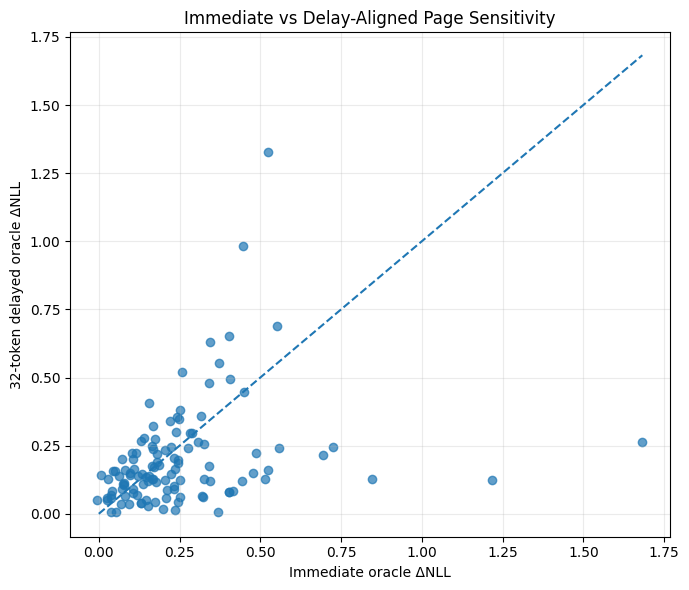

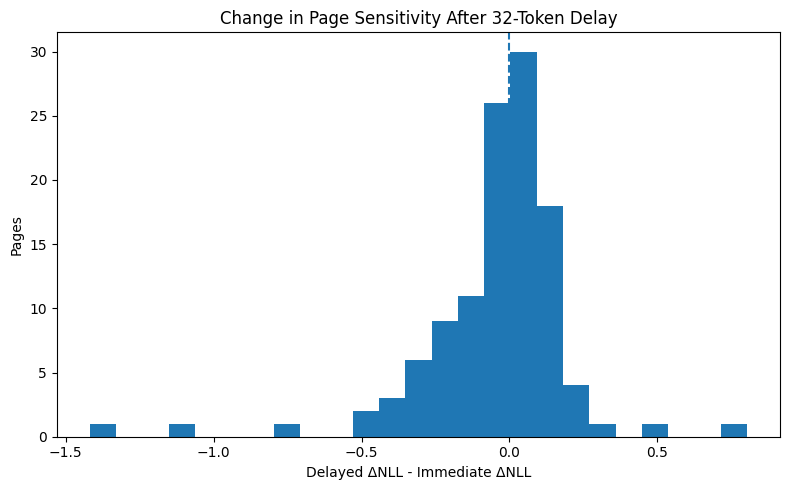


Cell 5 complete.
Comparison saved to: notebook07_results/immediate_vs_delayed_oracle.csv


In [5]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 5:
# Compare Immediate vs 32-Token Delay-Aligned Oracle
# ============================================================

import io
import os
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    spearmanr,
    pearsonr,
)


# ------------------------------------------------------------
# 1. Upload Notebook 05 results
# ------------------------------------------------------------

from google.colab import files

print(
    "Upload the Notebook 05 results ZIP "
    "(or full_page_sensitivity_map.csv)"
)

uploaded = files.upload()


# ------------------------------------------------------------
# 2. Locate old immediate-oracle CSV
# ------------------------------------------------------------

NB5_IMPORT_DIR = Path(
    "notebook05_import"
)

NB5_IMPORT_DIR.mkdir(
    exist_ok=True
)


immediate_csv_path = None


for uploaded_name, uploaded_bytes in uploaded.items():

    # Direct CSV upload
    if (
        Path(uploaded_name).name
        == "full_page_sensitivity_map.csv"
    ):

        direct_path = (
            NB5_IMPORT_DIR
            / "full_page_sensitivity_map.csv"
        )

        with open(
            direct_path,
            "wb"
        ) as f:

            f.write(
                uploaded_bytes
            )

        immediate_csv_path = (
            direct_path
        )


    # ZIP upload
    elif uploaded_name.lower().endswith(
        ".zip"
    ):

        zip_path = (
            NB5_IMPORT_DIR
            / uploaded_name
        )

        with open(
            zip_path,
            "wb"
        ) as f:

            f.write(
                uploaded_bytes
            )


        with zipfile.ZipFile(
            zip_path,
            "r"
        ) as zf:

            zf.extractall(
                NB5_IMPORT_DIR
            )


# ------------------------------------------------------------
# Search recursively if ZIP was used
# ------------------------------------------------------------

if immediate_csv_path is None:

    matches = list(
        NB5_IMPORT_DIR.rglob(
            "full_page_sensitivity_map.csv"
        )
    )

    if len(matches) == 0:

        raise FileNotFoundError(
            "Could not find "
            "full_page_sensitivity_map.csv "
            "inside the uploaded file."
        )

    immediate_csv_path = (
        matches[0]
    )


print(
    f"\nImmediate oracle CSV: "
    f"{immediate_csv_path}"
)


# ------------------------------------------------------------
# 3. Load and validate immediate oracle
# ------------------------------------------------------------

immediate_oracle_df = pd.read_csv(
    immediate_csv_path
)


required_columns = {
    "Page",
    "Delta_NLL",
}


assert required_columns.issubset(
    immediate_oracle_df.columns
)


immediate_oracle_df = (
    immediate_oracle_df[
        immediate_oracle_df["Page"].isin(
            CANDIDATE_PAGES
        )
    ]
    .copy()
    .sort_values("Page")
    .reset_index(drop=True)
)


assert (
    len(immediate_oracle_df)
    == 115
)

assert np.array_equal(
    immediate_oracle_df[
        "Page"
    ].to_numpy(),
    np.array(CANDIDATE_PAGES)
)


# ------------------------------------------------------------
# 4. Merge immediate and delayed oracles
# ------------------------------------------------------------

oracle_comparison_df = (

    immediate_oracle_df[
        [
            "Page",
            "Delta_NLL",
        ]
    ]

    .rename(
        columns={
            "Delta_NLL":
                "Immediate_Delta_NLL"
        }
    )

    .merge(

        delay_aligned_oracle_df[
            [
                "Page",
                "Delta_NLL",
            ]
        ]

        .rename(
            columns={
                "Delta_NLL":
                    "Delayed_Delta_NLL"
            }
        ),

        on="Page",
        validate="one_to_one"
    )
)


assert (
    len(oracle_comparison_df)
    == 115
)


# ------------------------------------------------------------
# 5. Rank both sensitivity maps
#
# Rank 1 = most sensitive
# ------------------------------------------------------------

oracle_comparison_df[
    "Immediate_Rank"
] = (

    oracle_comparison_df[
        "Immediate_Delta_NLL"
    ]

    .rank(
        ascending=False,
        method="first"
    )

    .astype(int)
)


oracle_comparison_df[
    "Delayed_Rank"
] = (

    oracle_comparison_df[
        "Delayed_Delta_NLL"
    ]

    .rank(
        ascending=False,
        method="first"
    )

    .astype(int)
)


# ------------------------------------------------------------
# Positive Rank_Improvement:
#
# page became MORE sensitive in delayed ranking.
#
# Example:
# immediate rank 50 -> delayed rank 10
#
# 50 - 10 = +40
# ------------------------------------------------------------

oracle_comparison_df[
    "Rank_Improvement"
] = (

    oracle_comparison_df[
        "Immediate_Rank"
    ]

    -

    oracle_comparison_df[
        "Delayed_Rank"
    ]
)


oracle_comparison_df[
    "Sensitivity_Change"
] = (

    oracle_comparison_df[
        "Delayed_Delta_NLL"
    ]

    -

    oracle_comparison_df[
        "Immediate_Delta_NLL"
    ]
)


# ------------------------------------------------------------
# 6. Global correlation
# ------------------------------------------------------------

spearman_rho, spearman_p = (
    spearmanr(

        oracle_comparison_df[
            "Immediate_Delta_NLL"
        ],

        oracle_comparison_df[
            "Delayed_Delta_NLL"
        ]
    )
)


pearson_r, pearson_p = (
    pearsonr(

        oracle_comparison_df[
            "Immediate_Delta_NLL"
        ],

        oracle_comparison_df[
            "Delayed_Delta_NLL"
        ]
    )
)


print(
    "\nImmediate vs delayed oracle"
)

print(
    "---------------------------"
)

print(
    f"Spearman rho: "
    f"{spearman_rho:.6f}"
)

print(
    f"Spearman p:   "
    f"{spearman_p:.6g}"
)

print(
    f"Pearson r:    "
    f"{pearson_r:.6f}"
)

print(
    f"Pearson p:    "
    f"{pearson_p:.6g}"
)


# ------------------------------------------------------------
# 7. Distribution comparison
# ------------------------------------------------------------

immediate_values = (
    oracle_comparison_df[
        "Immediate_Delta_NLL"
    ]
)

delayed_values = (
    oracle_comparison_df[
        "Delayed_Delta_NLL"
    ]
)


distribution_comparison_df = pd.DataFrame({

    "Metric": [
        "Minimum",
        "25th percentile",
        "Median",
        "Mean",
        "75th percentile",
        "Maximum",
        "Std",
    ],

    "Immediate": [
        immediate_values.min(),
        immediate_values.quantile(0.25),
        immediate_values.median(),
        immediate_values.mean(),
        immediate_values.quantile(0.75),
        immediate_values.max(),
        immediate_values.std(),
    ],

    "Delayed_32": [
        delayed_values.min(),
        delayed_values.quantile(0.25),
        delayed_values.median(),
        delayed_values.mean(),
        delayed_values.quantile(0.75),
        delayed_values.max(),
        delayed_values.std(),
    ],
})


distribution_comparison_df[
    "Delayed_minus_Immediate"
] = (

    distribution_comparison_df[
        "Delayed_32"
    ]

    -

    distribution_comparison_df[
        "Immediate"
    ]
)


print(
    "\nDistribution comparison"
)

print(
    "-----------------------"
)

display(
    distribution_comparison_df
)


# ------------------------------------------------------------
# 8. Top/bottom overlap
# ------------------------------------------------------------

def overlap_at_k(
    df,
    k,
    highest=True
):

    immediate_sorted = df.sort_values(
        "Immediate_Delta_NLL",
        ascending=not highest
    )

    delayed_sorted = df.sort_values(
        "Delayed_Delta_NLL",
        ascending=not highest
    )


    immediate_set = set(
        immediate_sorted
        .head(k)["Page"]
    )

    delayed_set = set(
        delayed_sorted
        .head(k)["Page"]
    )


    overlap = (
        immediate_set
        & delayed_set
    )


    return {
        "K":
            k,

        "Overlap_Count":
            len(overlap),

        "Overlap_Fraction":
            len(overlap) / k,

        "Pages":
            sorted(overlap),
    }


overlap_rows = []


for k in [
    5,
    10,
    20,
    30,
]:

    top_result = overlap_at_k(
        oracle_comparison_df,
        k,
        highest=True
    )

    bottom_result = overlap_at_k(
        oracle_comparison_df,
        k,
        highest=False
    )


    overlap_rows.append({

        "Region":
            "Most sensitive",

        **top_result,
    })


    overlap_rows.append({

        "Region":
            "Least sensitive",

        **bottom_result,
    })


overlap_df = pd.DataFrame(
    overlap_rows
)


print(
    "\nRanking overlap"
)

print(
    "---------------"
)

display(
    overlap_df
)


# ------------------------------------------------------------
# 9. Pages that became much MORE sensitive after delay
# ------------------------------------------------------------

print(
    "\nLargest increases in sensitivity"
)

print(
    "--------------------------------"
)

display(

    oracle_comparison_df[

        [
            "Page",
            "Immediate_Delta_NLL",
            "Delayed_Delta_NLL",
            "Sensitivity_Change",
            "Immediate_Rank",
            "Delayed_Rank",
            "Rank_Improvement",
        ]

    ]

    .sort_values(
        "Sensitivity_Change",
        ascending=False
    )

    .head(15)

    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. Pages that became much LESS sensitive
# ------------------------------------------------------------

print(
    "\nLargest decreases in sensitivity"
)

print(
    "--------------------------------"
)

display(

    oracle_comparison_df[

        [
            "Page",
            "Immediate_Delta_NLL",
            "Delayed_Delta_NLL",
            "Sensitivity_Change",
            "Immediate_Rank",
            "Delayed_Rank",
            "Rank_Improvement",
        ]

    ]

    .sort_values(
        "Sensitivity_Change",
        ascending=True
    )

    .head(15)

    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 11. Largest ranking promotions
# ------------------------------------------------------------

print(
    "\nLargest promotions in sensitivity rank"
)

print(
    "--------------------------------------"
)

display(

    oracle_comparison_df[

        [
            "Page",
            "Immediate_Rank",
            "Delayed_Rank",
            "Rank_Improvement",
            "Immediate_Delta_NLL",
            "Delayed_Delta_NLL",
        ]

    ]

    .sort_values(
        "Rank_Improvement",
        ascending=False
    )

    .head(15)

    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 12. Largest ranking drops
# ------------------------------------------------------------

print(
    "\nLargest drops in sensitivity rank"
)

print(
    "---------------------------------"
)

display(

    oracle_comparison_df[

        [
            "Page",
            "Immediate_Rank",
            "Delayed_Rank",
            "Rank_Improvement",
            "Immediate_Delta_NLL",
            "Delayed_Delta_NLL",
        ]

    ]

    .sort_values(
        "Rank_Improvement",
        ascending=True
    )

    .head(15)

    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 13. Diagnostic tier transitions
#
# SAME absolute thresholds used in Notebook 06.
#
# These are NOT final deployment thresholds.
# ------------------------------------------------------------

DIAGNOSTIC_LOW = 0.15
DIAGNOSTIC_HIGH = 0.30


def sensitivity_tier(
    values
):

    return np.where(

        values <= DIAGNOSTIC_LOW,

        "Low",

        np.where(

            values >= DIAGNOSTIC_HIGH,

            "High",

            "Medium"
        )
    )


oracle_comparison_df[
    "Immediate_Tier"
] = sensitivity_tier(

    oracle_comparison_df[
        "Immediate_Delta_NLL"
    ]
)


oracle_comparison_df[
    "Delayed_Tier"
] = sensitivity_tier(

    oracle_comparison_df[
        "Delayed_Delta_NLL"
    ]
)


tier_transition_df = pd.crosstab(

    oracle_comparison_df[
        "Immediate_Tier"
    ],

    oracle_comparison_df[
        "Delayed_Tier"
    ]
)


# Force intuitive order
tier_order = [
    "Low",
    "Medium",
    "High",
]


tier_transition_df = (
    tier_transition_df
    .reindex(
        index=tier_order,
        columns=tier_order,
        fill_value=0
    )
)


print(
    "\nDiagnostic tier transitions"
)

print(
    "---------------------------"
)

print(
    f"Low:  Delta NLL <= "
    f"{DIAGNOSTIC_LOW}"
)

print(
    f"High: Delta NLL >= "
    f"{DIAGNOSTIC_HIGH}"
)

display(
    tier_transition_df
)


same_tier_fraction = (

    (
        oracle_comparison_df[
            "Immediate_Tier"
        ]

        ==

        oracle_comparison_df[
            "Delayed_Tier"
        ]
    )

    .mean()
)


print(
    f"Same diagnostic tier: "
    f"{same_tier_fraction:.3f}"
)


# ------------------------------------------------------------
# 14. Scatter plot
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    oracle_comparison_df[
        "Immediate_Delta_NLL"
    ],
    oracle_comparison_df[
        "Delayed_Delta_NLL"
    ],
    alpha=0.7
)


plot_max = max(

    oracle_comparison_df[
        "Immediate_Delta_NLL"
    ].max(),

    oracle_comparison_df[
        "Delayed_Delta_NLL"
    ].max()
)


plt.plot(
    [0, plot_max],
    [0, plot_max],
    linestyle="--"
)


plt.xlabel(
    "Immediate oracle ΔNLL"
)

plt.ylabel(
    "32-token delayed oracle ΔNLL"
)

plt.title(
    "Immediate vs Delay-Aligned Page Sensitivity"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 15. Sensitivity change distribution
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    oracle_comparison_df[
        "Sensitivity_Change"
    ],
    bins=25
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Delayed ΔNLL - Immediate ΔNLL"
)

plt.ylabel(
    "Pages"
)

plt.title(
    "Change in Page Sensitivity After 32-Token Delay"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 16. Save
# ------------------------------------------------------------

comparison_path = (
    NB7_WORK_DIR
    / "immediate_vs_delayed_oracle.csv"
)

oracle_comparison_df.to_csv(
    comparison_path,
    index=False
)


overlap_path = (
    NB7_WORK_DIR
    / "immediate_delayed_rank_overlap.csv"
)

overlap_df.to_csv(
    overlap_path,
    index=False
)


transition_path = (
    NB7_WORK_DIR
    / "immediate_delayed_tier_transitions.csv"
)

tier_transition_df.to_csv(
    transition_path
)


print()
print("Cell 5 complete.")

print(
    f"Comparison saved to: "
    f"{comparison_path}"
)

### Cell 5 — Immediate vs 32-Token Delay-Aligned Sensitivity

The original fixed-horizon oracle and the new 32-token delay-aligned oracle were compared across the same 115 candidate pages.

The two sensitivity maps show only moderate rank agreement:

\[
\rho_{\text{Spearman}}=0.4169
\]

with:

\[
p=3.57\times10^{-6}.
\]

Pearson correlation is lower:

\[
r=0.2874.
\]

Therefore some page-specific sensitivity persists over time, but the delayed sensitivity landscape is substantially different from the immediate one.

---

#### Sensitivity decreases on average

The mean sensitivity changes from:

\[
0.2484 \rightarrow 0.1983,
\]

while the median changes from:

\[
0.1992 \rightarrow 0.1442.
\]

Thus pages are less sensitive on average after waiting 32 tokens before demotion.

However, this reduction is not uniform.

---

#### Extreme rankings change strongly

There is no overlap between the five most-sensitive pages of the two oracles:

\[
\text{Top-5 overlap}=0/5.
\]

There is also no overlap between the five least-sensitive pages:

\[
\text{Bottom-5 overlap}=0/5.
\]

At \(k=10\), only two highly sensitive pages overlap:

\[
\{9,117\}.
\]

This demonstrates that the pages most important at creation time are often not the pages most important 32 tokens later.

---

#### Large page-level rank changes

Examples of pages that become substantially less sensitive include:

\[
p=52:
\quad
1.2177 \rightarrow 0.1235
\]

and:

\[
p=86:
\quad
0.8471 \rightarrow 0.1277.
\]

Page 52 moves from sensitivity rank:

\[
2 \rightarrow 72.
\]

In contrast, some pages become substantially more important after the delay.

For example:

\[
p=20:
\quad
0.1564 \rightarrow 0.4080
\]

and its rank changes from:

\[
72 \rightarrow 11.
\]

Page 117 becomes the most-sensitive delayed page:

\[
0.5242 \rightarrow 1.3276.
\]

Therefore sensitivity is not simply an intrinsic static property of a page.

It depends on both:

- the page contents,
- and the time/context at which its precision is changed.

---

### Diagnostic tier transitions

Using the same exploratory thresholds as Notebook 06:

\[
\text{Low}: \Delta NLL\le0.15
\]

\[
\text{High}: \Delta NLL\ge0.30,
\]

only approximately:

\[
49.6\%
\]

of pages remain in the same sensitivity tier.

Among the original high-sensitivity pages:

- 10 remain High,
- 9 become Medium,
- 13 become Low.

Interestingly, none of the original Low pages become delayed-High:

- 30 remain Low,
- 10 become Medium,
- 0 become High.

This suggests that the low-sensitivity tail may be somewhat more temporally stable than the high-sensitivity tail in the current sequence, although this observation requires validation on additional sequences.

---

### Main conclusion

\[
\boxed{
\text{Sensitivity is both page-dependent and decision-time-dependent.}
}
\]

The immediate oracle is therefore not the correct ground-truth target for a policy that waits 32 tokens before deciding precision.

The new delay-aligned oracle should be used for all subsequent evaluation of the delayed predictor.

#6: Re-evaluate the Notebook 06 predictor against the aligned oracle

Upload notebook06_results.zip


Saving notebook06_results.zip to notebook06_results.zip

Notebook 06 files
-----------------
Combined features: notebook06_import/combined_page_features_and_oracle.csv
Delayed features: notebook06_import/delayed_attention_features.csv
Old OOF scores: notebook06_import/best_classifier_oof_scores.csv

Aligned sensitivity classes
---------------------------
High >= 0.3: 18 / 115 pages
Low  <= 0.15: 61 / 115 pages

Frozen Notebook 06 predictor -> aligned oracle
---------------------------------------------
High ROC-AUC:     0.539519
High AP:          0.167215
Low ROC-AUC:      0.444748
Low AP:           0.517130
High-score rho:   0.146155
rho p-value:      0.119092

Blocked folds
-------------
Fold 1: pages 6-28
Fold 2: pages 29-51
Fold 3: pages 52-74
Fold 4: pages 75-97
Fold 5: pages 98-120

Retrained against aligned oracle
--------------------------------
OOF ROC-AUC:       0.365120
OOF AP:            0.143451
Positive rate:     0.156522
AP / random:       0.916x
Score-vs-NLL rho:  -0.09

,Fold,Page_Start,Page_End,Positive_Pages,ROC_AUC,Average_Precision
0,1,6,28,6,0.421569,0.433847
1,2,29,51,0,NaN,NaN
2,3,52,74,3,0.816667,0.355556
3,4,75,97,7,0.196429,0.228227
4,5,98,120,2,0.392857,0.101010



Predictor comparison
--------------------


,Experiment,ROC_AUC,Average_Precision
0,Notebook 06 original (old immediate labels),0.744729,0.479790
1,Frozen NB06 scores vs aligned labels,0.539519,0.167215
2,Same model retrained on aligned labels,0.365120,0.143451


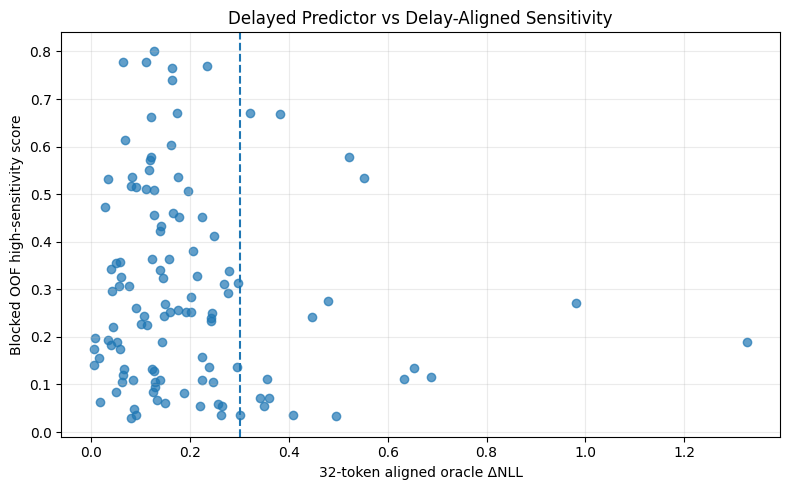


Cell 6 complete.
The Notebook 06 delayed predictor has now been evaluated against the correctly aligned oracle.


In [6]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 6:
# Re-evaluate Notebook 06 Predictor Against
# the Correct 32-Token Delay-Aligned Oracle
# ============================================================

import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ============================================================
# 1. Upload Notebook 06 results ZIP
# ============================================================

from google.colab import files

print(
    "Upload notebook06_results.zip"
)

uploaded = files.upload()


NB6_IMPORT_DIR = Path(
    "notebook06_import"
)

NB6_IMPORT_DIR.mkdir(
    exist_ok=True
)


for filename, file_bytes in uploaded.items():

    path = (
        NB6_IMPORT_DIR
        / filename
    )

    with open(
        path,
        "wb"
    ) as f:

        f.write(file_bytes)


    if filename.lower().endswith(".zip"):

        with zipfile.ZipFile(
            path,
            "r"
        ) as zf:

            zf.extractall(
                NB6_IMPORT_DIR
            )


# ============================================================
# 2. Locate required Notebook 06 files
# ============================================================

def find_result_file(filename):

    matches = list(
        NB6_IMPORT_DIR.rglob(
            filename
        )
    )

    if len(matches) == 0:

        raise FileNotFoundError(
            f"Could not find {filename}"
        )

    return matches[0]


combined_features_path = find_result_file(
    "combined_page_features_and_oracle.csv"
)

delayed_features_path = find_result_file(
    "delayed_attention_features.csv"
)

old_scores_path = find_result_file(
    "best_classifier_oof_scores.csv"
)


print()
print("Notebook 06 files")
print("-----------------")

print(
    "Combined features:",
    combined_features_path
)

print(
    "Delayed features:",
    delayed_features_path
)

print(
    "Old OOF scores:",
    old_scores_path
)


# ============================================================
# 3. Load Notebook 06 data
# ============================================================

nb6_features_df = pd.read_csv(
    combined_features_path
)

nb6_delayed_df = pd.read_csv(
    delayed_features_path
)

nb6_old_scores_df = pd.read_csv(
    old_scores_path
)


# ------------------------------------------------------------
# Only 2-page delayed features
# ------------------------------------------------------------

delay2_df = (
    nb6_delayed_df[
        nb6_delayed_df[
            "Delay_Pages"
        ] == 2
    ]
    .copy()
)


assert (
    len(delay2_df) == 115
)


# ============================================================
# 4. Reconstruct exact Notebook 06 delayed feature set
# ============================================================

IMMEDIATE_FEATURES = [

    "Attn_Self_Mean",

    "Attn_Self_Last",

    "Attn_Self_LayerStd",

    "Attn_Self_LayerMax",

    "Attn_PageEntropy_Mean",

    "Attn_PageEntropy_Last",

    "Conf_Entropy_Mean",

    "Conf_Entropy_Last",

    "Conf_Top1_Mean",

    "Conf_Top1_Last",

    "Conf_Margin_Mean",

    "Conf_Margin_Last",

    "Normalized_Position",
]


DELAYED_ATTENTION_FEATURES = [

    "DelayedAttn_Mean_Mean",

    "DelayedAttn_Mean_Max",

    "DelayedAttn_Last_Mean",

    "DelayedAttn_Last_Max",
]


DELAYED_FEATURES = (

    IMMEDIATE_FEATURES
    + DELAYED_ATTENTION_FEATURES
)


# ------------------------------------------------------------
# Merge features
# ------------------------------------------------------------

feature_df = (

    nb6_features_df[
        [
            "Page",
            *IMMEDIATE_FEATURES,
        ]
    ]

    .merge(

        delay2_df[
            [
                "Page",
                *DELAYED_ATTENTION_FEATURES,
            ]
        ],

        on="Page",

        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# Merge CORRECT aligned oracle
# ------------------------------------------------------------

aligned_prediction_df = (

    feature_df

    .merge(

        delay_aligned_oracle_df[
            [
                "Page",
                "Delta_NLL",
            ]
        ]

        .rename(
            columns={
                "Delta_NLL":
                    "Aligned_Delta_NLL"
            }
        ),

        on="Page",

        validate="one_to_one"
    )

    .sort_values("Page")

    .reset_index(drop=True)
)


assert (
    len(aligned_prediction_df)
    == 115
)

assert np.isfinite(
    aligned_prediction_df[
        DELAYED_FEATURES
    ].to_numpy()
).all()


# ============================================================
# 5. Define aligned labels using SAME absolute thresholds
#
# Keep Notebook 06 thresholds unchanged for a clean
# apples-to-apples comparison.
# ============================================================

ALIGNED_HIGH_THRESHOLD = 0.30

ALIGNED_LOW_THRESHOLD = 0.15


aligned_prediction_df[
    "Aligned_High"
] = (

    aligned_prediction_df[
        "Aligned_Delta_NLL"
    ]

    >= ALIGNED_HIGH_THRESHOLD

).astype(int)


aligned_prediction_df[
    "Aligned_Low"
] = (

    aligned_prediction_df[
        "Aligned_Delta_NLL"
    ]

    <= ALIGNED_LOW_THRESHOLD

).astype(int)


num_high = int(
    aligned_prediction_df[
        "Aligned_High"
    ].sum()
)

num_low = int(
    aligned_prediction_df[
        "Aligned_Low"
    ].sum()
)


print()
print("Aligned sensitivity classes")
print("---------------------------")

print(
    f"High >= {ALIGNED_HIGH_THRESHOLD}: "
    f"{num_high} / 115 pages"
)

print(
    f"Low  <= {ALIGNED_LOW_THRESHOLD}: "
    f"{num_low} / 115 pages"
)


# ============================================================
# PART A
#
# 6. Frozen Notebook 06 OOF classifier score transfer
#
# No retraining here.
# ============================================================

old_score_df = (

    nb6_old_scores_df[
        [
            "Page",
            "High_FP16_Candidate_Score",
            "Low_INT4_Candidate_Score",
        ]
    ]

    .merge(

        aligned_prediction_df[
            [
                "Page",
                "Aligned_Delta_NLL",
                "Aligned_High",
                "Aligned_Low",
            ]
        ],

        on="Page",

        validate="one_to_one"
    )
)


frozen_high_auc = roc_auc_score(

    old_score_df[
        "Aligned_High"
    ],

    old_score_df[
        "High_FP16_Candidate_Score"
    ]
)


frozen_high_ap = average_precision_score(

    old_score_df[
        "Aligned_High"
    ],

    old_score_df[
        "High_FP16_Candidate_Score"
    ]
)


frozen_low_auc = roc_auc_score(

    old_score_df[
        "Aligned_Low"
    ],

    old_score_df[
        "Low_INT4_Candidate_Score"
    ]
)


frozen_low_ap = average_precision_score(

    old_score_df[
        "Aligned_Low"
    ],

    old_score_df[
        "Low_INT4_Candidate_Score"
    ]
)


frozen_rho, frozen_rho_p = spearmanr(

    old_score_df[
        "High_FP16_Candidate_Score"
    ],

    old_score_df[
        "Aligned_Delta_NLL"
    ]
)


print()
print(
    "Frozen Notebook 06 predictor -> aligned oracle"
)

print(
    "---------------------------------------------"
)

print(
    f"High ROC-AUC:     "
    f"{frozen_high_auc:.6f}"
)

print(
    f"High AP:          "
    f"{frozen_high_ap:.6f}"
)

print(
    f"Low ROC-AUC:      "
    f"{frozen_low_auc:.6f}"
)

print(
    f"Low AP:           "
    f"{frozen_low_ap:.6f}"
)

print(
    f"High-score rho:   "
    f"{frozen_rho:.6f}"
)

print(
    f"rho p-value:      "
    f"{frozen_rho_p:.6g}"
)


# ============================================================
# PART B
#
# 7. Retrain the SAME Notebook 06 high classifier
# against the CORRECT aligned target.
#
# Same:
# - 17 delayed features
# - Gradient Boosting
# - 5 contiguous folds
# ============================================================

X = aligned_prediction_df[
    DELAYED_FEATURES
].to_numpy(dtype=float)

y_high = aligned_prediction_df[
    "Aligned_High"
].to_numpy(dtype=int)


n_pages = len(
    aligned_prediction_df
)

all_indices = np.arange(
    n_pages
)

blocked_folds = np.array_split(
    all_indices,
    5
)


print()
print("Blocked folds")
print("-------------")


for fold_idx, test_idx in enumerate(
    blocked_folds,
    start=1
):

    fold_pages = (
        aligned_prediction_df
        .iloc[test_idx]["Page"]
    )

    print(
        f"Fold {fold_idx}: "
        f"pages "
        f"{int(fold_pages.min())}-"
        f"{int(fold_pages.max())}"
    )


# ------------------------------------------------------------
# Same Gradient Boosting configuration as Notebook 06
# ------------------------------------------------------------

aligned_classifier_template = (
    GradientBoostingClassifier(

        n_estimators=100,

        learning_rate=0.03,

        max_depth=2,

        min_samples_leaf=5,

        loss="log_loss",

        random_state=SEED
    )
)


def balanced_sample_weights(y):

    y = np.asarray(y)

    n = len(y)

    n0 = np.sum(
        y == 0
    )

    n1 = np.sum(
        y == 1
    )


    weights = np.ones(
        n,
        dtype=float
    )


    if n0 > 0:

        weights[
            y == 0
        ] = (
            n
            / (2.0 * n0)
        )


    if n1 > 0:

        weights[
            y == 1
        ] = (
            n
            / (2.0 * n1)
        )


    return weights


aligned_high_oof = np.full(
    n_pages,
    np.nan,
    dtype=float
)


fold_rows = []


for fold_idx, test_idx in enumerate(
    blocked_folds,
    start=1
):

    train_mask = np.ones(
        n_pages,
        dtype=bool
    )

    train_mask[
        test_idx
    ] = False

    train_idx = (
        all_indices[
            train_mask
        ]
    )


    clf = clone(
        aligned_classifier_template
    )


    train_weights = (
        balanced_sample_weights(
            y_high[
                train_idx
            ]
        )
    )


    clf.fit(

        X[
            train_idx
        ],

        y_high[
            train_idx
        ],

        sample_weight=train_weights
    )


    fold_probs = clf.predict_proba(

        X[
            test_idx
        ]

    )[:, 1]


    aligned_high_oof[
        test_idx
    ] = fold_probs


    y_fold = y_high[
        test_idx
    ]


    if len(
        np.unique(
            y_fold
        )
    ) == 2:

        fold_auc = roc_auc_score(
            y_fold,
            fold_probs
        )

        fold_ap = average_precision_score(
            y_fold,
            fold_probs
        )

    else:

        fold_auc = np.nan
        fold_ap = np.nan


    fold_rows.append({

        "Fold":
            fold_idx,

        "Page_Start":
            int(
                aligned_prediction_df
                .iloc[test_idx]["Page"]
                .min()
            ),

        "Page_End":
            int(
                aligned_prediction_df
                .iloc[test_idx]["Page"]
                .max()
            ),

        "Positive_Pages":
            int(
                y_fold.sum()
            ),

        "ROC_AUC":
            fold_auc,

        "Average_Precision":
            fold_ap,
    })


assert np.isfinite(
    aligned_high_oof
).all()


# ============================================================
# 8. Aligned OOF metrics
# ============================================================

aligned_high_auc = roc_auc_score(
    y_high,
    aligned_high_oof
)

aligned_high_ap = average_precision_score(
    y_high,
    aligned_high_oof
)


aligned_rho, aligned_rho_p = spearmanr(

    aligned_high_oof,

    aligned_prediction_df[
        "Aligned_Delta_NLL"
    ]
)


aligned_fold_df = pd.DataFrame(
    fold_rows
)


print()
print(
    "Retrained against aligned oracle"
)

print(
    "--------------------------------"
)

print(
    f"OOF ROC-AUC:       "
    f"{aligned_high_auc:.6f}"
)

print(
    f"OOF AP:            "
    f"{aligned_high_ap:.6f}"
)

print(
    f"Positive rate:     "
    f"{y_high.mean():.6f}"
)

print(
    f"AP / random:       "
    f"{aligned_high_ap / y_high.mean():.3f}x"
)

print(
    f"Score-vs-NLL rho:  "
    f"{aligned_rho:.6f}"
)

print(
    f"rho p-value:       "
    f"{aligned_rho_p:.6g}"
)


print()
print(
    "Fold-by-fold aligned performance"
)

print(
    "--------------------------------"
)

display(
    aligned_fold_df
)


# ============================================================
# 9. Compact comparison table
# ============================================================

comparison_rows = [

    {
        "Experiment":
            (
                "Notebook 06 original "
                "(old immediate labels)"
            ),

        "ROC_AUC":
            NB6_HIGH_OOF_AUC,

        "Average_Precision":
            NB6_HIGH_OOF_AP,
    },

    {
        "Experiment":
            (
                "Frozen NB06 scores "
                "vs aligned labels"
            ),

        "ROC_AUC":
            frozen_high_auc,

        "Average_Precision":
            frozen_high_ap,
    },

    {
        "Experiment":
            (
                "Same model retrained "
                "on aligned labels"
            ),

        "ROC_AUC":
            aligned_high_auc,

        "Average_Precision":
            aligned_high_ap,
    },
]


aligned_classifier_comparison_df = (
    pd.DataFrame(
        comparison_rows
    )
)


print()
print(
    "Predictor comparison"
)

print(
    "--------------------"
)

display(
    aligned_classifier_comparison_df
)


# ============================================================
# 10. Save aligned scores
# ============================================================

aligned_prediction_df[
    "Aligned_High_OOF_Score"
] = (
    aligned_high_oof
)


aligned_scores_path = (
    NB7_WORK_DIR
    / "aligned_high_classifier_oof_scores.csv"
)


aligned_prediction_df.to_csv(
    aligned_scores_path,
    index=False
)


aligned_fold_path = (
    NB7_WORK_DIR
    / "aligned_high_classifier_fold_results.csv"
)


aligned_fold_df.to_csv(
    aligned_fold_path,
    index=False
)


# ============================================================
# 11. Plot
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.scatter(

    aligned_prediction_df[
        "Aligned_Delta_NLL"
    ],

    aligned_high_oof,

    alpha=0.7
)


plt.axvline(
    ALIGNED_HIGH_THRESHOLD,
    linestyle="--"
)


plt.xlabel(
    "32-token aligned oracle ΔNLL"
)

plt.ylabel(
    "Blocked OOF high-sensitivity score"
)

plt.title(
    "Delayed Predictor vs Delay-Aligned Sensitivity"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


print()
print("Cell 6 complete.")

print(
    "The Notebook 06 delayed predictor has now been "
    "evaluated against the correctly aligned oracle."
)

There were three comparisons:

$$ \boxed{1.\ \text{Original Notebook 06 result}} $$

The predictor used delayed attention, but was judged against the immediate oracle:

$$ AUC=0.7447. $$ $$ \boxed{2.\ \text{Frozen Notebook 06 predictor}} $$

We took its already-generated predictions and compared them against the new delayed oracle, without retraining:

$$ AUC=0.5395. $$

That is basically close to random.

$$ \boxed{3.\ \text{Same signals + same Gradient Boosting model, retrained}} $$

But this time we trained it directly to predict the correct delayed oracle:

$$ AUC=0.3651. $$

It actually performed worse than random overall.

So the simple conclusion is:

The attention/confidence/position signals from Notebook 06 looked promising when compared with the immediate oracle, but once we correctly align the oracle with the 32-token decision time, they do not reliably predict which pages are still sensitive.

The fold behavior is also unstable: one fold reaches \(0.817\), another falls to \(0.196\), and one fold has no positive high-sensitivity pages at all.

This is actually useful rather than a failed experiment. It tells us that we should not force those signals into the final policy.

Now we move to the signal family I expected may be more directly useful:

$$ \boxed{\text{quantization-aware page features}} $$

Instead of asking:

“Does the model pay attention to this page?”

we ask:

“How difficult is this page itself to represent in INT4?”

### Cell 6 — Re-Evaluating Notebook 06 Signals Against the Aligned Oracle

Notebook 06 produced a promising high-sensitivity classifier using delayed attention together with confidence and positional features.

However, that classifier had originally been evaluated against an oracle that measured quantization damage immediately after page completion.

Notebook 07 showed that the correct decision occurs 32 tokens later, and that the immediate and delayed sensitivity maps differ substantially.

Cell 6 therefore tested the Notebook 06 signals against the correctly aligned oracle.

Three cases were compared.

---

#### 1. Original Notebook 06 result

The original delayed-feature Gradient Boosting classifier obtained:

\[
ROC\text{-}AUC=0.7447.
\]

However, this result used the immediate sensitivity labels.

---

#### 2. Frozen Notebook 06 predictions against aligned labels

The already-generated Notebook 06 predictions were evaluated directly against the new 32-token aligned sensitivity classes.

The result fell to:

\[
ROC\text{-}AUC=0.5395.
\]

This is only slightly above random ranking:

\[
AUC=0.5.
\]

The high-classifier score also had only weak correlation with the new continuous sensitivity target:

\[
\rho=0.1462.
\]

Thus the original predictor does not transfer well to the delayed decision problem.

---

#### 3. Same model retrained on aligned labels

The same 17 delayed features and the same Gradient Boosting formulation were then retrained using the correct aligned labels.

Blocked out-of-fold performance was:

\[
ROC\text{-}AUC=0.3651
\]

and:

\[
Average\ Precision=0.1435.
\]

The high-sensitivity class prevalence was:

\[
0.1565,
\]

so Average Precision was actually slightly below the random prevalence baseline.

Fold-level performance was also highly unstable.

Therefore simply retraining the same attention/confidence/position signals does not solve the aligned prediction problem.

---

### Conclusion

The apparent success of Notebook 06 does not survive correction of the decision-time mismatch.

The currently tested signals:

- immediate attention,
- delayed attention,
- confidence,
- and position,

are insufficient for reliable prediction of sensitivity at the delayed decision point on the current sequence.

This motivates a new signal family that is more directly related to the operation being predicted:

\[
\boxed{\text{quantization-aware page features}}
\]

Rather than estimating importance indirectly from model behavior, the next experiment characterizes how much local numerical distortion each page would experience if converted from its current INT8 representation to per-vector INT4.

#7: Extract quantization-aware page signals

In [7]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 7:
# Extract Quantization-Aware Signals at the
# 32-Token Decision Point
# ============================================================

import math
import time
import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm


# ============================================================
# 1. Tensor-level quantization feature helper
# ============================================================

def quantization_tensor_features(
    tensor,
    num_bits=4
):

    # --------------------------------------------------------
    # Input is the currently stored cache representation.
    #
    # In our architecture this is the dequantized INT8
    # approximation, NOT the original FP16 tensor.
    # --------------------------------------------------------

    x = tensor.float()


    qmax = (
        2 ** (num_bits - 1)
    ) - 1


    # --------------------------------------------------------
    # Per-vector scale:
    #
    # one scale per [B, H, token, :]
    # --------------------------------------------------------

    max_abs_vector = x.abs().amax(
        dim=-1,
        keepdim=True
    )

    scales = (
        max_abs_vector
        / qmax
    )

    scales = torch.where(
        scales == 0,
        torch.ones_like(scales),
        scales
    )


    q = torch.round(
        x / scales
    )

    q = torch.clamp(
        q,
        -qmax,
        qmax
    )


    dq = (
        q * scales
    )


    # --------------------------------------------------------
    # Error
    # --------------------------------------------------------

    error = (
        x - dq
    )


    mae = (
        error.abs()
        .mean()
        .item()
    )


    rmse = (
        torch.sqrt(
            torch.mean(
                error ** 2
            )
        )
        .item()
    )


    rms = (
        torch.sqrt(
            torch.mean(
                x ** 2
            )
        )
        .item()
    )


    nrmse = (
        rmse
        / max(
            rms,
            1e-12
        )
    )


    max_abs = (
        x.abs()
        .max()
        .item()
    )


    peak_to_rms = (
        max_abs
        / max(
            rms,
            1e-12
        )
    )


    # --------------------------------------------------------
    # Quantized-code statistics
    # --------------------------------------------------------

    zero_fraction = (
        (q == 0)
        .float()
        .mean()
        .item()
    )


    high_code_fraction = (
        (q.abs() >= (qmax - 1))
        .float()
        .mean()
        .item()
    )


    # --------------------------------------------------------
    # Scale statistics
    # --------------------------------------------------------

    scale_mean = (
        scales.mean().item()
    )

    scale_std = (
        scales.std(
            unbiased=False
        ).item()
    )

    scale_max = (
        scales.max().item()
    )


    return {

        "MAE":
            mae,

        "RMSE":
            rmse,

        "RMS":
            rms,

        "NRMSE":
            nrmse,

        "MaxAbs":
            max_abs,

        "PeakToRMS":
            peak_to_rms,

        "ZeroFraction":
            zero_fraction,

        "HighCodeFraction":
            high_code_fraction,

        "ScaleMean":
            scale_mean,

        "ScaleStd":
            scale_std,

        "ScaleMax":
            scale_max,
    }


# ============================================================
# 2. Extract one target-page feature vector
# ============================================================

def extract_quantization_aware_page_features(
    cache,
    target_page
):

    start = (
        target_page
        * PAGE_SIZE
    )

    end = (
        start
        + PAGE_SIZE
    )


    key_layer_features = []
    value_layer_features = []


    # --------------------------------------------------------
    # Evaluate every transformer layer separately.
    # --------------------------------------------------------

    for layer in cache.layers:

        key_page = (
            layer.keys[
                :,
                :,
                start:end,
                :
            ]
        )


        value_page = (
            layer.values[
                :,
                :,
                start:end,
                :
            ]
        )


        key_features = (
            quantization_tensor_features(
                key_page,
                num_bits=4
            )
        )


        value_features = (
            quantization_tensor_features(
                value_page,
                num_bits=4
            )
        )


        key_layer_features.append(
            key_features
        )

        value_layer_features.append(
            value_features
        )


    # --------------------------------------------------------
    # Aggregate across layers.
    #
    # We intentionally avoid using all 28 layer values as
    # separate ML inputs because there are only 115 pages.
    # --------------------------------------------------------

    row = {
        "Page":
            int(target_page),

        "Start_Token":
            int(start),

        "End_Token":
            int(end - 1),

        "Decision_After_Token":
            int(
                (
                    target_page
                    + DECISION_DELAY_PAGES
                    + 1
                )
                * PAGE_SIZE
                - 1
            ),
    }


    metric_names = list(
        key_layer_features[0].keys()
    )


    for tensor_name, layer_features in [

        (
            "K",
            key_layer_features
        ),

        (
            "V",
            value_layer_features
        ),
    ]:

        for metric in metric_names:

            values = np.array(
                [
                    layer_dict[
                        metric
                    ]
                    for layer_dict
                    in layer_features
                ],
                dtype=float
            )


            row[
                f"{tensor_name}_{metric}_Mean"
            ] = float(
                values.mean()
            )


            row[
                f"{tensor_name}_{metric}_Std"
            ] = float(
                values.std()
            )


            row[
                f"{tensor_name}_{metric}_Max"
            ] = float(
                values.max()
            )


    # --------------------------------------------------------
    # Useful explicit K/V combined signals
    # --------------------------------------------------------

    row[
        "KV_NRMSE_Mean"
    ] = 0.5 * (

        row[
            "K_NRMSE_Mean"
        ]

        +

        row[
            "V_NRMSE_Mean"
        ]
    )


    row[
        "KV_NRMSE_Max"
    ] = max(

        row[
            "K_NRMSE_Max"
        ],

        row[
            "V_NRMSE_Max"
        ]
    )


    row[
        "KV_RMSE_Mean"
    ] = 0.5 * (

        row[
            "K_RMSE_Mean"
        ]

        +

        row[
            "V_RMSE_Mean"
        ]
    )


    row[
        "KV_PeakToRMS_Mean"
    ] = 0.5 * (

        row[
            "K_PeakToRMS_Mean"
        ]

        +

        row[
            "V_PeakToRMS_Mean"
        ]
    )


    row[
        "K_minus_V_NRMSE"
    ] = (

        row[
            "K_NRMSE_Mean"
        ]

        -

        row[
            "V_NRMSE_Mean"
        ]
    )


    return row


# ============================================================
# 3. Single sequential cache pass
#
# At current page q:
#
# target page p = q - 2
#
# has just completed its 32-token observation period.
# ============================================================

quant_feature_rows = []


feature_cache = DynamicCache(
    config=model.config
)


max_decision_page = (
    CANDIDATE_PAGE_END
    + DECISION_DELAY_PAGES
)


print(
    "Extracting quantization-aware page features"
)

print(
    "-------------------------------------------"
)

print(
    f"Candidate pages:    "
    f"{CANDIDATE_PAGE_START}-"
    f"{CANDIDATE_PAGE_END}"
)

print(
    f"Decision delay:     "
    f"{DECISION_DELAY_PAGES} pages"
)

print(
    f"Last stream page:   "
    f"{max_decision_page}"
)

print()


feature_start_time = time.time()


for page_idx in tqdm(
    range(
        max_decision_page + 1
    ),
    desc="Streaming cache"
):

    start = (
        page_idx
        * PAGE_SIZE
    )

    end = (
        start
        + PAGE_SIZE
    )


    chunk_ids = aligned_ids[
        :,
        start:end
    ]


    cache_position = torch.arange(
        start,
        end,
        device=model.device
    )


    attention_mask = torch.ones(
        (
            aligned_ids.shape[0],
            end
        ),
        dtype=torch.long,
        device=model.device
    )


    with torch.inference_mode():

        outputs = model(
            input_ids=chunk_ids,
            past_key_values=feature_cache,
            attention_mask=attention_mask,
            cache_position=cache_position,
            use_cache=True
        )


    feature_cache = (
        outputs.past_key_values
    )


    # --------------------------------------------------------
    # Apply actual storage policy:
    #
    # prefix 0-5 = FP16
    # all other completed pages = INT8
    # --------------------------------------------------------

    if page_idx >= NUM_PREFIX_FP16:

        quantize_completed_page_with_scheme(
            feature_cache,
            start,
            end,
            "INT8",
            int4_scheme="per-vector"
        )


    # --------------------------------------------------------
    # A page whose 2-page observation period just ended.
    # --------------------------------------------------------

    target_page = (
        page_idx
        - DECISION_DELAY_PAGES
    )


    if (
        CANDIDATE_PAGE_START
        <= target_page
        <= CANDIDATE_PAGE_END
    ):

        features = (
            extract_quantization_aware_page_features(
                feature_cache,
                target_page
            )
        )


        quant_feature_rows.append(
            features
        )


# ============================================================
# 4. Construct DataFrame
# ============================================================

quantization_features_df = pd.DataFrame(
    quant_feature_rows
)


quantization_features_df = (
    quantization_features_df
    .sort_values("Page")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

assert (
    len(
        quantization_features_df
    )
    == 115
)


assert np.array_equal(

    quantization_features_df[
        "Page"
    ].to_numpy(),

    np.array(
        CANDIDATE_PAGES
    )
)


numeric_columns = (

    quantization_features_df
    .select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
)


assert np.isfinite(

    quantization_features_df[
        numeric_columns
    ].to_numpy()

).all()


# ============================================================
# 5. Merge with aligned oracle
# ============================================================

quantization_analysis_df = (

    quantization_features_df

    .merge(

        delay_aligned_oracle_df[
            [
                "Page",
                "Delta_NLL",
                "Delayed_Oracle_Rank",
            ]
        ],

        on="Page",

        validate="one_to_one"
    )
)


# ============================================================
# 6. Print compact feature statistics
# ============================================================

IMPORTANT_QUANT_FEATURES = [

    "K_NRMSE_Mean",
    "V_NRMSE_Mean",
    "KV_NRMSE_Mean",

    "K_NRMSE_Max",
    "V_NRMSE_Max",
    "KV_NRMSE_Max",

    "K_PeakToRMS_Mean",
    "V_PeakToRMS_Mean",

    "K_ZeroFraction_Mean",
    "V_ZeroFraction_Mean",

    "K_HighCodeFraction_Mean",
    "V_HighCodeFraction_Mean",

    "K_ScaleMean_Mean",
    "V_ScaleMean_Mean",

    "K_minus_V_NRMSE",
]


print()
print(
    "Quantization-aware feature ranges"
)

print(
    "---------------------------------"
)


feature_summary_rows = []


for feature in IMPORTANT_QUANT_FEATURES:

    values = (
        quantization_analysis_df[
            feature
        ]
    )


    feature_summary_rows.append({

        "Feature":
            feature,

        "Min":
            values.min(),

        "Mean":
            values.mean(),

        "Std":
            values.std(),

        "Max":
            values.max(),
    })


quant_feature_summary_df = (
    pd.DataFrame(
        feature_summary_rows
    )
)


display(
    quant_feature_summary_df
)


# ============================================================
# 7. Preview
# ============================================================

print()
print(
    "Page feature preview"
)

print(
    "--------------------"
)


display(

    quantization_analysis_df[

        [
            "Page",

            "K_NRMSE_Mean",

            "V_NRMSE_Mean",

            "KV_NRMSE_Mean",

            "K_PeakToRMS_Mean",

            "V_PeakToRMS_Mean",

            "Delta_NLL",
        ]

    ]

    .head(15)
)


# ============================================================
# 8. Save
# ============================================================

quant_features_path = (
    NB7_WORK_DIR
    / "quantization_aware_page_features.csv"
)


quantization_analysis_df.to_csv(
    quant_features_path,
    index=False
)


runtime = (
    time.time()
    - feature_start_time
)


print()
print(
    f"Feature extraction runtime: "
    f"{runtime:.2f} seconds"
)

print(
    f"Saved to: "
    f"{quant_features_path}"
)

print()

print(
    "Cell 7 complete."
)

print(
    "Quantization-aware signals are ready "
    "for comparison against the aligned oracle."
)

Extracting quantization-aware page features
-------------------------------------------
Candidate pages:    6-120
Decision delay:     2 pages
Last stream page:   122



Streaming cache:   0%|          | 0/123 [00:00<?, ?it/s]


Quantization-aware feature ranges
---------------------------------


,Feature,Min,Mean,Std,Max
0,K_NRMSE_Mean,0.193200,0.204913,0.004180,0.213866
1,V_NRMSE_Mean,0.154754,0.162509,0.002913,0.169783
2,KV_NRMSE_Mean,0.175488,0.183711,0.002902,0.190282
3,K_NRMSE_Max,0.278214,0.285570,0.003236,0.293814
4,V_NRMSE_Max,0.227875,0.242564,0.012100,0.286086
5,KV_NRMSE_Max,0.278214,0.285570,0.003236,0.293814
6,K_PeakToRMS_Mean,6.514338,7.082903,0.186998,7.583459
7,V_PeakToRMS_Mean,5.872943,6.352266,0.190037,6.725347
8,K_ZeroFraction_Mean,0.381426,0.424734,0.015577,0.468951
9,V_ZeroFraction_Mean,0.232945,0.254676,0.007059,0.271240



Page feature preview
--------------------


,Page,K_NRMSE_Mean,V_NRMSE_Mean,KV_NRMSE_Mean,K_PeakToRMS_Mean,V_PeakToRMS_Mean,Delta_NLL
0,6,0.209406,0.163304,0.186355,7.214215,6.187600,0.261664
1,7,0.200833,0.162257,0.181545,7.040126,6.568607,0.139322
2,8,0.203392,0.161648,0.182520,7.229527,6.562831,0.219907
3,9,0.204693,0.163935,0.184314,7.075369,6.574666,0.687718
4,10,0.202185,0.165677,0.183931,6.984293,6.725347,0.224567
5,11,0.203192,0.160001,0.181597,7.136881,6.468550,0.257148
6,12,0.197019,0.160891,0.178955,6.593364,5.872943,0.263621
7,13,0.212592,0.163811,0.188201,7.389487,6.555839,0.349112
8,14,0.207270,0.162995,0.185132,7.209929,6.348686,0.300259
9,15,0.206042,0.161586,0.183814,6.950388,6.289995,0.246270



Feature extraction runtime: 20.50 seconds
Saved to: notebook07_results/quantization_aware_page_features.csv

Cell 7 complete.
Quantization-aware signals are ready for comparison against the aligned oracle.


The first thing that stands out is that the quantization-aware features do vary across pages, but not enormously. For example:

$$ K\text{-NRMSE mean}: 0.1932 \rightarrow 0.2139 $$ $$ V\text{-NRMSE mean}: 0.1548 \rightarrow 0.1698 $$

So the range is fairly narrow.

Also, Keys are consistently harder to represent with per-vector INT4 than Values:

$$ \overline{K\text{-NRMSE}}\approx0.205 $$

versus

$$ \overline{V\text{-NRMSE}}\approx0.163. $$

That is useful structurally, but it does not yet mean K-NRMSE predicts sensitivity.

You can already see why we need Cell 8. Page 9 has:

$$ KV\text{-NRMSE}=0.1843,\qquad \Delta NLL=0.6877 $$

while Page 18 has:

$$ KV\text{-NRMSE}=0.1847,\qquad \Delta NLL=0.0857. $$

Almost identical reconstruction error, but drastically different model-level sensitivity.

So NRMSE alone is unlikely to explain everything—which is consistent with what Notebook 05 already suggested.

### Cell 7 — Quantization-Aware Page Features

Cell 7 introduces a new signal family that is directly related to the precision decision.

At each page's 32-token decision point, the target page is already stored in its default INT8 state.

The page is temporarily simulated as:

\[
INT8 \rightarrow INT4_{\text{per-vector}}
\]

without modifying the actual cache.

The resulting INT4 reconstruction is compared with the currently stored INT8 approximation.

Therefore all features are available at inference time and do not require future ground-truth tokens.

---

### Extracted feature families

For both Keys and Values, the following properties were measured:

- MAE,
- RMSE,
- RMS magnitude,
- NRMSE,
- maximum absolute magnitude,
- peak-to-RMS ratio,
- zero-code fraction,
- near-saturation code fraction,
- quantization-scale mean,
- quantization-scale variance,
- maximum scale.

These statistics were calculated separately for all 28 layers and then summarized across layers.

This avoids treating every layer statistic as a separate feature, which would produce too many inputs for only 115 pages.

---

### Initial numerical observations

Keys exhibit larger normalized INT4 reconstruction error than Values.

Average values are approximately:

\[
K\text{-NRMSE}=0.2049
\]

and:

\[
V\text{-NRMSE}=0.1625.
\]

However, page-to-page variation in these aggregate reconstruction metrics is relatively small.

For example:

\[
K\text{-NRMSE}\in[0.1932,0.2139].
\]

Thus quantization difficulty is not obviously separated into dramatically different numerical regimes.

---

### Reconstruction error is not automatically sensitivity

Pages with similar reconstruction error can have very different model-level sensitivity.

For example, two pages can have nearly identical mean KV NRMSE while producing substantially different:

\[
\Delta NLL.
\]

Therefore tensor reconstruction error should not be assumed to predict language-model quality.

The next experiment measures the relationship directly using the aligned sensitivity oracle.

#8: Quantization-aware signals vs aligned sensitivity

Now we test three things:

continuous correlation with delayed \(\Delta NLL\);
ability to identify high-sensitivity pages;
ability to identify low-sensitivity pages.

We'll use the same diagnostic classes:

$$ \text{High}: \Delta NLL\ge0.30 $$ $$ \text{Low}: \Delta NLL\le0.15. $$



Aligned sensitivity classes
---------------------------
High >= 0.3: 18 pages
Low  <= 0.15: 61 pages

Quantization-aware signal results
---------------------------------


,Feature,Spearman_Rho,Abs_Rho,P_Value,High_ROC_AUC,High_Direction,High_AP,Low_ROC_AUC,Low_Direction,Low_AP,Mean,Std,Coeff_Variation
0,V_NRMSE_Max,0.252316,0.252316,0.006520,0.678694,Higher -> High,0.282739,0.603522,Lower -> Low,0.630100,0.242564,0.012047,0.049667
1,K_PeakToRMS_Mean,-0.177085,0.177085,0.058322,0.615120,Lower -> High,0.219687,0.585307,Higher -> Low,0.639433,7.082903,0.186184,0.026286
2,V_ZeroFraction_Mean,0.154380,0.154380,0.099486,0.557274,Higher -> High,0.177393,0.537341,Lower -> Low,0.565105,0.254676,0.007029,0.027599
3,V_HighCodeFraction_Mean,0.150184,0.150184,0.109145,0.553551,Higher -> High,0.210171,0.540984,Lower -> Low,0.543889,0.019356,0.000682,0.035249
4,V_ScaleMean_Mean,0.131926,0.131926,0.159889,0.526919,Higher -> High,0.167647,0.527930,Lower -> Low,0.584872,0.496066,0.017065,0.034400
5,K_ScaleMean_Mean,0.130135,0.130135,0.165686,0.532646,Higher -> High,0.223673,0.557073,Lower -> Low,0.564767,3.163147,0.062794,0.019852
6,K_NRMSE_Max,-0.095131,0.095131,0.311863,0.502864,Lower -> High,0.151537,0.558591,Higher -> Low,0.601425,0.285570,0.003222,0.011283
7,KV_NRMSE_Max,-0.095131,0.095131,0.311863,0.502864,Lower -> High,0.151537,0.558591,Higher -> Low,0.601425,0.285570,0.003222,0.011283
8,V_NRMSE_Mean,0.079949,0.079949,0.395682,0.560710,Higher -> High,0.203378,0.535519,Lower -> Low,0.559923,0.162509,0.002900,0.017848
9,V_PeakToRMS_Mean,-0.070196,0.070196,0.455988,0.506300,Higher -> High,0.160617,0.542502,Higher -> Low,0.556125,6.352266,0.189209,0.029786



Top signals by |Spearman rho|
-----------------------------


,Feature,Spearman_Rho,P_Value,High_ROC_AUC,Low_ROC_AUC
0,V_NRMSE_Max,0.252316,0.006520,0.678694,0.603522
1,K_PeakToRMS_Mean,-0.177085,0.058322,0.615120,0.585307
2,V_ZeroFraction_Mean,0.154380,0.099486,0.557274,0.537341
3,V_HighCodeFraction_Mean,0.150184,0.109145,0.553551,0.540984
4,V_ScaleMean_Mean,0.131926,0.159889,0.526919,0.527930
5,K_ScaleMean_Mean,0.130135,0.165686,0.532646,0.557073
6,K_NRMSE_Max,-0.095131,0.311863,0.502864,0.558591
7,KV_NRMSE_Max,-0.095131,0.311863,0.502864,0.558591
8,V_NRMSE_Mean,0.079949,0.395682,0.560710,0.535519
9,V_PeakToRMS_Mean,-0.070196,0.455988,0.506300,0.542502



Best individual HIGH-sensitivity signals
----------------------------------------


,Feature,High_ROC_AUC,High_Direction,High_AP,Spearman_Rho
0,V_NRMSE_Max,0.678694,Higher -> High,0.282739,0.252316
1,K_PeakToRMS_Mean,0.615120,Lower -> High,0.219687,-0.177085
2,V_NRMSE_Mean,0.560710,Higher -> High,0.203378,0.079949
3,V_ZeroFraction_Mean,0.557274,Higher -> High,0.177393,0.154380
4,V_HighCodeFraction_Mean,0.553551,Higher -> High,0.210171,0.150184
5,K_HighCodeFraction_Mean,0.545246,Higher -> High,0.192473,0.063675
6,K_minus_V_NRMSE,0.539519,Lower -> High,0.227360,0.015679
7,K_ScaleMean_Mean,0.532646,Higher -> High,0.223673,0.130135
8,V_ScaleMean_Mean,0.526919,Higher -> High,0.167647,0.131926
9,KV_NRMSE_Mean,0.516609,Higher -> High,0.168097,0.042145



Best individual LOW-sensitivity signals
---------------------------------------


,Feature,Low_ROC_AUC,Low_Direction,Low_AP,Spearman_Rho
0,V_NRMSE_Max,0.603522,Lower -> Low,0.630100,0.252316
1,K_PeakToRMS_Mean,0.585307,Higher -> Low,0.639433,-0.177085
2,K_NRMSE_Max,0.558591,Higher -> Low,0.601425,-0.095131
3,KV_NRMSE_Max,0.558591,Higher -> Low,0.601425,-0.095131
4,K_ScaleMean_Mean,0.557073,Lower -> Low,0.564767,0.130135
5,V_PeakToRMS_Mean,0.542502,Higher -> Low,0.556125,-0.070196
6,K_minus_V_NRMSE,0.542502,Lower -> Low,0.552465,0.015679
7,V_HighCodeFraction_Mean,0.540984,Lower -> Low,0.543889,0.150184
8,V_ZeroFraction_Mean,0.537341,Lower -> Low,0.565105,0.154380
9,V_NRMSE_Mean,0.535519,Lower -> Low,0.559923,0.079949



Best signals
------------
Continuous: V_NRMSE_Max
  rho = 0.2523

High sensitivity: V_NRMSE_Max
  AUC = 0.6787

Low sensitivity: V_NRMSE_Max
  AUC = 0.6035


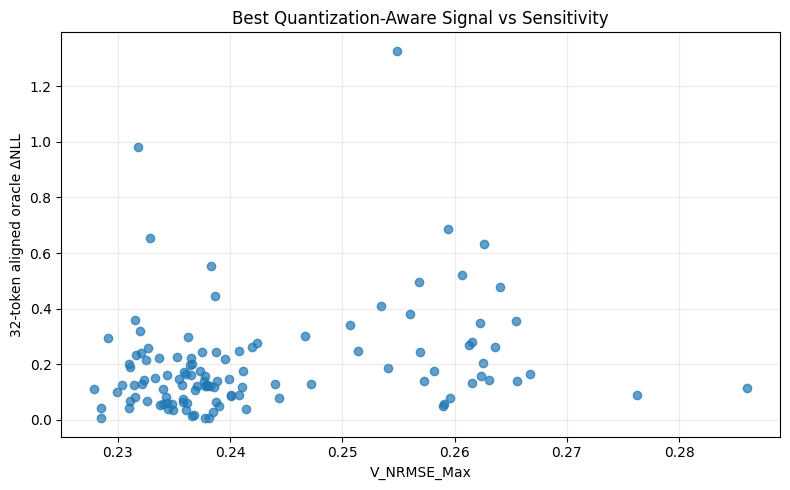


Tier summary using strongest continuous signal
---------------------------------------------


,Tier,Pages,Mean_Delta_NLL,Mean_Best_Quant_Feature,Median_Best_Quant_Feature
0,Low,61,0.087849,0.240379,0.237076
1,Medium,36,0.218115,0.242600,0.237428
2,High,18,0.532917,0.249896,0.254169



Cell 8 complete.
Quantization-aware signals have been evaluated against the 32-token delay-aligned oracle.


In [8]:
# ============================================================
# Notebook 07
# Delay-Aligned Sensitivity and Adaptive Mixed Precision
#
# Cell 8:
# Quantization-Aware Signals vs Delay-Aligned Oracle
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ------------------------------------------------------------
# 1. Fixed diagnostic thresholds
# ------------------------------------------------------------

HIGH_THRESHOLD = 0.30
LOW_THRESHOLD = 0.15


quant_eval_df = (
    quantization_analysis_df
    .copy()
)


quant_eval_df[
    "Is_High"
] = (
    quant_eval_df[
        "Delta_NLL"
    ]
    >= HIGH_THRESHOLD
).astype(int)


quant_eval_df[
    "Is_Low"
] = (
    quant_eval_df[
        "Delta_NLL"
    ]
    <= LOW_THRESHOLD
).astype(int)


print("Aligned sensitivity classes")
print("---------------------------")

print(
    f"High >= {HIGH_THRESHOLD}: "
    f"{quant_eval_df['Is_High'].sum()} pages"
)

print(
    f"Low  <= {LOW_THRESHOLD}: "
    f"{quant_eval_df['Is_Low'].sum()} pages"
)


# ------------------------------------------------------------
# 2. Predefined compact feature set
#
# These were chosen before seeing the correlations.
# ------------------------------------------------------------

QUANT_FEATURES = IMPORTANT_QUANT_FEATURES.copy()


assert len(QUANT_FEATURES) > 0


# ------------------------------------------------------------
# 3. Evaluate every signal individually
# ------------------------------------------------------------

rows = []


for feature in QUANT_FEATURES:

    values = (
        quant_eval_df[
            feature
        ]
        .to_numpy(dtype=float)
    )

    oracle = (
        quant_eval_df[
            "Delta_NLL"
        ]
        .to_numpy(dtype=float)
    )


    # --------------------------------------------------------
    # Continuous ranking
    # --------------------------------------------------------

    rho, p_value = spearmanr(
        values,
        oracle
    )


    # --------------------------------------------------------
    # HIGH-class discrimination
    #
    # First evaluate raw orientation.
    # Then report whichever orientation is stronger.
    #
    # This orientation choice is diagnostic only.
    # --------------------------------------------------------

    y_high = (
        quant_eval_df[
            "Is_High"
        ]
        .to_numpy(dtype=int)
    )


    high_auc_raw = roc_auc_score(
        y_high,
        values
    )


    if high_auc_raw >= 0.5:

        high_auc = high_auc_raw
        high_direction = "Higher -> High"

        high_score = values

    else:

        high_auc = (
            1.0
            - high_auc_raw
        )

        high_direction = "Lower -> High"

        high_score = -values


    high_ap = average_precision_score(
        y_high,
        high_score
    )


    # --------------------------------------------------------
    # LOW-class discrimination
    # --------------------------------------------------------

    y_low = (
        quant_eval_df[
            "Is_Low"
        ]
        .to_numpy(dtype=int)
    )


    low_auc_raw = roc_auc_score(
        y_low,
        values
    )


    if low_auc_raw >= 0.5:

        low_auc = low_auc_raw
        low_direction = "Higher -> Low"

        low_score = values

    else:

        low_auc = (
            1.0
            - low_auc_raw
        )

        low_direction = "Lower -> Low"

        low_score = -values


    low_ap = average_precision_score(
        y_low,
        low_score
    )


    # --------------------------------------------------------
    # Variability
    # --------------------------------------------------------

    mean_value = float(
        np.mean(values)
    )

    std_value = float(
        np.std(values)
    )


    coefficient_of_variation = (
        std_value
        / max(
            abs(mean_value),
            1e-12
        )
    )


    rows.append({

        "Feature":
            feature,

        "Spearman_Rho":
            float(rho),

        "Abs_Rho":
            float(abs(rho)),

        "P_Value":
            float(p_value),

        "High_ROC_AUC":
            float(high_auc),

        "High_Direction":
            high_direction,

        "High_AP":
            float(high_ap),

        "Low_ROC_AUC":
            float(low_auc),

        "Low_Direction":
            low_direction,

        "Low_AP":
            float(low_ap),

        "Mean":
            mean_value,

        "Std":
            std_value,

        "Coeff_Variation":
            float(
                coefficient_of_variation
            ),
    })


quant_signal_results_df = pd.DataFrame(
    rows
)


# ------------------------------------------------------------
# 4. Rank by absolute Spearman correlation
# ------------------------------------------------------------

quant_signal_results_df = (
    quant_signal_results_df
    .sort_values(
        "Abs_Rho",
        ascending=False
    )
    .reset_index(drop=True)
)


print()
print(
    "Quantization-aware signal results"
)

print(
    "---------------------------------"
)

display(
    quant_signal_results_df
)


# ------------------------------------------------------------
# 5. Best continuous signals
# ------------------------------------------------------------

print()
print(
    "Top signals by |Spearman rho|"
)

print(
    "-----------------------------"
)

display(
    quant_signal_results_df[
        [
            "Feature",
            "Spearman_Rho",
            "P_Value",
            "High_ROC_AUC",
            "Low_ROC_AUC",
        ]
    ]
    .head(10)
)


# ------------------------------------------------------------
# 6. Best HIGH-sensitivity signals
# ------------------------------------------------------------

high_ranked_df = (
    quant_signal_results_df
    .sort_values(
        "High_ROC_AUC",
        ascending=False
    )
    .reset_index(drop=True)
)


print()
print(
    "Best individual HIGH-sensitivity signals"
)

print(
    "----------------------------------------"
)

display(
    high_ranked_df[
        [
            "Feature",
            "High_ROC_AUC",
            "High_Direction",
            "High_AP",
            "Spearman_Rho",
        ]
    ]
    .head(10)
)


# ------------------------------------------------------------
# 7. Best LOW-sensitivity signals
# ------------------------------------------------------------

low_ranked_df = (
    quant_signal_results_df
    .sort_values(
        "Low_ROC_AUC",
        ascending=False
    )
    .reset_index(drop=True)
)


print()
print(
    "Best individual LOW-sensitivity signals"
)

print(
    "---------------------------------------"
)

display(
    low_ranked_df[
        [
            "Feature",
            "Low_ROC_AUC",
            "Low_Direction",
            "Low_AP",
            "Spearman_Rho",
        ]
    ]
    .head(10)
)


# ------------------------------------------------------------
# 8. Store best signals
# ------------------------------------------------------------

best_quant_continuous_feature = (
    quant_signal_results_df
    .iloc[0][
        "Feature"
    ]
)

best_quant_continuous_rho = (
    quant_signal_results_df
    .iloc[0][
        "Spearman_Rho"
    ]
)


best_quant_high_feature = (
    high_ranked_df
    .iloc[0][
        "Feature"
    ]
)

best_quant_high_auc = (
    high_ranked_df
    .iloc[0][
        "High_ROC_AUC"
    ]
)


best_quant_low_feature = (
    low_ranked_df
    .iloc[0][
        "Feature"
    ]
)

best_quant_low_auc = (
    low_ranked_df
    .iloc[0][
        "Low_ROC_AUC"
    ]
)


print()
print("Best signals")
print("------------")

print(
    f"Continuous: "
    f"{best_quant_continuous_feature}"
)

print(
    f"  rho = "
    f"{best_quant_continuous_rho:.4f}"
)

print()

print(
    f"High sensitivity: "
    f"{best_quant_high_feature}"
)

print(
    f"  AUC = "
    f"{best_quant_high_auc:.4f}"
)

print()

print(
    f"Low sensitivity: "
    f"{best_quant_low_feature}"
)

print(
    f"  AUC = "
    f"{best_quant_low_auc:.4f}"
)


# ------------------------------------------------------------
# 9. Scatter of strongest continuous signal
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)


plt.scatter(

    quant_eval_df[
        best_quant_continuous_feature
    ],

    quant_eval_df[
        "Delta_NLL"
    ],

    alpha=0.7
)


plt.xlabel(
    best_quant_continuous_feature
)

plt.ylabel(
    "32-token aligned oracle ΔNLL"
)

plt.title(
    "Best Quantization-Aware Signal vs Sensitivity"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 10. Compare high/medium/low distributions
# ------------------------------------------------------------

def assign_tier(delta_nll):

    if delta_nll <= LOW_THRESHOLD:
        return "Low"

    if delta_nll >= HIGH_THRESHOLD:
        return "High"

    return "Medium"


quant_eval_df[
    "Sensitivity_Tier"
] = (
    quant_eval_df[
        "Delta_NLL"
    ]
    .apply(
        assign_tier
    )
)


tier_summary_rows = []


for tier in [
    "Low",
    "Medium",
    "High",
]:

    subset = quant_eval_df[
        quant_eval_df[
            "Sensitivity_Tier"
        ] == tier
    ]


    tier_summary_rows.append({

        "Tier":
            tier,

        "Pages":
            len(subset),

        "Mean_Delta_NLL":
            subset[
                "Delta_NLL"
            ].mean(),

        "Mean_Best_Quant_Feature":
            subset[
                best_quant_continuous_feature
            ].mean(),

        "Median_Best_Quant_Feature":
            subset[
                best_quant_continuous_feature
            ].median(),
    })


quant_tier_summary_df = pd.DataFrame(
    tier_summary_rows
)


print()
print(
    "Tier summary using strongest continuous signal"
)

print(
    "---------------------------------------------"
)

display(
    quant_tier_summary_df
)


# ------------------------------------------------------------
# 11. Save
# ------------------------------------------------------------

quant_signal_results_path = (
    NB7_WORK_DIR
    / "quantization_signal_evaluation.csv"
)


quant_signal_results_df.to_csv(
    quant_signal_results_path,
    index=False
)


quant_tier_summary_path = (
    NB7_WORK_DIR
    / "quantization_signal_tier_summary.csv"
)


quant_tier_summary_df.to_csv(
    quant_tier_summary_path,
    index=False
)


print()
print("Cell 8 complete.")

print(
    "Quantization-aware signals have been evaluated "
    "against the 32-token delay-aligned oracle."
)

Right now V_NRMSE_Max looks genuinely interesting: it has \(\rho=0.2523\), \(p=0.0065\), high-side AUC \(0.6787\), and low-side AUC \(0.6035\). But those AUCs are conditional on exactly those two class definitions.

So I'd insert Cell 8A before Cell 9.

We want to answer:

If “high sensitivity” means 0.25 instead of 0.30, does the signal still work?

and:

If “safe/low” means 0.10 instead of 0.15, does it become easier or harder to detect?

Importantly, the continuous Spearman result does not depend on these thresholds, so:

$$ \rho=0.2523 $$

remains our threshold-independent evidence.

Primary fixed quantization-aware signal:
V_NRMSE_Max

LOW-sensitivity threshold sweep
Using lower V_NRMSE_Max as evidence of low sensitivity
--------------------------------


,Oracle_Threshold,Positive_Pages,Negative_Pages,Positive_Rate,ROC_AUC,Average_Precision,AP_Over_Random
0,0.050,13,102,0.113043,0.634992,0.238270,2.107777
1,0.075,24,91,0.208696,0.662546,0.323824,1.551659
2,0.100,33,82,0.286957,0.602735,0.363995,1.268466
3,0.125,45,70,0.391304,0.624762,0.523880,1.338805
4,0.150,61,54,0.530435,0.603522,0.630100,1.187894
5,0.175,69,46,0.600000,0.591682,0.672410,1.120684
6,0.200,74,41,0.643478,0.595254,0.710860,1.104715



HIGH-sensitivity threshold sweep
Using higher V_NRMSE_Max as evidence of high sensitivity
---------------------------------


,Oracle_Threshold,Positive_Pages,Negative_Pages,Positive_Rate,ROC_AUC,Average_Precision,AP_Over_Random
0,0.20,41,74,0.356522,0.595254,0.446284,1.251771
1,0.25,26,89,0.226087,0.668971,0.375454,1.660660
2,0.30,18,97,0.156522,0.678694,0.282739,1.806387
3,0.35,14,101,0.121739,0.679632,0.239534,1.967599
4,0.40,11,104,0.095652,0.687063,0.184906,1.933105
5,0.45,9,106,0.078261,0.684486,0.171658,2.193404
6,0.50,7,108,0.060870,0.619048,0.112112,1.841846


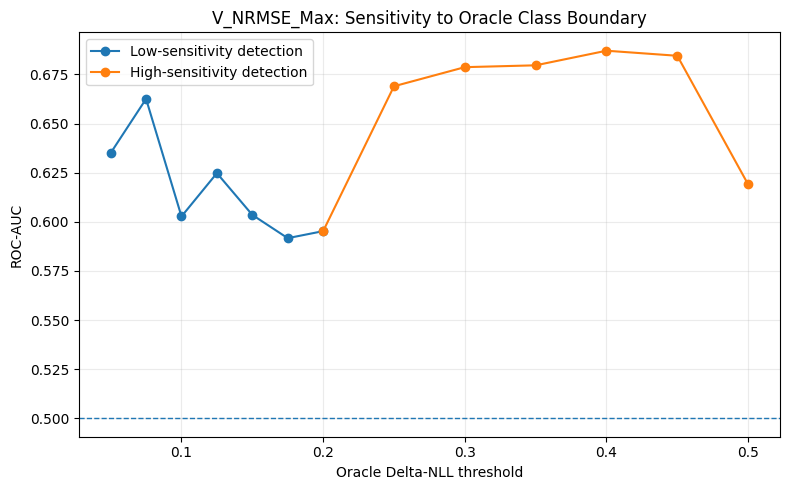

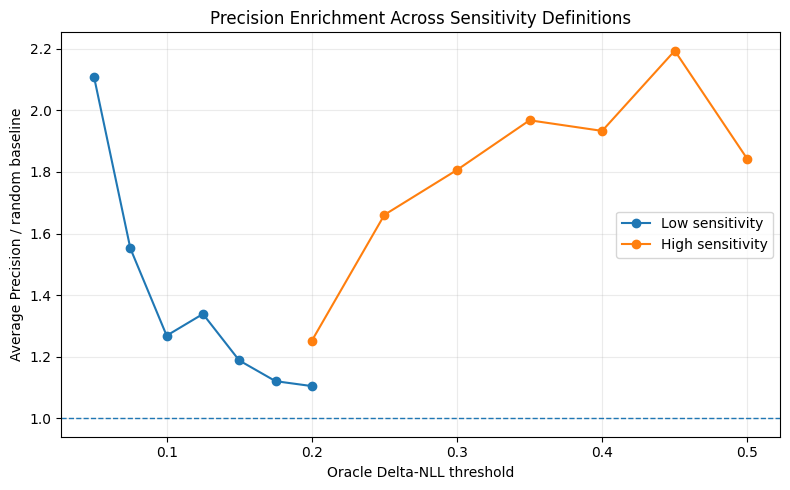


Exploratory best feature at each threshold
------------------------------------------


,Task,Oracle_Threshold,Positive_Pages,Best_Feature,Direction,Best_AUC
0,Low,0.050,13,V_ScaleMean_Mean,Lower,0.665913
1,Low,0.075,24,V_NRMSE_Max,Lower,0.662546
2,Low,0.100,33,V_HighCodeFraction_Mean,Lower,0.634516
3,Low,0.125,45,V_ZeroFraction_Mean,Lower,0.652698
4,Low,0.150,61,V_NRMSE_Max,Lower,0.603522
5,Low,0.175,69,K_PeakToRMS_Mean,Higher,0.600504
6,Low,0.200,74,K_PeakToRMS_Mean,Higher,0.638761
7,High,0.200,41,K_PeakToRMS_Mean,Lower,0.638761
8,High,0.250,26,V_NRMSE_Max,Higher,0.668971
9,High,0.300,18,V_NRMSE_Max,Higher,0.678694



Cell 8A complete.
Quantization-aware signal robustness has been tested across multiple Delta-NLL class boundaries.


In [9]:
# ============================================================
# Notebook 07
# Cell 8A:
# Sensitivity Threshold Sweep
#
# Goal:
# Test whether quantization-aware classification results
# depend strongly on the chosen Delta-NLL class boundaries.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ------------------------------------------------------------
# 1. Threshold ranges
#
# These remain DIAGNOSTIC oracle thresholds.
# They are NOT final runtime policy thresholds.
# ------------------------------------------------------------

LOW_ORACLE_THRESHOLDS = [
    0.05,
    0.075,
    0.10,
    0.125,
    0.15,
    0.175,
    0.20,
]


HIGH_ORACLE_THRESHOLDS = [
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
]


# ------------------------------------------------------------
# 2. Use the strongest threshold-independent signal from
#    Cell 8 as our PRIMARY signal.
#
# We fix the feature before doing this sweep so that we do not
# choose a different feature separately for every threshold.
# ------------------------------------------------------------

PRIMARY_QUANT_SIGNAL = (
    best_quant_continuous_feature
)

print(
    "Primary fixed quantization-aware signal:"
)

print(
    PRIMARY_QUANT_SIGNAL
)


signal = quant_eval_df[
    PRIMARY_QUANT_SIGNAL
].to_numpy(dtype=float)

oracle = quant_eval_df[
    "Delta_NLL"
].to_numpy(dtype=float)


# ------------------------------------------------------------
# Cell 8 found:
#
# Higher V_NRMSE_Max -> more sensitive
#
# Therefore:
#
# HIGH classification score = +signal
# LOW classification score  = -signal
# ------------------------------------------------------------

high_score = signal

low_score = -signal


# ============================================================
# 3. LOW-threshold sweep
# ============================================================

low_rows = []


for threshold in LOW_ORACLE_THRESHOLDS:

    labels = (
        oracle <= threshold
    ).astype(int)

    positives = int(
        labels.sum()
    )

    negatives = int(
        len(labels) - positives
    )


    if (
        positives == 0
        or negatives == 0
    ):
        continue


    auc = roc_auc_score(
        labels,
        low_score
    )

    ap = average_precision_score(
        labels,
        low_score
    )

    prevalence = float(
        labels.mean()
    )


    low_rows.append({

        "Oracle_Threshold":
            threshold,

        "Positive_Pages":
            positives,

        "Negative_Pages":
            negatives,

        "Positive_Rate":
            prevalence,

        "ROC_AUC":
            float(auc),

        "Average_Precision":
            float(ap),

        "AP_Over_Random":
            float(
                ap / prevalence
            ),
    })


low_threshold_sweep_df = pd.DataFrame(
    low_rows
)


# ============================================================
# 4. HIGH-threshold sweep
# ============================================================

high_rows = []


for threshold in HIGH_ORACLE_THRESHOLDS:

    labels = (
        oracle >= threshold
    ).astype(int)

    positives = int(
        labels.sum()
    )

    negatives = int(
        len(labels) - positives
    )


    if (
        positives == 0
        or negatives == 0
    ):
        continue


    auc = roc_auc_score(
        labels,
        high_score
    )

    ap = average_precision_score(
        labels,
        high_score
    )

    prevalence = float(
        labels.mean()
    )


    high_rows.append({

        "Oracle_Threshold":
            threshold,

        "Positive_Pages":
            positives,

        "Negative_Pages":
            negatives,

        "Positive_Rate":
            prevalence,

        "ROC_AUC":
            float(auc),

        "Average_Precision":
            float(ap),

        "AP_Over_Random":
            float(
                ap / prevalence
            ),
    })


high_threshold_sweep_df = pd.DataFrame(
    high_rows
)


# ============================================================
# 5. Display
# ============================================================

print()
print(
    "LOW-sensitivity threshold sweep"
)

print(
    "Using lower "
    f"{PRIMARY_QUANT_SIGNAL} "
    "as evidence of low sensitivity"
)

print(
    "--------------------------------"
)

display(
    low_threshold_sweep_df
)


print()
print(
    "HIGH-sensitivity threshold sweep"
)

print(
    "Using higher "
    f"{PRIMARY_QUANT_SIGNAL} "
    "as evidence of high sensitivity"
)

print(
    "---------------------------------"
)

display(
    high_threshold_sweep_df
)


# ============================================================
# 6. Plot AUC vs oracle threshold
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    low_threshold_sweep_df[
        "Oracle_Threshold"
    ],
    low_threshold_sweep_df[
        "ROC_AUC"
    ],
    marker="o",
    label="Low-sensitivity detection"
)

plt.plot(
    high_threshold_sweep_df[
        "Oracle_Threshold"
    ],
    high_threshold_sweep_df[
        "ROC_AUC"
    ],
    marker="o",
    label="High-sensitivity detection"
)

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Oracle Delta-NLL threshold"
)

plt.ylabel(
    "ROC-AUC"
)

plt.title(
    f"{PRIMARY_QUANT_SIGNAL}: "
    "Sensitivity to Oracle Class Boundary"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 7. AP relative to random prevalence
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    low_threshold_sweep_df[
        "Oracle_Threshold"
    ],
    low_threshold_sweep_df[
        "AP_Over_Random"
    ],
    marker="o",
    label="Low sensitivity"
)

plt.plot(
    high_threshold_sweep_df[
        "Oracle_Threshold"
    ],
    high_threshold_sweep_df[
        "AP_Over_Random"
    ],
    marker="o",
    label="High sensitivity"
)

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Oracle Delta-NLL threshold"
)

plt.ylabel(
    "Average Precision / random baseline"
)

plt.title(
    "Precision Enrichment Across Sensitivity Definitions"
)

plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# 8. OPTIONAL exploratory check:
#    best individual feature at EACH threshold
#
# Important:
# This is exploratory feature discovery, NOT an unbiased
# performance estimate, because we choose the best feature
# on the same data used to evaluate it.
# ============================================================

best_feature_rows = []


for task, thresholds in [

    (
        "Low",
        LOW_ORACLE_THRESHOLDS
    ),

    (
        "High",
        HIGH_ORACLE_THRESHOLDS
    ),
]:

    for threshold in thresholds:

        if task == "Low":

            labels = (
                oracle <= threshold
            ).astype(int)

        else:

            labels = (
                oracle >= threshold
            ).astype(int)


        if (
            labels.sum() == 0
            or labels.sum() == len(labels)
        ):
            continue


        candidates = []


        for feature in QUANT_FEATURES:

            values = (
                quant_eval_df[
                    feature
                ]
                .to_numpy(dtype=float)
            )


            raw_auc = roc_auc_score(
                labels,
                values
            )


            if raw_auc >= 0.5:

                oriented_auc = raw_auc
                direction = "Higher"

            else:

                oriented_auc = (
                    1.0 - raw_auc
                )

                direction = "Lower"


            candidates.append({

                "Feature":
                    feature,

                "AUC":
                    oriented_auc,

                "Direction":
                    direction,
            })


        best = max(
            candidates,
            key=lambda x: x["AUC"]
        )


        best_feature_rows.append({

            "Task":
                task,

            "Oracle_Threshold":
                threshold,

            "Positive_Pages":
                int(labels.sum()),

            "Best_Feature":
                best["Feature"],

            "Direction":
                best["Direction"],

            "Best_AUC":
                best["AUC"],
        })


best_feature_by_threshold_df = pd.DataFrame(
    best_feature_rows
)


print()
print(
    "Exploratory best feature at each threshold"
)

print(
    "------------------------------------------"
)

display(
    best_feature_by_threshold_df
)


# ============================================================
# 9. Save
# ============================================================

low_path = (
    NB7_WORK_DIR
    / "low_oracle_threshold_sweep.csv"
)

high_path = (
    NB7_WORK_DIR
    / "high_oracle_threshold_sweep.csv"
)

best_path = (
    NB7_WORK_DIR
    / "best_quant_feature_by_threshold.csv"
)


low_threshold_sweep_df.to_csv(
    low_path,
    index=False
)

high_threshold_sweep_df.to_csv(
    high_path,
    index=False
)

best_feature_by_threshold_df.to_csv(
    best_path,
    index=False
)


print()
print(
    "Cell 8A complete."
)

print(
    "Quantization-aware signal robustness "
    "has been tested across multiple "
    "Delta-NLL class boundaries."
)

The threshold sweep is encouraging because the quantization-aware signal is not tied to one arbitrary cutoff.

For the fixed signal V_NRMSE_Max, low-sensitivity detection stays above random across every tested low threshold. The strongest fixed-signal low result is around:

$$ \Delta NLL \le 0.075 $$

with

$$ \boxed{AUC=0.6625} $$

for 24 pages. Even the stricter \(\Delta NLL\le0.05\) case gets \(AUC=0.635\) and AP about \(2.11\times\) random.

On the high side, the behavior is even more stable. V_NRMSE_Max gives roughly:

$$ AUC\approx0.67-0.69 $$

for thresholds from \(0.25\) through \(0.45\). The best fixed-signal result is at \(\Delta NLL\ge0.40\):

$$ \boxed{AUC=0.6871} $$

but that class contains only 11 pages, so I would not declare \(0.40\) the “best” high threshold based on this one sequence.

Another useful finding is that the exploratory best feature changes somewhat on the low side, while V_NRMSE_Max dominates most of the high thresholds. That suggests:

high sensitivity: V_NRMSE_Max looks like a fairly robust signal;
low sensitivity: there may be complementary information in several quantization features.

So I would not lock the final policy to 0.15 / 0.30. Those are only analysis labels.

For the next classifier experiment, we'll test a few representative boundaries rather than just one:

$$ T_{\text{low}}\in\{0.075,0.10,0.15\} $$ $$ T_{\text{high}}\in\{0.25,0.30,0.40\}. $$

That lets us see whether the conclusion is stable without overfitting to whichever single threshold happened to give the highest AUC.

### Cell 8A — Sensitivity-Threshold Robustness

The classification results from Cell 8 were initially evaluated using the diagnostic oracle boundaries:

\[
\text{Low}: \Delta NLL\le0.15
\]

and:

\[
\text{High}: \Delta NLL\ge0.30.
\]

Cell 8A tests whether the quantization-aware signal depends strongly on these particular choices.

The strongest threshold-independent feature from Cell 8,

\[
\texttt{V\_NRMSE\_Max},
\]

was held fixed while the oracle class boundary was varied.

This is important because choosing a different best feature independently for each threshold would make the evaluation overly optimistic.

---

### Low-sensitivity detection

Using lower `V_NRMSE_Max` as evidence of safer INT4 quantization, ROC-AUC remains above random for every tested threshold.

Representative results include:

\[
\Delta NLL\le0.05:
\quad
AUC=0.6350
\]

\[
\Delta NLL\le0.075:
\quad
AUC=0.6625
\]

\[
\Delta NLL\le0.10:
\quad
AUC=0.6027
\]

\[
\Delta NLL\le0.15:
\quad
AUC=0.6035.
\]

The strict \(0.05\) class contains only 13 pages, but its Average Precision is approximately:

\[
2.11\times
\]

the random prevalence baseline.

This suggests that the quantization-aware signal may be useful for identifying particularly safe pages rather than merely separating a broad low-sensitivity class.

---

### High-sensitivity detection

Using higher `V_NRMSE_Max` as evidence of larger quantization damage, performance is relatively stable over a broad range:

\[
\Delta NLL\ge0.25:
\quad
AUC=0.6690
\]

\[
\Delta NLL\ge0.30:
\quad
AUC=0.6787
\]

\[
\Delta NLL\ge0.35:
\quad
AUC=0.6796
\]

\[
\Delta NLL\ge0.40:
\quad
AUC=0.6871
\]

\[
\Delta NLL\ge0.45:
\quad
AUC=0.6845.
\]

Therefore the high-sensitivity result is not an artifact of using exactly \(0.30\) as the oracle boundary.

---

### Exploratory feature variation

When the best individual feature is allowed to change separately at each threshold, different quantization statistics become strongest for some low-sensitivity boundaries.

However, `V_NRMSE_Max` remains the strongest feature across most high-sensitivity thresholds.

This suggests that:

- high-sensitivity detection may be dominated by one robust quantization-error signal;
- low-sensitivity detection may benefit more from combining several quantization-aware features.

Because these per-threshold feature choices are selected on the same data used to evaluate them, they are treated as exploratory rather than unbiased performance estimates.

---

### Conclusion

The usefulness of quantization-aware signals is reasonably robust to the chosen oracle sensitivity boundary.

The next experiment therefore compares:

1. the old inference-time features from Notebook 06,
2. quantization-aware features alone,
3. both feature families combined,

under several representative high- and low-sensitivity definitions using blocked out-of-fold evaluation.

#9: Old signals vs quantization-aware vs combined

This is the important comparison now.

We will test three feature families:

$$ \boxed{\text{Old}} $$

attention + confidence + position + delayed attention,

$$ \boxed{\text{Quant}} $$

the predefined quantization-aware signals,

and

$$ \boxed{\text{Combined}} $$

both together.

We'll evaluate all three with the same five contiguous folds, using Logistic Regression, Random Forest, and Gradient Boosting.

In [10]:
# ============================================================
# Notebook 07
# Cell 9:
# Feature-Family Comparison Across Sensitivity Boundaries
#
# Old inference-time signals
# vs
# Quantization-aware signals
# vs
# Combined signals
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ============================================================
# 1. Build aligned feature table
# ============================================================

# Old Notebook 06 feature set from Cell 6
OLD_FEATURES = DELAYED_FEATURES.copy()


# ------------------------------------------------------------
# Quantization-aware feature set
#
# Keep the predefined Cell 8 feature family rather than
# selecting features separately for every classification limit.
# ------------------------------------------------------------

QUANT_MODEL_FEATURES = QUANT_FEATURES.copy()


# ------------------------------------------------------------
# Merge old + quantization-aware features
# ------------------------------------------------------------

model_feature_df = (

    aligned_prediction_df[
        [
            "Page",
            "Aligned_Delta_NLL",
            *OLD_FEATURES,
        ]
    ]

    .merge(

        quantization_analysis_df[
            [
                "Page",
                *QUANT_MODEL_FEATURES,
            ]
        ],

        on="Page",

        validate="one_to_one"
    )

    .sort_values("Page")

    .reset_index(drop=True)
)


assert len(model_feature_df) == 115


FEATURE_SETS = {

    "Old_NB06":
        OLD_FEATURES,

    "Quantization_Aware":
        QUANT_MODEL_FEATURES,

    "Combined":
        OLD_FEATURES
        + QUANT_MODEL_FEATURES,
}


print("Feature-set sizes")
print("-----------------")

for name, features in FEATURE_SETS.items():

    print(
        f"{name:20s}: "
        f"{len(features)} features"
    )


# ============================================================
# 2. Representative oracle boundaries
#
# These are still experimental labels,
# not final runtime thresholds.
# ============================================================

LOW_LIMITS = [
    0.075,
    0.10,
    0.15,
]

HIGH_LIMITS = [
    0.25,
    0.30,
    0.40,
]


# ============================================================
# 3. Classifier families
# ============================================================

CLASSIFIERS = {

    "LogisticRegression":

        Pipeline([
            (
                "scale",
                StandardScaler()
            ),

            (
                "model",
                LogisticRegression(
                    C=0.5,
                    class_weight="balanced",
                    max_iter=2000,
                    random_state=SEED,
                )
            ),
        ]),


    "RandomForest":

        RandomForestClassifier(
            n_estimators=300,
            max_depth=3,
            min_samples_leaf=5,
            max_features=0.7,
            class_weight="balanced_subsample",
            random_state=SEED,
            n_jobs=-1,
        ),


    "GradientBoosting":

        GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.03,
            max_depth=2,
            min_samples_leaf=5,
            loss="log_loss",
            random_state=SEED,
        ),
}


# ============================================================
# 4. Balanced sample weights
# ============================================================

def balanced_weights(y):

    y = np.asarray(y)

    n = len(y)

    n0 = np.sum(y == 0)
    n1 = np.sum(y == 1)


    w = np.ones(
        n,
        dtype=float
    )


    if n0 > 0:

        w[
            y == 0
        ] = (
            n / (2.0 * n0)
        )


    if n1 > 0:

        w[
            y == 1
        ] = (
            n / (2.0 * n1)
        )


    return w


# ============================================================
# 5. Blocked folds
# ============================================================

n_pages = len(
    model_feature_df
)

all_indices = np.arange(
    n_pages
)

blocked_folds = np.array_split(
    all_indices,
    5
)


# ============================================================
# 6. Generic OOF evaluator
# ============================================================

def blocked_oof_classifier(
    X,
    y,
    classifier_name,
    classifier_template
):

    oof_prob = np.full(
        len(y),
        np.nan,
        dtype=float
    )


    valid_fold_aucs = []


    for test_idx in blocked_folds:

        train_mask = np.ones(
            len(y),
            dtype=bool
        )

        train_mask[
            test_idx
        ] = False

        train_idx = (
            all_indices[
                train_mask
            ]
        )


        # Training must contain both classes.
        if len(
            np.unique(
                y[train_idx]
            )
        ) < 2:

            raise RuntimeError(
                "Training fold contains only one class."
            )


        clf = clone(
            classifier_template
        )


        if (
            classifier_name
            == "GradientBoosting"
        ):

            weights = (
                balanced_weights(
                    y[train_idx]
                )
            )

            clf.fit(
                X[train_idx],
                y[train_idx],
                sample_weight=weights
            )

        else:

            clf.fit(
                X[train_idx],
                y[train_idx]
            )


        probs = clf.predict_proba(
            X[test_idx]
        )[:, 1]


        oof_prob[
            test_idx
        ] = probs


        # Fold AUC only if test block
        # contains both classes.
        if len(
            np.unique(
                y[test_idx]
            )
        ) == 2:

            valid_fold_aucs.append(

                roc_auc_score(
                    y[test_idx],
                    probs
                )
            )


    assert np.isfinite(
        oof_prob
    ).all()


    overall_auc = roc_auc_score(
        y,
        oof_prob
    )

    overall_ap = average_precision_score(
        y,
        oof_prob
    )


    return {

        "OOF_Probability":
            oof_prob,

        "ROC_AUC":
            float(overall_auc),

        "Average_Precision":
            float(overall_ap),

        "Mean_Valid_Fold_AUC":
            float(
                np.mean(
                    valid_fold_aucs
                )
            )
            if len(valid_fold_aucs) > 0
            else np.nan,

        "Std_Valid_Fold_AUC":
            float(
                np.std(
                    valid_fold_aucs
                )
            )
            if len(valid_fold_aucs) > 0
            else np.nan,

        "Valid_AUC_Folds":
            len(
                valid_fold_aucs
            ),
    }


# ============================================================
# 7. Run all experiments
# ============================================================

experiment_rows = []

oof_predictions = {}


oracle_values = (
    model_feature_df[
        "Aligned_Delta_NLL"
    ]
    .to_numpy(dtype=float)
)


TASKS = []


for threshold in LOW_LIMITS:

    TASKS.append({

        "Task":
            "Low",

        "Threshold":
            threshold,

        "Labels":
            (
                oracle_values
                <= threshold
            ).astype(int),
    })


for threshold in HIGH_LIMITS:

    TASKS.append({

        "Task":
            "High",

        "Threshold":
            threshold,

        "Labels":
            (
                oracle_values
                >= threshold
            ).astype(int),
    })


for task_info in TASKS:

    task = (
        task_info[
            "Task"
        ]
    )

    threshold = (
        task_info[
            "Threshold"
        ]
    )

    y = (
        task_info[
            "Labels"
        ]
    )


    prevalence = float(
        y.mean()
    )


    print(
        f"\n{task} sensitivity, "
        f"threshold={threshold}"
    )

    print(
        f"Positive pages: "
        f"{int(y.sum())}/115"
    )


    for feature_set_name, features in (
        FEATURE_SETS.items()
    ):

        X = (
            model_feature_df[
                features
            ]
            .to_numpy(dtype=float)
        )


        assert np.isfinite(
            X
        ).all()


        for classifier_name, classifier in (
            CLASSIFIERS.items()
        ):

            result = (
                blocked_oof_classifier(

                    X,
                    y,

                    classifier_name,

                    classifier
                )
            )


            key = (

                task,

                threshold,

                feature_set_name,

                classifier_name,
            )


            oof_predictions[
                key
            ] = result[
                "OOF_Probability"
            ]


            experiment_rows.append({

                "Task":
                    task,

                "Oracle_Threshold":
                    threshold,

                "Feature_Set":
                    feature_set_name,

                "Classifier":
                    classifier_name,

                "Num_Features":
                    len(features),

                "Positive_Pages":
                    int(
                        y.sum()
                    ),

                "Positive_Rate":
                    prevalence,

                "ROC_AUC":
                    result[
                        "ROC_AUC"
                    ],

                "Average_Precision":
                    result[
                        "Average_Precision"
                    ],

                "AP_Over_Random":
                    result[
                        "Average_Precision"
                    ]
                    / prevalence,

                "Mean_Valid_Fold_AUC":
                    result[
                        "Mean_Valid_Fold_AUC"
                    ],

                "Std_Valid_Fold_AUC":
                    result[
                        "Std_Valid_Fold_AUC"
                    ],

                "Valid_AUC_Folds":
                    result[
                        "Valid_AUC_Folds"
                    ],
            })


# ============================================================
# 8. Result table
# ============================================================

feature_family_results_df = pd.DataFrame(
    experiment_rows
)


feature_family_results_df = (
    feature_family_results_df
    .sort_values(
        [
            "Task",
            "Oracle_Threshold",
            "ROC_AUC",
        ],
        ascending=[
            True,
            True,
            False,
        ]
    )
    .reset_index(drop=True)
)


print()
print(
    "Full feature-family comparison"
)

print(
    "------------------------------"
)

display(
    feature_family_results_df
)


# ============================================================
# 9. Best configuration for each task/limit
# ============================================================

best_by_limit_df = (

    feature_family_results_df

    .sort_values(
        "ROC_AUC",
        ascending=False
    )

    .groupby(
        [
            "Task",
            "Oracle_Threshold",
        ],
        as_index=False
    )

    .first()
)


print()
print(
    "Best configuration at each oracle limit"
)

print(
    "---------------------------------------"
)

display(
    best_by_limit_df[
        [
            "Task",
            "Oracle_Threshold",
            "Positive_Pages",
            "Feature_Set",
            "Classifier",
            "ROC_AUC",
            "Average_Precision",
            "AP_Over_Random",
            "Mean_Valid_Fold_AUC",
            "Std_Valid_Fold_AUC",
        ]
    ]
)


# ============================================================
# 10. Feature-family averages
#
# This is only a compact robustness summary.
# ============================================================

family_summary_df = (

    feature_family_results_df

    .groupby(
        [
            "Task",
            "Feature_Set",
        ]
    )

    .agg(

        Mean_AUC=(
            "ROC_AUC",
            "mean"
        ),

        Median_AUC=(
            "ROC_AUC",
            "median"
        ),

        Best_AUC=(
            "ROC_AUC",
            "max"
        ),

        Mean_AP_Over_Random=(
            "AP_Over_Random",
            "mean"
        ),
    )

    .reset_index()
)


print()
print(
    "Feature-family robustness summary"
)

print(
    "---------------------------------"
)

display(
    family_summary_df
)


# ============================================================
# 11. Save
# ============================================================

family_results_path = (
    NB7_WORK_DIR
    / "feature_family_classification_results.csv"
)


best_limit_path = (
    NB7_WORK_DIR
    / "best_configuration_by_oracle_limit.csv"
)


family_summary_path = (
    NB7_WORK_DIR
    / "feature_family_summary.csv"
)


feature_family_results_df.to_csv(
    family_results_path,
    index=False
)

best_by_limit_df.to_csv(
    best_limit_path,
    index=False
)

family_summary_df.to_csv(
    family_summary_path,
    index=False
)


print()
print("Cell 9 complete.")

print(
    "Old, quantization-aware, and combined "
    "feature families have been compared "
    "under multiple aligned sensitivity limits."
)

Feature-set sizes
-----------------
Old_NB06            : 17 features
Quantization_Aware  : 15 features
Combined            : 32 features

Low sensitivity, threshold=0.075
Positive pages: 24/115

Low sensitivity, threshold=0.1
Positive pages: 33/115

Low sensitivity, threshold=0.15
Positive pages: 61/115

High sensitivity, threshold=0.25
Positive pages: 26/115

High sensitivity, threshold=0.3
Positive pages: 18/115

High sensitivity, threshold=0.4
Positive pages: 11/115

Full feature-family comparison
------------------------------


,Task,Oracle_Threshold,Feature_Set,Classifier,Num_Features,Positive_Pages,Positive_Rate,ROC_AUC,Average_Precision,AP_Over_Random,Mean_Valid_Fold_AUC,Std_Valid_Fold_AUC,Valid_AUC_Folds
0,High,0.250,Quantization_Aware,GradientBoosting,15,26,0.226087,0.579948,0.346872,1.534244,0.650794,0.178316,5
1,High,0.250,Quantization_Aware,RandomForest,15,26,0.226087,0.557476,0.347242,1.535880,0.674921,0.174575,5
2,High,0.250,Combined,GradientBoosting,32,26,0.226087,0.520743,0.371726,1.644172,0.718846,0.198519,5
3,High,0.250,Quantization_Aware,LogisticRegression,15,26,0.226087,0.477960,0.237160,1.048978,0.622771,0.167357,5
4,High,0.250,Combined,LogisticRegression,32,26,0.226087,0.468021,0.233197,1.031447,0.646724,0.080592,5
5,High,0.250,Combined,RandomForest,32,26,0.226087,0.397148,0.229013,1.012944,0.627128,0.145235,5
6,High,0.250,Old_NB06,RandomForest,17,26,0.226087,0.343561,0.178259,0.788453,0.449697,0.149518,5
7,High,0.250,Old_NB06,GradientBoosting,17,26,0.226087,0.340968,0.184740,0.817120,0.433189,0.148264,5
8,High,0.250,Old_NB06,LogisticRegression,17,26,0.226087,0.321953,0.210678,0.931846,0.500808,0.142810,5
9,High,0.300,Quantization_Aware,GradientBoosting,15,18,0.156522,0.526346,0.170248,1.087697,0.524991,0.130498,4



Best configuration at each oracle limit
---------------------------------------


,Task,Oracle_Threshold,Positive_Pages,Feature_Set,Classifier,ROC_AUC,Average_Precision,AP_Over_Random,Mean_Valid_Fold_AUC,Std_Valid_Fold_AUC
0,High,0.250,26,Quantization_Aware,GradientBoosting,0.579948,0.346872,1.534244,0.650794,0.178316
1,High,0.300,18,Quantization_Aware,GradientBoosting,0.526346,0.170248,1.087697,0.524991,0.130498
2,High,0.400,11,Quantization_Aware,GradientBoosting,0.570804,0.235148,2.458362,0.627022,0.212921
3,Low,0.075,24,Quantization_Aware,LogisticRegression,0.642857,0.337039,1.614978,0.677426,0.093094
4,Low,0.100,33,Old_NB06,GradientBoosting,0.657058,0.449966,1.568065,0.586369,0.151578
5,Low,0.150,61,Old_NB06,GradientBoosting,0.503795,0.603137,1.137061,0.389124,0.133423



Feature-family robustness summary
---------------------------------


,Task,Feature_Set,Mean_AUC,Median_AUC,Best_AUC,Mean_AP_Over_Random
0,High,Combined,0.410127,0.429633,0.520743,0.990977
1,High,Old_NB06,0.342381,0.340968,0.421329,0.950815
2,High,Quantization_Aware,0.497812,0.478809,0.579948,1.364437
3,Low,Combined,0.520510,0.519689,0.640798,1.235506
4,Low,Old_NB06,0.539238,0.556319,0.657058,1.195199
5,Low,Quantization_Aware,0.532107,0.542868,0.642857,1.253569



Cell 9 complete.
Old, quantization-aware, and combined feature families have been compared under multiple aligned sensitivity limits.


### Cell 9 — Feature-Family Comparison

Cell 9 compares three deployable feature families using five contiguous out-of-fold blocks:

1. Notebook 06 attention/confidence/position signals,
2. quantization-aware signals,
3. all signals combined.

Several oracle sensitivity boundaries were evaluated rather than relying on one arbitrary definition.

---

### High-sensitivity prediction

Quantization-aware features provide the strongest high-sensitivity results at every tested boundary.

The best configurations obtain approximately:

$$AUC=0.580$$

for:

$$\Delta NLL\ge0.25,$$

$$AUC=0.526$$

for:

$$\Delta NLL\ge0.30,$$

and:

$$AUC=0.571$$

for:

$$\Delta NLL\ge0.40.$$

The old Notebook 06 feature family performs substantially worse.

Combining all 32 features also fails to improve performance consistently.

Thus adding attention/confidence features to the quantization-aware features does not automatically create a stronger predictor.

---

### Low-sensitivity prediction

The low-sensitivity problem depends more strongly on how strictly "safe" is defined.

For:

$$\Delta NLL\le0.075,$$

the strongest model is:

$$\text{Quantization-aware + Logistic Regression}$$

with:

$$AUC=0.6429.$$

For:

$$\Delta NLL\le0.10,$$

the strongest observed model is the old Notebook 06 Gradient Boosting predictor:

$$AUC=0.6571.$$

However, for the broader:

$$\Delta NLL\le0.15$$

definition, performance falls to approximately random.

This suggests that it may be more practical to identify a small set of very safe pages than to accurately classify every moderately low-sensitivity page.

---

### Combined feature set

The full 32-feature combination does not consistently outperform either smaller family.

Given that the experiment contains only 115 pages, this behavior is consistent with additional features increasing variance and overfitting rather than adding robust predictive information.

Therefore the next experiment avoids another large generic feature set.

Instead, it tests a small mechanism-driven interaction:

$$\text{quantization distortion} \times \text{observed page usage}.$$

The hypothesis is that quantization damage should be largest when a page is both numerically difficult to represent and actively used by subsequent attention.

#10: Attention-weighted quantization risk

In [11]:
# ============================================================
# Notebook 07
# Cell 10:
# Mechanistic Attention-Weighted Quantization Risk
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ============================================================
# 1. Construct compact mechanism-based features
# ============================================================

mechanistic_df = (
    model_feature_df
    .copy()
)


# ------------------------------------------------------------
# Primary numerical-distortion signal
# ------------------------------------------------------------

DISTORTION_FEATURE = (
    "V_NRMSE_Max"
)


# ------------------------------------------------------------
# Attention received by the target page during its
# two-page observation window.
# ------------------------------------------------------------

ATTENTION_FEATURE = (
    "DelayedAttn_Mean_Mean"
)


# ------------------------------------------------------------
# Explicit interaction:
#
# risk = numerical distortion * observed usage
# ------------------------------------------------------------

mechanistic_df[
    "VNRMSE_x_DelayedAttn"
] = (

    mechanistic_df[
        DISTORTION_FEATURE
    ]

    *

    mechanistic_df[
        ATTENTION_FEATURE
    ]
)


# ------------------------------------------------------------
# Additional predefined interactions using alternative
# delayed-attention summaries.
#
# These are all defined BEFORE evaluation.
# ------------------------------------------------------------

mechanistic_df[
    "VNRMSE_x_DelayedAttnMax"
] = (

    mechanistic_df[
        DISTORTION_FEATURE
    ]

    *

    mechanistic_df[
        "DelayedAttn_Mean_Max"
    ]
)


mechanistic_df[
    "VNRMSE_x_DelayedLastMean"
] = (

    mechanistic_df[
        DISTORTION_FEATURE
    ]

    *

    mechanistic_df[
        "DelayedAttn_Last_Mean"
    ]
)


mechanistic_df[
    "VNRMSE_x_DelayedLastMax"
] = (

    mechanistic_df[
        DISTORTION_FEATURE
    ]

    *

    mechanistic_df[
        "DelayedAttn_Last_Max"
    ]
)


# ------------------------------------------------------------
# KV reconstruction interaction as an ablation
# ------------------------------------------------------------

mechanistic_df[
    "KVNRMSE_x_DelayedAttn"
] = (

    mechanistic_df[
        "KV_NRMSE_Mean"
    ]

    *

    mechanistic_df[
        ATTENTION_FEATURE
    ]
)


MECHANISTIC_SIGNALS = [

    "V_NRMSE_Max",

    "DelayedAttn_Mean_Mean",

    "VNRMSE_x_DelayedAttn",

    "VNRMSE_x_DelayedAttnMax",

    "VNRMSE_x_DelayedLastMean",

    "VNRMSE_x_DelayedLastMax",

    "KVNRMSE_x_DelayedAttn",
]


assert np.isfinite(
    mechanistic_df[
        MECHANISTIC_SIGNALS
    ].to_numpy()
).all()


# ============================================================
# 2. Continuous correlation with aligned Delta NLL
# ============================================================

from scipy.stats import spearmanr


continuous_rows = []


for feature in MECHANISTIC_SIGNALS:

    rho, p = spearmanr(

        mechanistic_df[
            feature
        ],

        mechanistic_df[
            "Aligned_Delta_NLL"
        ]
    )


    continuous_rows.append({

        "Feature":
            feature,

        "Spearman_Rho":
            float(rho),

        "Abs_Rho":
            float(abs(rho)),

        "P_Value":
            float(p),
    })


mechanistic_correlation_df = (

    pd.DataFrame(
        continuous_rows
    )

    .sort_values(
        "Abs_Rho",
        ascending=False
    )

    .reset_index(drop=True)
)


print(
    "Mechanistic signal correlations"
)

print(
    "-------------------------------"
)

display(
    mechanistic_correlation_df
)


# ============================================================
# 3. Fixed-signal AUCs
#
# Higher risk is assumed to mean:
#
#   more likely HIGH sensitivity
#
# Lower risk is assumed to mean:
#
#   more likely LOW sensitivity
#
# We do NOT flip orientation after seeing the results.
# ============================================================

FIXED_LOW_LIMITS = [
    0.075,
    0.10,
]

FIXED_HIGH_LIMITS = [
    0.25,
    0.30,
    0.40,
]


oracle = (
    mechanistic_df[
        "Aligned_Delta_NLL"
    ]
    .to_numpy(dtype=float)
)


fixed_signal_rows = []


for feature in MECHANISTIC_SIGNALS:

    score = (
        mechanistic_df[
            feature
        ]
        .to_numpy(dtype=float)
    )


    # --------------------------------------------------------
    # HIGH
    # --------------------------------------------------------

    for threshold in FIXED_HIGH_LIMITS:

        labels = (
            oracle >= threshold
        ).astype(int)


        auc = roc_auc_score(
            labels,
            score
        )

        ap = average_precision_score(
            labels,
            score
        )

        prevalence = float(
            labels.mean()
        )


        fixed_signal_rows.append({

            "Task":
                "High",

            "Oracle_Threshold":
                threshold,

            "Feature":
                feature,

            "Positive_Pages":
                int(labels.sum()),

            "ROC_AUC":
                float(auc),

            "Average_Precision":
                float(ap),

            "AP_Over_Random":
                float(
                    ap / prevalence
                ),
        })


    # --------------------------------------------------------
    # LOW
    #
    # Lower risk = stronger low-sensitivity evidence.
    # --------------------------------------------------------

    for threshold in FIXED_LOW_LIMITS:

        labels = (
            oracle <= threshold
        ).astype(int)


        auc = roc_auc_score(
            labels,
            -score
        )

        ap = average_precision_score(
            labels,
            -score
        )

        prevalence = float(
            labels.mean()
        )


        fixed_signal_rows.append({

            "Task":
                "Low",

            "Oracle_Threshold":
                threshold,

            "Feature":
                feature,

            "Positive_Pages":
                int(labels.sum()),

            "ROC_AUC":
                float(auc),

            "Average_Precision":
                float(ap),

            "AP_Over_Random":
                float(
                    ap / prevalence
                ),
        })


mechanistic_signal_auc_df = (
    pd.DataFrame(
        fixed_signal_rows
    )
)


print()
print(
    "Fixed mechanistic signal classification"
)

print(
    "---------------------------------------"
)


for task in [
    "High",
    "Low",
]:

    for threshold in sorted(

        mechanistic_signal_auc_df.loc[
            mechanistic_signal_auc_df[
                "Task"
            ] == task,

            "Oracle_Threshold"
        ].unique()
    ):

        print()
        print(
            f"{task}, threshold={threshold}"
        )

        display(

            mechanistic_signal_auc_df[

                (
                    mechanistic_signal_auc_df[
                        "Task"
                    ] == task
                )

                &

                (
                    mechanistic_signal_auc_df[
                        "Oracle_Threshold"
                    ] == threshold
                )

            ]

            .sort_values(
                "ROC_AUC",
                ascending=False
            )

            .reset_index(drop=True)
        )


# ============================================================
# 4. Compact OOF Logistic Regression
#
# Instead of 15/17/32 features, test only:
#
# A. distortion alone
# B. attention alone
# C. distortion + attention
# D. distortion + attention + explicit interaction
# ============================================================

COMPACT_FEATURE_SETS = {

    "Distortion_1": [
        "V_NRMSE_Max",
    ],

    "Attention_1": [
        "DelayedAttn_Mean_Mean",
    ],

    "Distortion_Attention_2": [
        "V_NRMSE_Max",
        "DelayedAttn_Mean_Mean",
    ],

    "Mechanistic_Interaction_3": [
        "V_NRMSE_Max",
        "DelayedAttn_Mean_Mean",
        "VNRMSE_x_DelayedAttn",
    ],
}


compact_classifier = Pipeline([

    (
        "scale",
        StandardScaler()
    ),

    (
        "model",
        LogisticRegression(
            C=0.5,
            class_weight="balanced",
            max_iter=2000,
            random_state=SEED,
        )
    ),
])


# ------------------------------------------------------------
# Blocked OOF helper
# ------------------------------------------------------------

def compact_blocked_oof(
    X,
    y
):

    oof = np.full(
        len(y),
        np.nan,
        dtype=float
    )

    fold_aucs = []


    for test_idx in blocked_folds:

        train_mask = np.ones(
            len(y),
            dtype=bool
        )

        train_mask[
            test_idx
        ] = False

        train_idx = (
            all_indices[
                train_mask
            ]
        )


        clf = clone(
            compact_classifier
        )


        clf.fit(
            X[train_idx],
            y[train_idx]
        )


        prob = clf.predict_proba(
            X[test_idx]
        )[:, 1]


        oof[
            test_idx
        ] = prob


        if (
            len(
                np.unique(
                    y[test_idx]
                )
            )
            == 2
        ):

            fold_aucs.append(

                roc_auc_score(
                    y[test_idx],
                    prob
                )
            )


    assert np.isfinite(
        oof
    ).all()


    return {

        "OOF":
            oof,

        "AUC":
            roc_auc_score(
                y,
                oof
            ),

        "AP":
            average_precision_score(
                y,
                oof
            ),

        "Fold_AUC_Mean":
            np.mean(
                fold_aucs
            )
            if fold_aucs
            else np.nan,

        "Fold_AUC_Std":
            np.std(
                fold_aucs
            )
            if fold_aucs
            else np.nan,

        "Valid_Folds":
            len(
                fold_aucs
            ),
    }


compact_rows = []

compact_oof_scores = {}


# ============================================================
# 5. HIGH tasks
# ============================================================

for threshold in FIXED_HIGH_LIMITS:

    y = (
        oracle >= threshold
    ).astype(int)


    for set_name, features in (
        COMPACT_FEATURE_SETS.items()
    ):

        X = (
            mechanistic_df[
                features
            ]
            .to_numpy(dtype=float)
        )


        result = (
            compact_blocked_oof(
                X,
                y
            )
        )


        key = (
            "High",
            threshold,
            set_name,
        )


        compact_oof_scores[
            key
        ] = result[
            "OOF"
        ]


        prevalence = float(
            y.mean()
        )


        compact_rows.append({

            "Task":
                "High",

            "Oracle_Threshold":
                threshold,

            "Feature_Set":
                set_name,

            "Num_Features":
                len(features),

            "Positive_Pages":
                int(y.sum()),

            "ROC_AUC":
                float(
                    result["AUC"]
                ),

            "Average_Precision":
                float(
                    result["AP"]
                ),

            "AP_Over_Random":
                float(
                    result["AP"]
                    / prevalence
                ),

            "Mean_Valid_Fold_AUC":
                float(
                    result[
                        "Fold_AUC_Mean"
                    ]
                ),

            "Std_Valid_Fold_AUC":
                float(
                    result[
                        "Fold_AUC_Std"
                    ]
                ),

            "Valid_AUC_Folds":
                int(
                    result[
                        "Valid_Folds"
                    ]
                ),
        })


# ============================================================
# 6. LOW tasks
# ============================================================

for threshold in FIXED_LOW_LIMITS:

    y = (
        oracle <= threshold
    ).astype(int)


    for set_name, features in (
        COMPACT_FEATURE_SETS.items()
    ):

        X = (
            mechanistic_df[
                features
            ]
            .to_numpy(dtype=float)
        )


        result = (
            compact_blocked_oof(
                X,
                y
            )
        )


        key = (
            "Low",
            threshold,
            set_name,
        )


        compact_oof_scores[
            key
        ] = result[
            "OOF"
        ]


        prevalence = float(
            y.mean()
        )


        compact_rows.append({

            "Task":
                "Low",

            "Oracle_Threshold":
                threshold,

            "Feature_Set":
                set_name,

            "Num_Features":
                len(features),

            "Positive_Pages":
                int(y.sum()),

            "ROC_AUC":
                float(
                    result["AUC"]
                ),

            "Average_Precision":
                float(
                    result["AP"]
                ),

            "AP_Over_Random":
                float(
                    result["AP"]
                    / prevalence
                ),

            "Mean_Valid_Fold_AUC":
                float(
                    result[
                        "Fold_AUC_Mean"
                    ]
                ),

            "Std_Valid_Fold_AUC":
                float(
                    result[
                        "Fold_AUC_Std"
                    ]
                ),

            "Valid_AUC_Folds":
                int(
                    result[
                        "Valid_Folds"
                    ]
                ),
        })


compact_results_df = (
    pd.DataFrame(
        compact_rows
    )
)


print()
print(
    "Compact blocked-OOF models"
)

print(
    "--------------------------"
)

display(

    compact_results_df

    .sort_values(
        [
            "Task",
            "Oracle_Threshold",
            "ROC_AUC",
        ],

        ascending=[
            True,
            True,
            False,
        ]
    )

    .reset_index(drop=True)
)


# ============================================================
# 7. Best compact configuration per limit
# ============================================================

best_compact_df = (

    compact_results_df

    .sort_values(
        "ROC_AUC",
        ascending=False
    )

    .groupby(
        [
            "Task",
            "Oracle_Threshold",
        ],
        as_index=False
    )

    .first()
)


print()
print(
    "Best compact configuration per limit"
)

print(
    "------------------------------------"
)

display(
    best_compact_df
)


# ============================================================
# 8. Save
# ============================================================

mechanistic_corr_path = (
    NB7_WORK_DIR
    / "mechanistic_signal_correlations.csv"
)

mechanistic_auc_path = (
    NB7_WORK_DIR
    / "mechanistic_signal_auc.csv"
)

compact_results_path = (
    NB7_WORK_DIR
    / "compact_mechanistic_oof_results.csv"
)


mechanistic_correlation_df.to_csv(
    mechanistic_corr_path,
    index=False
)

mechanistic_signal_auc_df.to_csv(
    mechanistic_auc_path,
    index=False
)

compact_results_df.to_csv(
    compact_results_path,
    index=False
)


print()
print(
    "Cell 10 complete."
)

print(
    "Quantization distortion and delayed page usage "
    "have been tested separately and as an explicit "
    "mechanistic interaction."
)

Mechanistic signal correlations
-------------------------------


,Feature,Spearman_Rho,Abs_Rho,P_Value
0,V_NRMSE_Max,0.252316,0.252316,0.006520
1,VNRMSE_x_DelayedLastMean,0.182546,0.182546,0.050863
2,VNRMSE_x_DelayedLastMax,0.156648,0.156648,0.094554
3,VNRMSE_x_DelayedAttn,0.121431,0.121431,0.196090
4,VNRMSE_x_DelayedAttnMax,0.090855,0.090855,0.334213
5,KVNRMSE_x_DelayedAttn,0.079594,0.079594,0.397791
6,DelayedAttn_Mean_Mean,0.075909,0.075909,0.420065



Fixed mechanistic signal classification
---------------------------------------

High, threshold=0.25


,Task,Oracle_Threshold,Feature,Positive_Pages,ROC_AUC,Average_Precision,AP_Over_Random
0,High,0.25,V_NRMSE_Max,26,0.668971,0.375454,1.660660
1,High,0.25,VNRMSE_x_DelayedLastMean,26,0.641746,0.382425,1.691495
2,High,0.25,VNRMSE_x_DelayedLastMax,26,0.636128,0.377143,1.668132
3,High,0.25,VNRMSE_x_DelayedAttn,26,0.592481,0.362305,1.602503
4,High,0.25,VNRMSE_x_DelayedAttnMax,26,0.580380,0.317091,1.402516
5,High,0.25,KVNRMSE_x_DelayedAttn,26,0.563094,0.314572,1.391374
6,High,0.25,DelayedAttn_Mean_Mean,26,0.561798,0.319120,1.411491



High, threshold=0.3


...


Compact blocked-OOF models
--------------------------


,Task,Oracle_Threshold,Feature_Set,Num_Features,Positive_Pages,ROC_AUC,Average_Precision,AP_Over_Random,Mean_Valid_Fold_AUC,Std_Valid_Fold_AUC,Valid_AUC_Folds
0,High,0.250,Distortion_Attention_2,2,26,0.668539,0.371547,1.643383,0.738442,0.150332,5
1,High,0.250,Mechanistic_Interaction_3,3,26,0.667243,0.372403,1.647165,0.737489,0.154002,5
2,High,0.250,Distortion_1,1,26,0.632671,0.371477,1.643070,0.688485,0.116765,5
3,High,0.250,Attention_1,1,26,0.476232,0.234750,1.038318,0.460577,0.244257,5
4,High,0.300,Distortion_Attention_2,2,18,0.640893,0.263334,1.682412,0.710592,0.173713,4
5,High,0.300,Distortion_1,1,18,0.630584,0.270813,1.730196,0.659340,0.071303,4
6,High,0.300,Mechanistic_Interaction_3,3,18,0.628866,0.271277,1.733159,0.708360,0.176667,4
7,High,0.300,Attention_1,1,18,0.459336,0.174603,1.115521,0.491352,0.261384,4
8,High,0.400,Distortion_Attention_2,2,11,0.736014,0.312620,3.268302,0.812258,0.159624,4
9,High,0.400,Mechanistic_Interaction_3,3,11,0.733392,0.317741,3.321836,0.822126,0.148725,4



Best compact configuration per limit
------------------------------------


,Task,Oracle_Threshold,Feature_Set,Num_Features,Positive_Pages,ROC_AUC,Average_Precision,AP_Over_Random,Mean_Valid_Fold_AUC,Std_Valid_Fold_AUC,Valid_AUC_Folds
0,High,0.250,Distortion_Attention_2,2,26,0.668539,0.371547,1.643383,0.738442,0.150332,5
1,High,0.300,Distortion_Attention_2,2,18,0.640893,0.263334,1.682412,0.710592,0.173713,4
2,High,0.400,Distortion_Attention_2,2,11,0.736014,0.312620,3.268302,0.812258,0.159624,4
3,Low,0.075,Distortion_1,1,24,0.662546,0.303082,1.452270,0.588819,0.176937,5
4,Low,0.100,Distortion_1,1,33,0.559128,0.325557,1.134517,0.497421,0.102128,5



Cell 10 complete.
Quantization distortion and delayed page usage have been tested separately and as an explicit mechanistic interaction.


The emerging policy has a nice interpretation:

$$ \boxed{\text{INT4 candidate: very low numerical distortion}} $$ $$ \boxed{\text{FP16 candidate: high distortion + evidence the page is being used}} $$ $$ \boxed{\text{otherwise: INT8}} $$



### Cell 10 — Mechanistic Distortion + Usage Signals

Cell 10 tests the hypothesis that quantization sensitivity should depend jointly on:

1. how difficult a page is to represent in INT4, and
2. how much subsequent tokens actually use that page.

The primary numerical-distortion signal is:

\[
\texttt{V\_NRMSE\_Max}.
\]

The primary usage signal is delayed attention received during the 32-token observation window.

---

### High-sensitivity prediction

A compact Logistic Regression model using only:

\[
\{
\texttt{V\_NRMSE\_Max},
\texttt{DelayedAttn\_Mean\_Mean}
\}
\]

was the strongest blocked out-of-fold configuration at every tested high-sensitivity boundary.

It achieved:

\[
AUC=0.6685
\]

for:

\[
\Delta NLL\ge0.25,
\]

\[
AUC=0.6409
\]

for:

\[
\Delta NLL\ge0.30,
\]

and:

\[
AUC=0.7360
\]

for:

\[
\Delta NLL\ge0.40.
\]

This is substantially better than delayed attention alone.

Thus the data support a mechanistic interpretation:

\[
\text{quantization risk}
\approx
\text{numerical distortion}
+
\text{page usage}.
\]

---

### Explicit multiplicative interaction

An explicit feature:

\[
V\_NRMSE_{\max}
\times
\text{DelayedAttention}
\]

was also tested.

Adding this interaction did not improve blocked out-of-fold performance over simply providing distortion and attention as two independent inputs.

Therefore the simpler two-feature formulation is preferred.

---

### Low-sensitivity prediction

For very safe pages:

\[
\Delta NLL\le0.075,
\]

the strongest compact predictor was simply:

\[
\texttt{V\_NRMSE\_Max}
\]

with:

\[
AUC=0.6625.
\]

Adding delayed attention reduced performance.

This suggests that identifying safe INT4 pages is primarily a numerical-representability problem in the current experiment.

---

### Resulting predictor design

The current evidence supports two different decision mechanisms.

For FP16 protection:

\[
\boxed{
\text{distortion + delayed usage}
}
\]

is the preferred predictor.

For INT4 demotion:

\[
\boxed{
\text{very low distortion}
}
\]

is the preferred predictor.

Pages without strong evidence in either direction remain at the conservative default:

\[
\boxed{INT8}.
\]

No additional large signal family is introduced before testing the actual mixed-precision policy.

#11: Final predictor scores and selective budgets

In [12]:
# ============================================================
# Notebook 07
# Cell 11:
# Final Compact Predictor Scores + Selective Budget Analysis
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import spearmanr


# ============================================================
# 1. Primary oracle definitions
#
# These define the CLASSIFICATION TARGETS used to construct
# the compact predictors.
#
# They are NOT the final runtime score thresholds.
# ============================================================

PRIMARY_HIGH_ORACLE_THRESHOLD = 0.25
PRIMARY_LOW_ORACLE_THRESHOLD = 0.075


oracle_delta = (
    mechanistic_df[
        "Aligned_Delta_NLL"
    ]
    .to_numpy(dtype=float)
)


high_labels = (
    oracle_delta
    >= PRIMARY_HIGH_ORACLE_THRESHOLD
).astype(int)


low_labels = (
    oracle_delta
    <= PRIMARY_LOW_ORACLE_THRESHOLD
).astype(int)


print("Primary aligned target definitions")
print("----------------------------------")

print(
    f"High sensitivity >= "
    f"{PRIMARY_HIGH_ORACLE_THRESHOLD}: "
    f"{high_labels.sum()} pages"
)

print(
    f"Low sensitivity  <= "
    f"{PRIMARY_LOW_ORACLE_THRESHOLD}: "
    f"{low_labels.sum()} pages"
)


# ============================================================
# 2. Recover the chosen BLOCKED-OOF predictor scores
#
# HIGH:
#   V_NRMSE_Max + delayed attention
#
# LOW:
#   V_NRMSE_Max only
#
# Every score for a page comes from a model that did NOT
# train on that page's contiguous block.
# ============================================================

HIGH_OOF_KEY = (
    "High",
    PRIMARY_HIGH_ORACLE_THRESHOLD,
    "Distortion_Attention_2",
)


LOW_OOF_KEY = (
    "Low",
    PRIMARY_LOW_ORACLE_THRESHOLD,
    "Distortion_1",
)


high_oof_score = (
    compact_oof_scores[
        HIGH_OOF_KEY
    ]
)


low_oof_score = (
    compact_oof_scores[
        LOW_OOF_KEY
    ]
)


assert len(high_oof_score) == 115
assert len(low_oof_score) == 115

assert np.isfinite(
    high_oof_score
).all()

assert np.isfinite(
    low_oof_score
).all()


# ============================================================
# 3. Also retain the fully causal raw distortion signal
#
# Higher V_NRMSE_Max -> higher numerical risk.
#
# This gives us a very simple deployable baseline that
# requires no learned predictor.
# ============================================================

raw_distortion = (
    mechanistic_df[
        "V_NRMSE_Max"
    ]
    .to_numpy(dtype=float)
)


raw_high_score = (
    raw_distortion
)

raw_low_score = (
    -raw_distortion
)


# ============================================================
# 4. Build final page-score table
# ============================================================

policy_score_df = pd.DataFrame({

    "Page":
        mechanistic_df[
            "Page"
        ].to_numpy(dtype=int),

    "Aligned_Delta_NLL":
        oracle_delta,

    "High_Label":
        high_labels,

    "Low_Label":
        low_labels,

    "High_OOF_Score":
        high_oof_score,

    "Low_OOF_Score":
        low_oof_score,

    "V_NRMSE_Max":
        raw_distortion,

    "DelayedAttn_Mean_Mean":
        mechanistic_df[
            "DelayedAttn_Mean_Mean"
        ].to_numpy(dtype=float),
})


# ============================================================
# 5. Continuous score correlations
# ============================================================

score_corr_rows = []


for score_name in [

    "High_OOF_Score",

    "V_NRMSE_Max",

    "DelayedAttn_Mean_Mean",
]:

    rho, p = spearmanr(

        policy_score_df[
            score_name
        ],

        policy_score_df[
            "Aligned_Delta_NLL"
        ]
    )


    score_corr_rows.append({

        "Score":
            score_name,

        "Spearman_Rho":
            float(rho),

        "P_Value":
            float(p),
    })


score_correlation_df = (
    pd.DataFrame(
        score_corr_rows
    )
)


print()
print("Score vs continuous sensitivity")
print("-------------------------------")

display(
    score_correlation_df
)


# ============================================================
# 6. Selective-ranking evaluator
# ============================================================

def evaluate_topk_selection(
    scores,
    labels,
    delta_nll,
    k_values,
    task,
    score_name
):

    rows = []

    scores = np.asarray(
        scores
    )

    labels = np.asarray(
        labels
    )

    delta_nll = np.asarray(
        delta_nll
    )


    ranking = np.argsort(
        scores
    )[::-1]


    prevalence = (
        labels.mean()
    )


    for k in k_values:

        k = min(
            int(k),
            len(scores)
        )


        selected_idx = (
            ranking[
                :k
            ]
        )


        selected_labels = (
            labels[
                selected_idx
            ]
        )


        true_positive = int(
            selected_labels.sum()
        )


        precision = (
            true_positive
            / k
        )


        recall = (
            true_positive
            / labels.sum()
        )


        selected_delta = (
            delta_nll[
                selected_idx
            ]
        )


        cutoff_score = float(
            scores[
                selected_idx
            ].min()
        )


        rows.append({

            "Task":
                task,

            "Score":
                score_name,

            "Selected_Pages":
                k,

            "Coverage":
                k / len(scores),

            "True_Positive_Pages":
                true_positive,

            "Precision":
                precision,

            "Recall":
                recall,

            "Class_Prevalence":
                prevalence,

            "Precision_Enrichment":
                precision
                / prevalence,

            "Mean_Selected_Delta_NLL":
                float(
                    selected_delta.mean()
                ),

            "Median_Selected_Delta_NLL":
                float(
                    np.median(
                        selected_delta
                    )
                ),

            "Min_Selected_Delta_NLL":
                float(
                    selected_delta.min()
                ),

            "Max_Selected_Delta_NLL":
                float(
                    selected_delta.max()
                ),

            "Score_Cutoff":
                cutoff_score,
        })


    return pd.DataFrame(
        rows
    )


# ============================================================
# 7. Candidate page budgets
# ============================================================

HIGH_BUDGETS = [
    4,
    8,
    12,
    16,
    20,
    24,
]


LOW_BUDGETS = [
    4,
    8,
    12,
    16,
    20,
    24,
    32,
]


# ============================================================
# 8. HIGH-risk selection
#
# Compare learned 2-feature predictor with raw distortion.
# ============================================================

high_oof_budget_df = (
    evaluate_topk_selection(

        high_oof_score,

        high_labels,

        oracle_delta,

        HIGH_BUDGETS,

        task="High -> FP16",

        score_name=(
            "OOF distortion + attention"
        )
    )
)


high_raw_budget_df = (
    evaluate_topk_selection(

        raw_high_score,

        high_labels,

        oracle_delta,

        HIGH_BUDGETS,

        task="High -> FP16",

        score_name=(
            "Raw V_NRMSE_Max"
        )
    )
)


high_budget_df = pd.concat(

    [
        high_oof_budget_df,
        high_raw_budget_df,
    ],

    ignore_index=True
)


print()
print(
    "HIGH-risk selective budgets"
)

print(
    "---------------------------"
)

display(
    high_budget_df
)


# ============================================================
# 9. LOW-risk selection
#
# Compare OOF single-feature classifier with direct
# raw-distortion ranking.
# ============================================================

low_oof_budget_df = (
    evaluate_topk_selection(

        low_oof_score,

        low_labels,

        oracle_delta,

        LOW_BUDGETS,

        task="Low -> INT4",

        score_name=(
            "OOF distortion classifier"
        )
    )
)


low_raw_budget_df = (
    evaluate_topk_selection(

        raw_low_score,

        low_labels,

        oracle_delta,

        LOW_BUDGETS,

        task="Low -> INT4",

        score_name=(
            "Raw low V_NRMSE_Max"
        )
    )
)


low_budget_df = pd.concat(

    [
        low_oof_budget_df,
        low_raw_budget_df,
    ],

    ignore_index=True
)


print()
print(
    "LOW-risk selective budgets"
)

print(
    "--------------------------"
)

display(
    low_budget_df
)


# ============================================================
# 10. High/low candidate overlap
#
# A page could theoretically receive high scores from both
# predictors.
#
# Before constructing a three-tier policy we measure how
# often this happens.
# ============================================================

overlap_rows = []


OVERLAP_BUDGETS = [
    4,
    8,
    12,
    16,
    20,
]


high_ranking = np.argsort(
    high_oof_score
)[::-1]


low_ranking = np.argsort(
    low_oof_score
)[::-1]


for k in OVERLAP_BUDGETS:

    high_pages = set(

        policy_score_df.iloc[
            high_ranking[:k]
        ]["Page"]
        .astype(int)
        .tolist()
    )


    low_pages = set(

        policy_score_df.iloc[
            low_ranking[:k]
        ]["Page"]
        .astype(int)
        .tolist()
    )


    overlap = (
        high_pages
        & low_pages
    )


    overlap_rows.append({

        "Budget_Each":
            k,

        "Overlap_Count":
            len(overlap),

        "Overlap_Fraction":
            len(overlap) / k,

        "Overlap_Pages":
            sorted(
                overlap
            ),
    })


high_low_overlap_df = pd.DataFrame(
    overlap_rows
)


print()
print(
    "High/low score overlap"
)

print(
    "----------------------"
)

display(
    high_low_overlap_df
)


# ============================================================
# 11. Show strongest candidate pages
# ============================================================

print()
print(
    "Top 15 FP16 candidates"
)

print(
    "----------------------"
)

display(

    policy_score_df

    .sort_values(
        "High_OOF_Score",
        ascending=False
    )

    .head(15)

    .reset_index(drop=True)
)


print()
print(
    "Top 20 INT4 candidates"
)

print(
    "----------------------"
)

display(

    policy_score_df

    .sort_values(
        "Low_OOF_Score",
        ascending=False
    )

    .head(20)

    .reset_index(drop=True)
)


# ============================================================
# 12. Save
# ============================================================

policy_score_path = (
    NB7_WORK_DIR
    / "final_policy_scores.csv"
)


high_budget_path = (
    NB7_WORK_DIR
    / "high_selective_budget_analysis.csv"
)


low_budget_path = (
    NB7_WORK_DIR
    / "low_selective_budget_analysis.csv"
)


overlap_path = (
    NB7_WORK_DIR
    / "high_low_candidate_overlap.csv"
)


policy_score_df.to_csv(
    policy_score_path,
    index=False
)

high_budget_df.to_csv(
    high_budget_path,
    index=False
)

low_budget_df.to_csv(
    low_budget_path,
    index=False
)

high_low_overlap_df.to_csv(
    overlap_path,
    index=False
)


print()
print("Cell 11 complete.")

print(
    "Compact OOF high/low scores and candidate "
    "precision budgets are ready for the actual "
    "three-tier policy."
)

Primary aligned target definitions
----------------------------------
High sensitivity >= 0.25: 26 pages
Low sensitivity  <= 0.075: 24 pages

Score vs continuous sensitivity
-------------------------------


,Score,Spearman_Rho,P_Value
0,High_OOF_Score,0.240780,0.009539
1,V_NRMSE_Max,0.252316,0.006520
2,DelayedAttn_Mean_Mean,0.075909,0.420065



HIGH-risk selective budgets
---------------------------


,Task,Score,Selected_Pages,Coverage,True_Positive_Pages,Precision,Recall,Class_Prevalence,Precision_Enrichment,Mean_Selected_Delta_NLL,Median_Selected_Delta_NLL,Min_Selected_Delta_NLL,Max_Selected_Delta_NLL,Score_Cutoff
0,High -> FP16,OOF distortion + attention,4,0.034783,1,0.250000,0.038462,0.226087,1.105769,0.211413,0.138173,0.090530,0.478776,0.784217
1,High -> FP16,OOF distortion + attention,8,0.069565,3,0.375000,0.115385,0.226087,1.658654,0.225828,0.184593,0.090530,0.478776,0.719913
2,High -> FP16,OOF distortion + attention,12,0.104348,5,0.416667,0.192308,0.226087,1.842949,0.273915,0.184593,0.090530,0.687718,0.696770
3,High -> FP16,OOF distortion + attention,16,0.139130,7,0.437500,0.269231,0.226087,1.935096,0.253281,0.184593,0.049567,0.687718,0.677800
4,High -> FP16,OOF distortion + attention,20,0.173913,9,0.450000,0.346154,0.226087,1.990385,0.251580,0.184593,0.049567,0.687718,0.663198
5,High -> FP16,OOF distortion + attention,24,0.208696,11,0.458333,0.423077,0.226087,2.027244,0.260499,0.224292,0.049567,0.687718,0.619621
6,High -> FP16,Raw V_NRMSE_Max,4,0.034783,0,0.000000,0.000000,0.226087,0.000000,0.126319,0.125757,0.090530,0.163230,0.265530
7,High -> FP16,Raw V_NRMSE_Max,8,0.069565,3,0.375000,0.115385,0.226087,1.658654,0.218303,0.153736,0.090530,0.478776,0.263075
8,High -> FP16,Raw V_NRMSE_Max,12,0.104348,5,0.416667,0.192308,0.226087,1.842949,0.257688,0.184593,0.090530,0.632168,0.262308
9,High -> FP16,Raw V_NRMSE_Max,16,0.139130,8,0.500000,0.307692,0.226087,2.211538,0.268334,0.233810,0.090530,0.632168,0.260685



LOW-risk selective budgets
--------------------------


...


Top 15 FP16 candidates
----------------------


,Page,Aligned_Delta_NLL,High_Label,Low_Label,High_OOF_Score,Low_OOF_Score,V_NRMSE_Max,DelayedAttn_Mean_Mean
0,28,0.113117,0,0,0.888053,0.052355,0.286086,0.056462
1,88,0.163230,0,0,0.853274,0.186964,0.266713,0.090467
2,93,0.090530,0,0,0.842559,0.118150,0.276285,0.050749
3,27,0.478776,1,0,0.784217,0.174968,0.264043,0.132152
4,6,0.261664,1,0,0.753618,0.178914,0.263598,0.093313
5,54,0.205956,0,0,0.747640,0.225432,0.262555,0.093861
6,13,0.349112,1,0,0.744106,0.190772,0.262308,0.096480
7,36,0.144243,0,0,0.719913,0.140283,0.263075,0.075354
8,40,0.138398,0,0,0.713365,0.119249,0.265530,0.058897
9,68,0.520870,1,0,0.711741,0.244033,0.260685,0.082878



Top 20 INT4 candidates
----------------------


,Page,Aligned_Delta_NLL,High_Label,Low_Label,High_OOF_Score,Low_OOF_Score,V_NRMSE_Max,DelayedAttn_Mean_Mean
0,97,0.110449,0,0,0.356154,0.673059,0.227875,0.107131
1,90,0.005542,0,1,0.311837,0.665060,0.228516,0.094059
2,29,0.126440,0,0,0.354715,0.662861,0.230331,0.078934
3,80,0.295097,1,0,0.273233,0.656777,0.229170,0.081617
4,110,0.042083,0,1,0.325074,0.636652,0.228464,0.057336
5,95,0.123869,0,0,0.283017,0.627745,0.231410,0.075986
6,82,0.358881,1,0,0.135610,0.626178,0.231529,0.025984
7,94,0.081835,0,0,0.284495,0.626000,0.231542,0.075889
8,78,0.981243,1,0,0.311606,0.623043,0.231766,0.082031
9,108,0.101167,0,0,0.384284,0.622807,0.229918,0.094008



Cell 11 complete.
Compact OOF high/low scores and candidate precision budgets are ready for the actual three-tier policy.


### Cell 11 — Selective Page Budgets for the Final Policy

The compact predictors were converted from classification scores into ranked page selections.

This avoids treating classifier probabilities as calibrated probabilities.

For the high-sensitivity predictor, progressively larger top-\(k\) budgets were evaluated as potential FP16 selections.

For the low-sensitivity predictor, top-\(k\) safe-page selections were evaluated as potential INT4 demotions.

---

### High-risk selection

The distortion-plus-attention OOF score provides useful but imperfect enrichment.

For example, selecting the top 12 pages produces:

\[
5/12
\]

true high-sensitivity pages and a mean aligned sensitivity of approximately:

\[
0.274.
\]

The ranking therefore contains useful information, but high classifier scores should not be interpreted as certain high sensitivity.

---

### Low-risk selection

Safe INT4 selection is more fragile.

The learned low-sensitivity classifier begins including highly sensitive pages at moderate selection budgets.

For example, at a 12-page budget, one selected page has approximately:

\[
\Delta NLL=0.981.
\]

Therefore the learned low classifier is not sufficiently reliable for aggressive INT4 demotion.

Directly ranking pages by low `V_NRMSE_Max` is more conservative at small budgets.

Consequently, the first real policy experiments use small INT4 budgets, primarily:

\[
L=4
\]

and:

\[
L=8.
\]

---

### Delayed FP16 implementation

Because the active page is stored as INT8 during the 32-token observation period, a delayed high-sensitivity decision cannot recover the original FP16 tensor unless it is temporarily retained.

The runtime policy therefore uses a short-lived FP16 shadow copy:

\[
\text{original FP16}
\rightarrow
\begin{cases}
\text{active INT8 cache}\\
\text{temporary FP16 shadow}
\end{cases}
\]

during the observation period.

At the delayed decision:

- high-risk pages restore the original FP16 tensor,
- uncertain pages remain INT8,
- low-risk pages are demoted to INT4.

This preserves the same INT8 observation history used by the delay-aligned oracle while enabling a real FP16 tier.

The temporary shadow-cache cost will be included in the later memory analysis.

#12: Actual delayed FP16 / INT8 / INT4 policy

In [13]:
# ============================================================
# Notebook 07
# Cell 12:
# Actual Delay-Aligned FP16 / INT8 / INT4 Policy Evaluation
# ============================================================

import gc
import math
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from transformers import DynamicCache


# ============================================================
# 1. Known Notebook 05 validation target
# ============================================================

EXPECTED_UNIFORM_INT8_PPL = 6.980423

BASELINE_PPL_TOLERANCE = 0.05


# ============================================================
# 2. Ranking helpers
# ============================================================

candidate_score_table = (
    policy_score_df
    .copy()
    .sort_values("Page")
    .reset_index(drop=True)
)


def get_high_ranking(source):

    if source == "OOF":

        ranked = (
            candidate_score_table
            .sort_values(
                "High_OOF_Score",
                ascending=False
            )
        )

    elif source == "RAW":

        ranked = (
            candidate_score_table
            .sort_values(
                "V_NRMSE_Max",
                ascending=False
            )
        )

    else:

        raise ValueError(
            f"Unknown high source: {source}"
        )


    return (
        ranked["Page"]
        .astype(int)
        .tolist()
    )


def get_low_ranking(source):

    if source == "RAW":

        ranked = (
            candidate_score_table
            .sort_values(
                "V_NRMSE_Max",
                ascending=True
            )
        )

    elif source == "OOF":

        ranked = (
            candidate_score_table
            .sort_values(
                "Low_OOF_Score",
                ascending=False
            )
        )

    else:

        raise ValueError(
            f"Unknown low source: {source}"
        )


    return (
        ranked["Page"]
        .astype(int)
        .tolist()
    )


def choose_disjoint_pages(
    high_budget,
    low_budget,
    high_source="OOF",
    low_source="RAW",
):

    high_budget = int(
        high_budget
    )

    low_budget = int(
        low_budget
    )


    high_ranking = (
        get_high_ranking(
            high_source
        )
    )


    low_ranking = (
        get_low_ranking(
            low_source
        )
    )


    high_pages = set(
        high_ranking[
            :high_budget
        ]
    )


    # --------------------------------------------------------
    # Fill LOW budget while excluding HIGH pages.
    # HIGH takes priority in the unlikely case of overlap.
    # --------------------------------------------------------

    low_pages = []

    for page in low_ranking:

        if page in high_pages:
            continue

        low_pages.append(
            page
        )

        if len(
            low_pages
        ) == low_budget:
            break


    low_pages = set(
        low_pages
    )


    assert (
        high_pages
        .isdisjoint(
            low_pages
        )
    )


    return (
        high_pages,
        low_pages
    )


# ============================================================
# 3. FP16 shadow-cache helpers
# ============================================================

def save_fp16_page_shadow(
    cache,
    start,
    end,
):

    shadow = []


    for layer in cache.layers:

        shadow.append(

            (
                layer.keys[
                    :,
                    :,
                    start:end,
                    :
                ].clone(),

                layer.values[
                    :,
                    :,
                    start:end,
                    :
                ].clone(),
            )
        )


    return shadow


def restore_fp16_page_shadow(
    cache,
    start,
    end,
    shadow,
):

    assert (
        len(shadow)
        == len(cache.layers)
    )


    for layer, (
        key_shadow,
        value_shadow,
    ) in zip(
        cache.layers,
        shadow
    ):

        layer.keys[
            :,
            :,
            start:end,
            :
        ] = key_shadow


        layer.values[
            :,
            :,
            start:end,
            :
        ] = value_shadow


# ============================================================
# 4. Full-stream evaluator
# ============================================================

@torch.inference_mode()
def evaluate_stream_policy(
    policy_name,
    high_pages=None,
    low_pages=None,
    default_int8=True,
    use_delayed_policy=True,
):

    high_pages = (
        set()
        if high_pages is None
        else set(high_pages)
    )

    low_pages = (
        set()
        if low_pages is None
        else set(low_pages)
    )


    assert high_pages.isdisjoint(
        low_pages
    )


    cache = DynamicCache(
        config=model.config
    )


    # --------------------------------------------------------
    # Original FP16 copies for pages waiting for the
    # delayed decision.
    # --------------------------------------------------------

    fp16_shadows = {}


    total_nll = 0.0
    total_targets = 0


    restored_fp16_pages = []
    demoted_int4_pages = []


    # Track maximum number of simultaneously retained
    # FP16 shadow pages.
    max_shadow_pages = 0


    run_start_time = time.time()


    # --------------------------------------------------------
    # Score 128 logical pages = 2048 current-token positions.
    #
    # Each position predicts its next token, therefore
    # token 2048 is required as the final target.
    # aligned_ids contains sufficient extra tokens.
    # --------------------------------------------------------

    for page_idx in range(
        NUM_PAGES
    ):

        start = (
            page_idx
            * PAGE_SIZE
        )

        end = (
            start
            + PAGE_SIZE
        )


        chunk_ids = aligned_ids[
            :,
            start:end
        ]


        next_targets = aligned_ids[
            :,
            start + 1:
            end + 1
        ]


        assert (
            chunk_ids.shape[1]
            == PAGE_SIZE
        )

        assert (
            next_targets.shape[1]
            == PAGE_SIZE
        )


        cache_position = torch.arange(
            start,
            end,
            device=model.device
        )


        attention_mask = torch.ones(
            (
                chunk_ids.shape[0],
                end,
            ),
            dtype=torch.long,
            device=model.device
        )


        outputs = model(

            input_ids=chunk_ids,

            past_key_values=cache,

            attention_mask=attention_mask,

            cache_position=cache_position,

            use_cache=True,
        )


        cache = (
            outputs.past_key_values
        )


        # ----------------------------------------------------
        # Exact next-token NLL for all PAGE_SIZE positions.
        # ----------------------------------------------------

        logits = (
            outputs.logits
        )


        loss_sum = F.cross_entropy(

            logits
            .reshape(
                -1,
                logits.shape[-1]
            ),

            next_targets
            .reshape(-1),

            reduction="sum",
        )


        total_nll += float(
            loss_sum.item()
        )


        total_targets += int(
            next_targets.numel()
        )


        # ====================================================
        # Precision transition AFTER this page has been used
        # to predict its next-token targets.
        # ====================================================

        if (
            page_idx
            >= NUM_PREFIX_FP16
        ):

            # ------------------------------------------------
            # If this page may later receive a delayed
            # decision, preserve its exact original FP16
            # representation before the active cache becomes
            # INT8.
            # ------------------------------------------------

            if (
                use_delayed_policy
                and
                CANDIDATE_PAGE_START
                <= page_idx
                <= CANDIDATE_PAGE_END
            ):

                fp16_shadows[
                    page_idx
                ] = save_fp16_page_shadow(

                    cache,
                    start,
                    end,
                )


            # ------------------------------------------------
            # Default active representation = INT8.
            # ------------------------------------------------

            if default_int8:

                quantize_completed_page_with_scheme(

                    cache,

                    start,
                    end,

                    "INT8",

                    int4_scheme="per-vector",
                )


        # ====================================================
        # Delayed decision for page:
        #
        # target = current_page - 2
        # ====================================================

        if use_delayed_policy:

            target_page = (
                page_idx
                - DECISION_DELAY_PAGES
            )


            if (
                CANDIDATE_PAGE_START
                <= target_page
                <= CANDIDATE_PAGE_END
            ):

                target_start = (
                    target_page
                    * PAGE_SIZE
                )

                target_end = (
                    target_start
                    + PAGE_SIZE
                )


                if target_page in high_pages:

                    # ----------------------------------------
                    # HIGH:
                    # restore original FP16 page.
                    # ----------------------------------------

                    assert (
                        target_page
                        in fp16_shadows
                    )


                    restore_fp16_page_shadow(

                        cache,

                        target_start,
                        target_end,

                        fp16_shadows[
                            target_page
                        ],
                    )


                    restored_fp16_pages.append(
                        target_page
                    )


                elif target_page in low_pages:

                    # ----------------------------------------
                    # LOW:
                    # active page is currently INT8.
                    #
                    # Demote:
                    #
                    # INT8 -> per-vector INT4
                    # ----------------------------------------

                    quantize_completed_page_with_scheme(

                        cache,

                        target_start,
                        target_end,

                        "INT4",

                        int4_scheme="per-vector",
                    )


                    demoted_int4_pages.append(
                        target_page
                    )


                # --------------------------------------------
                # MEDIUM:
                # no operation -> remains INT8.
                # --------------------------------------------


                # --------------------------------------------
                # Decision completed. Original FP16 page is
                # no longer needed.
                # --------------------------------------------

                if (
                    target_page
                    in fp16_shadows
                ):

                    del fp16_shadows[
                        target_page
                    ]


        max_shadow_pages = max(

            max_shadow_pages,

            len(
                fp16_shadows
            )
        )


    # ========================================================
    # Final metrics
    # ========================================================

    mean_nll = (
        total_nll
        / total_targets
    )


    ppl = float(
        math.exp(
            mean_nll
        )
    )


    runtime = (
        time.time()
        - run_start_time
    )


    result = {

        "Policy":
            policy_name,

        "NLL":
            float(
                mean_nll
            ),

        "PPL":
            ppl,

        "Targets":
            int(
                total_targets
            ),

        "High_FP16_Pages":
            len(
                restored_fp16_pages
            ),

        "Low_INT4_Pages":
            len(
                demoted_int4_pages
            ),

        "Max_FP16_Shadow_Pages":
            int(
                max_shadow_pages
            ),

        "Runtime_Seconds":
            float(
                runtime
            ),

        "FP16_Page_List":
            sorted(
                restored_fp16_pages
            ),

        "INT4_Page_List":
            sorted(
                demoted_int4_pages
            ),
    }


    # Cleanup
    del cache
    del fp16_shadows

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return result


# ============================================================
# 5. Baseline validation
# ============================================================

print(
    "Running baseline validation..."
)


# ------------------------------------------------------------
# All-FP16 cache
# ------------------------------------------------------------

fp16_baseline = (
    evaluate_stream_policy(

        policy_name="Uniform_FP16",

        high_pages=set(),

        low_pages=set(),

        default_int8=False,

        use_delayed_policy=False,
    )
)


print(
    f"Uniform FP16 PPL: "
    f"{fp16_baseline['PPL']:.6f}"
)


# ------------------------------------------------------------
# Prefix FP16 + remaining pages INT8
# ------------------------------------------------------------

int8_baseline = (
    evaluate_stream_policy(

        policy_name="Uniform_INT8",

        high_pages=set(),

        low_pages=set(),

        default_int8=True,

        use_delayed_policy=False,
    )
)


print(
    f"Uniform INT8 PPL: "
    f"{int8_baseline['PPL']:.6f}"
)


baseline_difference = abs(

    int8_baseline[
        "PPL"
    ]

    -

    EXPECTED_UNIFORM_INT8_PPL
)


print(
    f"Notebook 05 expected INT8 PPL: "
    f"{EXPECTED_UNIFORM_INT8_PPL:.6f}"
)

print(
    f"Absolute difference: "
    f"{baseline_difference:.6f}"
)


if (
    baseline_difference
    > BASELINE_PPL_TOLERANCE
):

    raise RuntimeError(

        "Uniform INT8 validation did not reproduce "
        "Notebook 05 closely enough. "
        "Stop here before evaluating adaptive policies."
    )


print(
    "Baseline validation PASSED."
)


# ============================================================
# 6. Adaptive policy configurations
# ============================================================

POLICY_CONFIGS = [

    # --------------------------------------------------------
    # FP16-only ablations
    # --------------------------------------------------------

    {
        "Policy":
            "FP16_H8_OOF",

        "High_Budget":
            8,

        "Low_Budget":
            0,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "FP16_H12_OOF",

        "High_Budget":
            12,

        "Low_Budget":
            0,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },


    # --------------------------------------------------------
    # INT4-only ablations
    # --------------------------------------------------------

    {
        "Policy":
            "INT4_L4_RAW",

        "High_Budget":
            0,

        "Low_Budget":
            4,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "INT4_L8_RAW",

        "High_Budget":
            0,

        "Low_Budget":
            8,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },


    # --------------------------------------------------------
    # Three-tier policies
    # --------------------------------------------------------

    {
        "Policy":
            "ThreeTier_H8_L4",

        "High_Budget":
            8,

        "Low_Budget":
            4,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H12_L4",

        "High_Budget":
            12,

        "Low_Budget":
            4,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H12_L8",

        "High_Budget":
            12,

        "Low_Budget":
            8,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H16_L8",

        "High_Budget":
            16,

        "Low_Budget":
            8,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },


    # --------------------------------------------------------
    # Fully raw / training-free ranking ablation
    # --------------------------------------------------------

    {
        "Policy":
            "RawOnly_H12_L8",

        "High_Budget":
            12,

        "Low_Budget":
            8,

        "High_Source":
            "RAW",

        "Low_Source":
            "RAW",
    },
]


# ============================================================
# 7. Run adaptive policies
# ============================================================

policy_results = [

    fp16_baseline,
    int8_baseline,
]


for config in POLICY_CONFIGS:

    high_pages, low_pages = (
        choose_disjoint_pages(

            high_budget=(
                config[
                    "High_Budget"
                ]
            ),

            low_budget=(
                config[
                    "Low_Budget"
                ]
            ),

            high_source=(
                config[
                    "High_Source"
                ]
            ),

            low_source=(
                config[
                    "Low_Source"
                ]
            ),
        )
    )


    print()
    print(
        f"Running {config['Policy']}"
    )

    print(
        f"  FP16 pages: "
        f"{sorted(high_pages)}"
    )

    print(
        f"  INT4 pages: "
        f"{sorted(low_pages)}"
    )


    result = (
        evaluate_stream_policy(

            policy_name=(
                config[
                    "Policy"
                ]
            ),

            high_pages=high_pages,

            low_pages=low_pages,

            default_int8=True,

            use_delayed_policy=True,
        )
    )


    result[
        "Requested_High_Budget"
    ] = (
        config[
            "High_Budget"
        ]
    )


    result[
        "Requested_Low_Budget"
    ] = (
        config[
            "Low_Budget"
        ]
    )


    result[
        "High_Source"
    ] = (
        config[
            "High_Source"
        ]
    )


    result[
        "Low_Source"
    ] = (
        config[
            "Low_Source"
        ]
    )


    policy_results.append(
        result
    )


    print(
        f"  PPL: "
        f"{result['PPL']:.6f}"
    )


# ============================================================
# 8. Results table
# ============================================================

policy_quality_df = pd.DataFrame(
    policy_results
)


int8_reference_nll = (
    int8_baseline[
        "NLL"
    ]
)


int8_reference_ppl = (
    int8_baseline[
        "PPL"
    ]
)


policy_quality_df[
    "Delta_NLL_vs_INT8"
] = (

    policy_quality_df[
        "NLL"
    ]

    -

    int8_reference_nll
)


policy_quality_df[
    "Delta_PPL_vs_INT8"
] = (

    policy_quality_df[
        "PPL"
    ]

    -

    int8_reference_ppl
)


policy_quality_df[
    "Relative_PPL_vs_INT8_pct"
] = (

    100.0

    * (

        policy_quality_df[
            "PPL"
        ]

        /

        int8_reference_ppl

        - 1.0
    )
)


print()
print(
    "Actual policy quality"
)

print(
    "---------------------"
)


display(

    policy_quality_df[

        [
            "Policy",

            "PPL",

            "NLL",

            "Delta_NLL_vs_INT8",

            "Relative_PPL_vs_INT8_pct",

            "High_FP16_Pages",

            "Low_INT4_Pages",

            "Max_FP16_Shadow_Pages",

            "Runtime_Seconds",
        ]

    ]

    .sort_values(
        "PPL"
    )

    .reset_index(drop=True)
)


# ============================================================
# 9. Save
# ============================================================

policy_quality_path = (
    NB7_WORK_DIR
    / "actual_policy_quality.csv"
)


policy_quality_df.to_csv(
    policy_quality_path,
    index=False
)


print()
print(
    "Cell 12 complete."
)

print(
    f"Saved to: "
    f"{policy_quality_path}"
)

Running baseline validation...
Uniform FP16 PPL: 6.967811
Uniform INT8 PPL: 6.983588
Notebook 05 expected INT8 PPL: 6.980423
Absolute difference: 0.003165
Baseline validation PASSED.

Running FP16_H8_OOF
  FP16 pages: [6, 13, 27, 28, 36, 54, 88, 93]
  INT4 pages: [7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 29, 30, 31, 32, 33, 34, 35, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 89, 90, 91, 92, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]
  PPL: 14.491483

Running FP16_H12_OOF
  FP16 pages: [6, 9, 13, 26, 27, 28, 36, 40, 54, 68, 88, 93]
  INT4 pages: [7, 8, 10, 11, 12, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 29, 30, 31, 32, 33, 34, 35, 37, 38, 39, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 55, 56, 57, 58, 

,Policy,PPL,NLL,Delta_NLL_vs_INT8,Relative_PPL_vs_INT8_pct,High_FP16_Pages,Low_INT4_Pages,Max_FP16_Shadow_Pages,Runtime_Seconds
0,Uniform_FP16,6.967811,1.941301,-0.002262,-0.225920,0,0,0,5.873122
1,Uniform_INT8,6.983588,1.943563,0.000000,0.000000,0,0,0,6.033782
2,ThreeTier_H8_L4,7.378961,1.998633,0.055070,5.661462,8,4,2,5.731458
3,ThreeTier_H12_L4,7.382090,1.999057,0.055494,5.706262,12,4,2,6.387032
4,INT4_L4_RAW,7.387502,1.999790,0.056227,5.783750,0,4,2,5.727747
5,RawOnly_H12_L8,7.814997,2.056045,0.112482,11.905179,12,8,2,5.805475
6,ThreeTier_H12_L8,7.815535,2.056113,0.112551,11.912890,12,8,2,5.740626
7,ThreeTier_H16_L8,7.823233,2.057098,0.113535,12.023115,16,8,2,6.499830
8,INT4_L8_RAW,7.831569,2.058163,0.114600,12.142485,0,8,2,6.436276
9,FP16_H8_OOF,14.491483,2.673561,0.729998,107.507694,8,107,2,7.017576



Cell 12 complete.
Saved to: notebook07_results/actual_policy_quality.csv


### Cell 12 — Initial End-to-End Policy Evaluation

The streaming evaluator successfully reproduced the known cache-aware INT8 baseline.

The measured baselines were:

\[
PPL_{\mathrm{FP16}}=6.9678
\]

and:

\[
PPL_{\mathrm{INT8}}=6.9836.
\]

The INT8 result differs from the Notebook 05 reference by only:

\[
0.0032,
\]

so the end-to-end evaluator is consistent with the earlier cache-aware evaluation.

---

### Initial INT4 policy behavior

Demoting only four pages selected by low `V_NRMSE_Max` increased perplexity to approximately:

\[
7.3875,
\]

corresponding to a relative increase of approximately:

\[
5.78\%
\]

over the INT8 baseline.

Demoting eight pages increased perplexity to approximately:

\[
7.8316,
\]

or:

\[
12.14\%
\]

above INT8.

Therefore the current low-sensitivity ranking is not sufficiently reliable for aggressive INT4 demotion.

Even a small number of incorrectly selected pages can create a substantial end-to-end quality penalty.

---

### Effect of FP16 protection

For policies containing four INT4 pages, adding FP16 protection to predicted high-risk pages improves quality only slightly.

For example:

\[
INT4\_L4:\ PPL=7.3875
\]

versus:

\[
ThreeTier\_H8\_L4:\ PPL=7.3790.
\]

Thus the dominant quality effect currently comes from the INT4 selections rather than the FP16 promotions.

More conservative INT4 budgets must therefore be evaluated before constructing the final memory-quality tradeoff.

In [14]:
# ============================================================
# Notebook 07
# Cell 12A:
# Fix Zero-Budget Selection Bug
# + Conservative End-to-End Policy Sweep
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch


# ============================================================
# 1. Corrected page-selection helper
# ============================================================

def choose_disjoint_pages(
    high_budget,
    low_budget,
    high_source="OOF",
    low_source="RAW",
):

    high_budget = int(high_budget)
    low_budget = int(low_budget)


    if high_budget < 0 or low_budget < 0:

        raise ValueError(
            "Budgets must be non-negative."
        )


    high_ranking = get_high_ranking(
        high_source
    )

    low_ranking = get_low_ranking(
        low_source
    )


    # --------------------------------------------------------
    # HIGH selection
    # --------------------------------------------------------

    if high_budget == 0:

        high_pages = set()

    else:

        high_pages = set(
            high_ranking[
                :high_budget
            ]
        )


    # --------------------------------------------------------
    # LOW selection
    # --------------------------------------------------------

    low_pages = set()


    if low_budget > 0:

        for page in low_ranking:

            if page in high_pages:
                continue


            low_pages.add(
                page
            )


            if len(low_pages) >= low_budget:
                break


    # --------------------------------------------------------
    # Strong validation
    # --------------------------------------------------------

    assert len(high_pages) == high_budget

    assert len(low_pages) == low_budget

    assert high_pages.isdisjoint(
        low_pages
    )


    return (
        high_pages,
        low_pages
    )


print(
    "Corrected choose_disjoint_pages() loaded."
)


# ============================================================
# 2. Sanity tests for the original bug
# ============================================================

test_high, test_low = (
    choose_disjoint_pages(
        high_budget=8,
        low_budget=0,
        high_source="OOF",
        low_source="RAW",
    )
)


assert len(test_high) == 8
assert len(test_low) == 0


print(
    "Zero-low-budget sanity test PASSED."
)

print(
    f"  High pages: {len(test_high)}"
)

print(
    f"  Low pages:  {len(test_low)}"
)


# ============================================================
# 3. Corrected + more conservative policy sweep
# ============================================================

CORRECTED_POLICY_CONFIGS = [

    # --------------------------------------------------------
    # FP16-only
    # --------------------------------------------------------

    {
        "Policy":
            "FP16_H8_OOF",

        "High_Budget":
            8,

        "Low_Budget":
            0,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "FP16_H12_OOF",

        "High_Budget":
            12,

        "Low_Budget":
            0,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },


    # --------------------------------------------------------
    # Very conservative INT4-only sweep
    # --------------------------------------------------------

    {
        "Policy":
            "INT4_L1_RAW",

        "High_Budget":
            0,

        "Low_Budget":
            1,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "INT4_L2_RAW",

        "High_Budget":
            0,

        "Low_Budget":
            2,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "INT4_L3_RAW",

        "High_Budget":
            0,

        "Low_Budget":
            3,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "INT4_L4_RAW",

        "High_Budget":
            0,

        "Low_Budget":
            4,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },


    # --------------------------------------------------------
    # Conservative three-tier sweep
    # --------------------------------------------------------

    {
        "Policy":
            "ThreeTier_H8_L1",

        "High_Budget":
            8,

        "Low_Budget":
            1,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H8_L2",

        "High_Budget":
            8,

        "Low_Budget":
            2,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H8_L3",

        "High_Budget":
            8,

        "Low_Budget":
            3,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H8_L4",

        "High_Budget":
            8,

        "Low_Budget":
            4,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H12_L2",

        "High_Budget":
            12,

        "Low_Budget":
            2,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },

    {
        "Policy":
            "ThreeTier_H12_L4",

        "High_Budget":
            12,

        "Low_Budget":
            4,

        "High_Source":
            "OOF",

        "Low_Source":
            "RAW",
    },
]


# ============================================================
# 4. Run clean policies
# ============================================================

corrected_results = [

    fp16_baseline,
    int8_baseline,
]


for config in CORRECTED_POLICY_CONFIGS:

    high_pages, low_pages = (
        choose_disjoint_pages(

            high_budget=(
                config[
                    "High_Budget"
                ]
            ),

            low_budget=(
                config[
                    "Low_Budget"
                ]
            ),

            high_source=(
                config[
                    "High_Source"
                ]
            ),

            low_source=(
                config[
                    "Low_Source"
                ]
            ),
        )
    )


    print()
    print(
        f"Running {config['Policy']}"
    )

    print(
        f"  FP16 pages ({len(high_pages)}): "
        f"{sorted(high_pages)}"
    )

    print(
        f"  INT4 pages ({len(low_pages)}): "
        f"{sorted(low_pages)}"
    )


    result = evaluate_stream_policy(

        policy_name=(
            config[
                "Policy"
            ]
        ),

        high_pages=high_pages,

        low_pages=low_pages,

        default_int8=True,

        use_delayed_policy=True,
    )


    # --------------------------------------------------------
    # Strong output validation
    # --------------------------------------------------------

    assert (
        result[
            "High_FP16_Pages"
        ]

        ==

        config[
            "High_Budget"
        ]
    )


    assert (
        result[
            "Low_INT4_Pages"
        ]

        ==

        config[
            "Low_Budget"
        ]
    )


    result[
        "Requested_High_Budget"
    ] = (
        config[
            "High_Budget"
        ]
    )


    result[
        "Requested_Low_Budget"
    ] = (
        config[
            "Low_Budget"
        ]
    )


    result[
        "High_Source"
    ] = (
        config[
            "High_Source"
        ]
    )


    result[
        "Low_Source"
    ] = (
        config[
            "Low_Source"
        ]
    )


    corrected_results.append(
        result
    )


    print(
        f"  PPL: "
        f"{result['PPL']:.6f}"
    )


# ============================================================
# 5. Rebuild clean result table
# ============================================================

corrected_policy_quality_df = (
    pd.DataFrame(
        corrected_results
    )
)


corrected_policy_quality_df[
    "Delta_NLL_vs_INT8"
] = (

    corrected_policy_quality_df[
        "NLL"
    ]

    -

    int8_baseline[
        "NLL"
    ]
)


corrected_policy_quality_df[
    "Delta_PPL_vs_INT8"
] = (

    corrected_policy_quality_df[
        "PPL"
    ]

    -

    int8_baseline[
        "PPL"
    ]
)


corrected_policy_quality_df[
    "Relative_PPL_vs_INT8_pct"
] = (

    100.0

    * (

        corrected_policy_quality_df[
            "PPL"
        ]

        /

        int8_baseline[
            "PPL"
        ]

        - 1.0
    )
)


print()
print(
    "Corrected actual policy quality"
)

print(
    "-------------------------------"
)


display(

    corrected_policy_quality_df[

        [
            "Policy",

            "PPL",

            "NLL",

            "Delta_NLL_vs_INT8",

            "Relative_PPL_vs_INT8_pct",

            "High_FP16_Pages",

            "Low_INT4_Pages",

            "Max_FP16_Shadow_Pages",

            "Runtime_Seconds",
        ]

    ]

    .sort_values(
        "PPL"
    )

    .reset_index(drop=True)
)


# ============================================================
# 6. Replace old policy-quality table
# ============================================================

policy_quality_df = (
    corrected_policy_quality_df
    .copy()
)


# ============================================================
# 7. Save corrected result
# ============================================================

corrected_policy_path = (

    NB7_WORK_DIR
    / "actual_policy_quality_corrected.csv"
)


policy_quality_df.to_csv(

    corrected_policy_path,

    index=False
)


print()
print(
    "Cell 12A complete."
)

print(
    f"Saved corrected results to: "
    f"{corrected_policy_path}"
)

Corrected choose_disjoint_pages() loaded.
Zero-low-budget sanity test PASSED.
  High pages: 8
  Low pages:  0

Running FP16_H8_OOF
  FP16 pages (8): [6, 13, 27, 28, 36, 54, 88, 93]
  INT4 pages (0): []
  PPL: 6.995301

Running FP16_H12_OOF
  FP16 pages (12): [6, 9, 13, 26, 27, 28, 36, 40, 54, 68, 88, 93]
  INT4 pages (0): []
  PPL: 6.995317

Running INT4_L1_RAW
  FP16 pages (0): []
  INT4 pages (1): [97]
  PPL: 7.173732

Running INT4_L2_RAW
  FP16 pages (0): []
  INT4 pages (2): [97, 110]
  PPL: 7.197250

Running INT4_L3_RAW
  FP16 pages (0): []
  INT4 pages (3): [90, 97, 110]
  PPL: 7.223490

Running INT4_L4_RAW
  FP16 pages (0): []
  INT4 pages (4): [80, 90, 97, 110]
  PPL: 7.387502

Running ThreeTier_H8_L1
  FP16 pages (8): [6, 13, 27, 28, 36, 54, 88, 93]
  INT4 pages (1): [97]
  PPL: 7.183214

Running ThreeTier_H8_L2
  FP16 pages (8): [6, 13, 27, 28, 36, 54, 88, 93]
  INT4 pages (2): [97, 110]
  PPL: 7.205444

Running ThreeTier_H8_L3
  FP16 pages (8): [6, 13, 27, 28, 36, 54, 88, 93

,Policy,PPL,NLL,Delta_NLL_vs_INT8,Relative_PPL_vs_INT8_pct,High_FP16_Pages,Low_INT4_Pages,Max_FP16_Shadow_Pages,Runtime_Seconds
0,Uniform_FP16,6.967811,1.941301,-0.002262,-0.225920,0,0,0,5.873122
1,Uniform_INT8,6.983588,1.943563,0.000000,0.000000,0,0,0,6.033782
2,FP16_H8_OOF,6.995301,1.945239,0.001676,0.167713,8,0,2,12.492856
3,FP16_H12_OOF,6.995317,1.945241,0.001678,0.167952,12,0,2,5.779294
4,INT4_L1_RAW,7.173732,1.970426,0.026863,2.722716,0,1,2,7.655922
5,ThreeTier_H8_L1,7.183214,1.971747,0.028184,2.858498,8,1,2,5.720245
6,INT4_L2_RAW,7.197250,1.973699,0.030136,3.059480,0,2,2,9.691391
7,ThreeTier_H8_L2,7.205444,1.974837,0.031274,3.176813,8,2,2,6.429077
8,ThreeTier_H12_L2,7.208760,1.975297,0.031734,3.224300,12,2,2,5.755879
9,INT4_L3_RAW,7.223490,1.977338,0.033775,3.435219,0,3,2,5.773208



Cell 12A complete.
Saved corrected results to: notebook07_results/actual_policy_quality_corrected.csv


The corrected FP16-only policies are basically not useful:

$$ 6.983588\quad\text{Uniform INT8} $$

versus

$$ 6.995301\quad(H=8) $$

and

$$ 6.995317\quad(H=12). $$

So promoting the pages selected by our “high sensitivity” predictor actually makes PPL about 0.17% worse, not better. That confirms an important conceptual issue: our high target measured how dangerous INT4 is relative to INT8, not how valuable FP16 is relative to INT8. Those are different questions.

The INT4 result is even more important. Even one selected page gives:

$$ 6.9836\rightarrow7.1737 $$

or:

$$ \boxed{+2.72\%} $$

and the penalty grows to:

$$ +3.06\%,\ +3.44\%,\ +5.78\% $$

for \(L=2,3,4\).

That tells us we should not go directly to a Pareto plot yet.

There is another mismatch we need to fix first.

Our oracle asks:

$$ \text{“What damage occurs over the next 128 tokens?”} $$

but the actual policy does:

$$ \text{INT4 at decision} \rightarrow \text{leave that page INT4 for the rest of the 2048-token run}. $$

For Page 97, for example, the policy decision happens around token 1600, so that page can influence hundreds of future predictions, not merely 128.

Therefore:

$$ \boxed{ \text{128-token safety} \neq \text{lifetime safety} } $$

necessarily.

That could explain why apparently reasonable pages produce much larger end-to-end damage.

### Cell 12A — Corrected End-to-End Mixed-Precision Evaluation

The zero-budget selection bug from the initial Cell 12 evaluation was corrected and all relevant policies were rerun.

The validated baselines remain:

\[
PPL_{\mathrm{FP16}}=6.9678
\]

and:

\[
PPL_{\mathrm{INT8}}=6.9836.
\]

---

### FP16 promotion

The delayed high-risk predictor does not identify pages that benefit from FP16 promotion.

The two FP16-only policies produced:

\[
PPL_{H=8}=6.9953
\]

and:

\[
PPL_{H=12}=6.9953.
\]

Both are slightly worse than the uniform INT8 baseline.

This is consistent with an important distinction:

the high-risk classifier was trained to identify pages for which

\[
INT8\rightarrow INT4
\]

is damaging.

It was not trained to identify pages for which

\[
INT8\rightarrow FP16
\]

provides a quality benefit.

Therefore high INT4 sensitivity should not automatically be interpreted as evidence that a page should be promoted to FP16.

---

### Conservative INT4 demotion

Even very small INT4 budgets produce substantial end-to-end quality degradation.

The measured relative PPL changes are approximately:

\[
L=1:\ +2.72\%
\]

\[
L=2:\ +3.06\%
\]

\[
L=3:\ +3.44\%
\]

\[
L=4:\ +5.78\%.
\]

Thus the current low-risk ranking is not sufficiently safe for direct deployment.

---

### Horizon mismatch

The delayed sensitivity oracle measures quantization damage over a fixed 128-target horizon:

\[
S_{128}(p).
\]

However, the actual streaming policy leaves an INT4 page compressed for the remainder of the 2048-token evaluation window.

Consequently a page may appear relatively safe over the first 128 future targets but accumulate substantially larger damage over its remaining lifetime.

This motivates a new end-to-end target:

\[
\boxed{
\text{single-page lifetime quantization impact}
}
\]

which directly measures the total effect of demoting one page at its delayed decision point and keeping it INT4 for the remainder of the evaluation window.

#13: Single-page lifetime INT4 impact oracle

In [15]:
# ============================================================
# Notebook 07
# Cell 13:
# Single-Page Lifetime INT4 Impact Oracle
#
# Directly measures the end-to-end cost of demoting each
# candidate page at its delayed decision point and leaving
# it INT4 for the remainder of the 2048-token evaluation.
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from tqdm.auto import tqdm


# ============================================================
# 1. Paths / checkpoint
# ============================================================

LIFETIME_CHECKPOINT_PATH = (
    NB7_WORK_DIR
    / "lifetime_int4_oracle_checkpoint.csv"
)

LIFETIME_FINAL_PATH = (
    NB7_WORK_DIR
    / "lifetime_int4_oracle.csv"
)


# ============================================================
# 2. Resume previous partial run if available
# ============================================================

if LIFETIME_CHECKPOINT_PATH.exists():

    lifetime_rows = (
        pd.read_csv(
            LIFETIME_CHECKPOINT_PATH
        )
        .to_dict(
            orient="records"
        )
    )

    completed_pages = set(
        int(row["Page"])
        for row in lifetime_rows
    )

    print(
        f"Resuming checkpoint: "
        f"{len(completed_pages)} pages already complete."
    )

else:

    lifetime_rows = []

    completed_pages = set()


remaining_pages = [

    page
    for page in CANDIDATE_PAGES
    if page not in completed_pages
]


print()
print(
    "Single-page lifetime INT4 oracle"
)

print(
    "--------------------------------"
)

print(
    f"Candidate pages:       "
    f"{len(CANDIDATE_PAGES)}"
)

print(
    f"Already complete:      "
    f"{len(completed_pages)}"
)

print(
    f"Remaining:             "
    f"{len(remaining_pages)}"
)

print(
    f"INT8 reference PPL:    "
    f"{int8_baseline['PPL']:.6f}"
)

print(
    f"INT8 reference NLL:    "
    f"{int8_baseline['NLL']:.6f}"
)


# ============================================================
# 3. Evaluate each page independently
# ============================================================

oracle_start = time.time()


for run_idx, page in enumerate(

    tqdm(
        remaining_pages,
        desc="Lifetime INT4 oracle"
    ),

    start=1
):

    page_start = time.time()


    # --------------------------------------------------------
    # Exactly ONE candidate page becomes INT4.
    # Everything else remains default INT8.
    # --------------------------------------------------------

    result = evaluate_stream_policy(

        policy_name=(
            f"Lifetime_INT4_Page_{page}"
        ),

        high_pages=set(),

        low_pages={page},

        default_int8=True,

        use_delayed_policy=True,
    )


    assert (
        result[
            "High_FP16_Pages"
        ]
        == 0
    )

    assert (
        result[
            "Low_INT4_Pages"
        ]
        == 1
    )


    # --------------------------------------------------------
    # Decision timing
    # --------------------------------------------------------

    decision_page = (
        page
        + DECISION_DELAY_PAGES
    )

    decision_end = (
        (
            decision_page
            + 1
        )
        * PAGE_SIZE
    )


    # First prediction affected occurs after this decision.
    remaining_targets = (
        EVAL_TOKENS
        - decision_end
    )


    assert (
        remaining_targets
        > 0
    )


    # --------------------------------------------------------
    # Full-stream quality change
    # --------------------------------------------------------

    global_delta_nll = (

        result[
            "NLL"
        ]

        -

        int8_baseline[
            "NLL"
        ]
    )


    delta_total_nll = (

        global_delta_nll

        * int8_baseline[
            "Targets"
        ]
    )


    # --------------------------------------------------------
    # Normalize by the number of predictions that could
    # actually be affected by this page after the decision.
    #
    # This is useful for separating:
    #
    #   "large impact because page lives a long time"
    #
    # from:
    #
    #   "large impact per future prediction".
    # --------------------------------------------------------

    affected_mean_delta_nll = (

        delta_total_nll

        / remaining_targets
    )


    relative_ppl_pct = (

        100.0

        * (

            result[
                "PPL"
            ]

            /

            int8_baseline[
                "PPL"
            ]

            - 1.0
        )
    )


    lifetime_rows.append({

        "Page":
            int(page),

        "Start_Token":
            int(
                page
                * PAGE_SIZE
            ),

        "End_Token":
            int(
                (
                    page
                    + 1
                )
                * PAGE_SIZE
                - 1
            ),

        "Decision_After_Token":
            int(
                decision_end
                - 1
            ),

        "Remaining_Affected_Targets":
            int(
                remaining_targets
            ),

        "PPL":
            float(
                result[
                    "PPL"
                ]
            ),

        "NLL":
            float(
                result[
                    "NLL"
                ]
            ),

        "Global_Delta_NLL":
            float(
                global_delta_nll
            ),

        "Delta_Total_NLL":
            float(
                delta_total_nll
            ),

        "Affected_Mean_Delta_NLL":
            float(
                affected_mean_delta_nll
            ),

        "Relative_PPL_vs_INT8_pct":
            float(
                relative_ppl_pct
            ),

        "Runtime_Seconds":
            float(
                time.time()
                - page_start
            ),
    })


    # --------------------------------------------------------
    # Checkpoint every 10 NEW pages
    # --------------------------------------------------------

    if (
        run_idx % 10 == 0
        or run_idx == len(
            remaining_pages
        )
    ):

        checkpoint_df = (

            pd.DataFrame(
                lifetime_rows
            )

            .sort_values(
                "Page"
            )

            .reset_index(
                drop=True
            )
        )


        checkpoint_df.to_csv(

            LIFETIME_CHECKPOINT_PATH,

            index=False
        )


# ============================================================
# 4. Final lifetime oracle
# ============================================================

lifetime_int4_oracle_df = (

    pd.DataFrame(
        lifetime_rows
    )

    .drop_duplicates(
        subset=[
            "Page"
        ],

        keep="last"
    )

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert (
    len(
        lifetime_int4_oracle_df
    )
    == len(
        CANDIDATE_PAGES
    )
)


assert np.array_equal(

    lifetime_int4_oracle_df[
        "Page"
    ].to_numpy(),

    np.array(
        CANDIDATE_PAGES
    )
)


assert np.isfinite(

    lifetime_int4_oracle_df[
        [
            "PPL",
            "NLL",
            "Global_Delta_NLL",
            "Delta_Total_NLL",
            "Affected_Mean_Delta_NLL",
            "Relative_PPL_vs_INT8_pct",
        ]
    ].to_numpy()

).all()


# ============================================================
# 5. Merge with the old 128-target delayed oracle
# ============================================================

lifetime_comparison_df = (

    lifetime_int4_oracle_df

    .merge(

        delay_aligned_oracle_df[
            [
                "Page",
                "Delta_NLL",
            ]
        ]

        .rename(
            columns={
                "Delta_NLL":
                    "Delay128_Delta_NLL"
            }
        ),

        on="Page",

        validate="one_to_one"
    )
)


# ============================================================
# 6. Correlation:
#
# 128-target sensitivity
# vs
# actual lifetime impact
# ============================================================

rho_total, p_total = spearmanr(

    lifetime_comparison_df[
        "Delay128_Delta_NLL"
    ],

    lifetime_comparison_df[
        "Delta_Total_NLL"
    ]
)


rho_normalized, p_normalized = (
    spearmanr(

        lifetime_comparison_df[
            "Delay128_Delta_NLL"
        ],

        lifetime_comparison_df[
            "Affected_Mean_Delta_NLL"
        ]
    )
)


print()
print(
    "128-token oracle vs lifetime impact"
)

print(
    "-----------------------------------"
)

print(
    f"Spearman vs total lifetime cost: "
    f"{rho_total:.6f}"
)

print(
    f"p-value:                          "
    f"{p_total:.6g}"
)

print()

print(
    f"Spearman vs affected-token mean:  "
    f"{rho_normalized:.6f}"
)

print(
    f"p-value:                          "
    f"{p_normalized:.6g}"
)


# ============================================================
# 7. Distribution summary
# ============================================================

print()
print(
    "Lifetime single-page impact summary"
)

print(
    "-----------------------------------"
)


summary_df = pd.DataFrame({

    "Metric": [

        "Minimum relative PPL %",
        "Median relative PPL %",
        "Mean relative PPL %",
        "Maximum relative PPL %",

        "Minimum total Delta NLL",
        "Median total Delta NLL",
        "Mean total Delta NLL",
        "Maximum total Delta NLL",
    ],

    "Value": [

        lifetime_int4_oracle_df[
            "Relative_PPL_vs_INT8_pct"
        ].min(),

        lifetime_int4_oracle_df[
            "Relative_PPL_vs_INT8_pct"
        ].median(),

        lifetime_int4_oracle_df[
            "Relative_PPL_vs_INT8_pct"
        ].mean(),

        lifetime_int4_oracle_df[
            "Relative_PPL_vs_INT8_pct"
        ].max(),

        lifetime_int4_oracle_df[
            "Delta_Total_NLL"
        ].min(),

        lifetime_int4_oracle_df[
            "Delta_Total_NLL"
        ].median(),

        lifetime_int4_oracle_df[
            "Delta_Total_NLL"
        ].mean(),

        lifetime_int4_oracle_df[
            "Delta_Total_NLL"
        ].max(),
    ]
})


display(
    summary_df
)


# ============================================================
# 8. Safest pages according to TRUE lifetime impact
# ============================================================

print()
print(
    "15 safest pages by total lifetime impact"
)

print(
    "----------------------------------------"
)


display(

    lifetime_comparison_df[

        [
            "Page",

            "Remaining_Affected_Targets",

            "Delay128_Delta_NLL",

            "Delta_Total_NLL",

            "Affected_Mean_Delta_NLL",

            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .sort_values(
        "Delta_Total_NLL"
    )

    .head(15)

    .reset_index(
        drop=True
    )
)


# ============================================================
# 9. Most damaging pages
# ============================================================

print()
print(
    "15 most damaging pages by total lifetime impact"
)

print(
    "----------------------------------------------"
)


display(

    lifetime_comparison_df[

        [
            "Page",

            "Remaining_Affected_Targets",

            "Delay128_Delta_NLL",

            "Delta_Total_NLL",

            "Affected_Mean_Delta_NLL",

            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .sort_values(
        "Delta_Total_NLL",
        ascending=False
    )

    .head(15)

    .reset_index(
        drop=True
    )
)


# ============================================================
# 10. What did the old 128-token oracle call safest?
# ============================================================

print()
print(
    "15 safest pages according to 128-token oracle"
)

print(
    "--------------------------------------------"
)


display(

    lifetime_comparison_df[

        [
            "Page",

            "Delay128_Delta_NLL",

            "Delta_Total_NLL",

            "Affected_Mean_Delta_NLL",

            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .sort_values(
        "Delay128_Delta_NLL"
    )

    .head(15)

    .reset_index(
        drop=True
    )
)


# ============================================================
# 11. Explicitly inspect pages used in Cell 12A
# ============================================================

CELL12_LOW_PAGES = [
    97,
    110,
    90,
    80,
]


print()
print(
    "Cell 12A INT4-selected pages"
)

print(
    "----------------------------"
)


display(

    lifetime_comparison_df[

        lifetime_comparison_df[
            "Page"
        ].isin(
            CELL12_LOW_PAGES
        )

    ][

        [
            "Page",

            "Delay128_Delta_NLL",

            "Delta_Total_NLL",

            "Affected_Mean_Delta_NLL",

            "Relative_PPL_vs_INT8_pct",
        ]

    ]

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 12. Save
# ============================================================

lifetime_int4_oracle_df.to_csv(

    LIFETIME_FINAL_PATH,

    index=False
)


comparison_path = (

    NB7_WORK_DIR
    / "delay128_vs_lifetime_int4.csv"
)


lifetime_comparison_df.to_csv(

    comparison_path,

    index=False
)


total_runtime = (
    time.time()
    - oracle_start
)


print()
print(
    "Cell 13 complete."
)

print(
    f"Lifetime oracle saved to: "
    f"{LIFETIME_FINAL_PATH}"
)

print(
    f"Comparison saved to: "
    f"{comparison_path}"
)

print(
    f"New-run runtime: "
    f"{total_runtime / 60:.2f} minutes"
)


Single-page lifetime INT4 oracle
--------------------------------
Candidate pages:       115
Already complete:      0
Remaining:             115
INT8 reference PPL:    6.983588
INT8 reference NLL:    1.943563


Lifetime INT4 oracle:   0%|          | 0/115 [00:00<?, ?it/s]


128-token oracle vs lifetime impact
-----------------------------------
Spearman vs total lifetime cost: 0.607370
p-value:                          6.17105e-13

Spearman vs affected-token mean:  0.727563
p-value:                          3.28744e-20

Lifetime single-page impact summary
-----------------------------------


,Metric,Value
0,Minimum relative PPL %,0.161874
1,Median relative PPL %,10.061599
2,Mean relative PPL %,11.796438
3,Maximum relative PPL %,80.452662
4,Minimum total Delta NLL,3.312500
5,Median total Delta NLL,196.341797
6,Mean total Delta NLL,218.346595
7,Maximum total Delta NLL,1208.930908



15 safest pages by total lifetime impact
----------------------------------------


...


15 safest pages according to 128-token oracle
--------------------------------------------


,Page,Delay128_Delta_NLL,Delta_Total_NLL,Affected_Mean_Delta_NLL,Relative_PPL_vs_INT8_pct
0,114,0.005372,6.843750,0.038885,0.334726
1,90,0.005542,45.960938,0.082073,2.269558
2,101,0.008235,20.257812,0.052755,0.994059
3,119,0.014587,3.312500,0.034505,0.161874
4,115,0.017936,4.187500,0.026172,0.204677
5,34,0.028231,214.713135,0.147468,11.053335
6,92,0.034336,90.343750,0.171106,4.510061
7,33,0.034769,146.084717,0.099242,7.393603
8,38,0.039385,197.757568,0.142067,10.137711
9,103,0.039663,30.265625,0.085982,1.488787



Cell 12A INT4-selected pages
----------------------------


,Page,Delay128_Delta_NLL,Delta_Total_NLL,Affected_Mean_Delta_NLL,Relative_PPL_vs_INT8_pct
0,80,0.295097,62.855469,0.087299,3.116698
1,90,0.005542,45.960938,0.082073,2.269558
2,97,0.110449,55.015625,0.122803,2.722716
3,110,0.042083,19.257812,0.080241,0.944758



Cell 13 complete.
Lifetime oracle saved to: notebook07_results/lifetime_int4_oracle.csv
Comparison saved to: notebook07_results/delay128_vs_lifetime_int4.csv
New-run runtime: 12.33 minutes


We need to distinguish two notions from now on:

$$ \boxed{\text{intrinsic future-token sensitivity}} $$

represented better by:

$$ \texttt{Affected\_Mean\_Delta\_NLL}, $$

versus:

$$ \boxed{\text{total remaining lifetime cost}} $$

represented by:

$$ \texttt{Delta\_Total\_NLL}. $$

The latter naturally favors pages that are near the end of this particular sequence. That's useful for this benchmark, but we shouldn't pretend it generalizes to an indefinite generation stream.

### Cell 13 — Single-Page Lifetime INT4 Impact

The fixed 128-target delayed oracle was compared with the actual end-to-end effect of leaving a page in INT4 for the remainder of the 2048-token evaluation.

The relationship is substantial.

For total lifetime quantization cost:

\[
\rho=0.6074.
\]

After normalizing the accumulated loss by the number of future predictions that can be affected:

\[
\rho=0.7276.
\]

Thus the 128-target oracle captures an important component of page sensitivity, particularly the average damage per future prediction.

However, it does not directly represent total lifetime damage.

---

### Accumulation over page lifetime

A page that produces only a small short-horizon loss can remain in the cache for many additional predictions.

Consequently:

\[
\text{small per-token error}
\times
\text{long remaining lifetime}
\]

can produce substantial end-to-end quality degradation.

For example, Page 90 has:

\[
S_{128}(90)=0.00554,
\]

but leaving it INT4 for the remainder of the sequence produces approximately:

\[
+2.27\%
\]

PPL relative to the uniform INT8 baseline.

Likewise, Page 97 produces approximately:

\[
+2.72\%
\]

PPL by itself.

These results explain the unexpectedly large penalties observed in Cell 12A.

---

### Lifetime position effect

The pages with the smallest total lifetime cost are concentrated near the end of the evaluation sequence.

For example, Page 119 has only 96 potentially affected future targets and produces approximately:

\[
+0.162\%
\]

PPL.

Therefore total lifetime cost contains two components:

\[
\text{total lifetime impact}
\approx
\text{per-future-token sensitivity}
\times
\text{remaining lifetime}.
\]

For general sensitivity modeling, the normalized quantity:

\[
\texttt{Affected\_Mean\_Delta\_NLL}
\]

is therefore more portable than raw total lifetime loss.

Total lifetime loss remains the appropriate metric for evaluating the actual fixed-length policy used in this notebook.

---

### Main conclusion

The failure of the initial INT4 policy was not caused by a completely incorrect 128-token oracle.

Instead:

1. the predictor was imperfect,
2. INT4 distortion is severe on many pages,
3. and even modest short-horizon damage can accumulate over a long remaining lifetime.

The next experiment builds a lifetime-aware INT4 predictor and separately measures the true benefit of delayed FP16 promotion.

#14: Lifetime-aware INT4 prediction + true FP16 promotion oracle

In [16]:
# ============================================================
# Notebook 07
# Cell 14:
#
# Part A:
# Lifetime-Aware INT4 Prediction
#
# Part B:
# True Delayed FP16 Promotion Oracle
#
# Part C:
# Compact OOF Predictors for Both Directions
# ============================================================

import time
from pathlib import Path

import numpy as np
import pandas as pd

from tqdm.auto import tqdm
from scipy.stats import spearmanr

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge


# ============================================================
# PART A
# Build lifetime modeling table
# ============================================================

lifetime_model_df = (

    mechanistic_df

    .merge(

        lifetime_int4_oracle_df[
            [
                "Page",
                "Remaining_Affected_Targets",
                "Delta_Total_NLL",
                "Affected_Mean_Delta_NLL",
                "Relative_PPL_vs_INT8_pct",
            ]
        ],

        on="Page",

        validate="one_to_one"
    )

    .sort_values("Page")

    .reset_index(drop=True)
)


assert len(lifetime_model_df) == 115


# ------------------------------------------------------------
# Compact causal feature sets
#
# None uses future ground-truth tokens.
# ------------------------------------------------------------

LIFETIME_FEATURE_SETS = {

    "Distortion_1": [
        "V_NRMSE_Max",
    ],

    "Attention_1": [
        "DelayedAttn_Mean_Mean",
    ],

    "Distortion_Attention_2": [
        "V_NRMSE_Max",
        "DelayedAttn_Mean_Mean",
    ],

    "Distortion_Attention_Position_3": [
        "V_NRMSE_Max",
        "DelayedAttn_Mean_Mean",
        "Normalized_Position",
    ],
}


# ============================================================
# 1. Raw feature correlations with lifetime INT4 targets
# ============================================================

raw_corr_rows = []


for feature in [

    "V_NRMSE_Max",

    "DelayedAttn_Mean_Mean",

    "Normalized_Position",

    "Aligned_Delta_NLL",
]:

    rho_total, p_total = spearmanr(

        lifetime_model_df[
            feature
        ],

        lifetime_model_df[
            "Delta_Total_NLL"
        ]
    )


    rho_norm, p_norm = spearmanr(

        lifetime_model_df[
            feature
        ],

        lifetime_model_df[
            "Affected_Mean_Delta_NLL"
        ]
    )


    raw_corr_rows.append({

        "Feature":
            feature,

        "Rho_Total_Lifetime":
            float(rho_total),

        "P_Total":
            float(p_total),

        "Rho_Normalized_Lifetime":
            float(rho_norm),

        "P_Normalized":
            float(p_norm),
    })


lifetime_raw_correlations_df = (
    pd.DataFrame(
        raw_corr_rows
    )
)


print(
    "Raw signals vs lifetime INT4 damage"
)

print(
    "-----------------------------------"
)

display(
    lifetime_raw_correlations_df
)


# ============================================================
# 2. Contiguous blocked OOF Ridge regression
#
# Predict normalized per-future-token damage.
#
# We deliberately predict the normalized target first.
# Total benchmark cost is then estimated as:
#
# predicted normalized damage
# × known remaining evaluation horizon.
# ============================================================

n_pages = len(
    lifetime_model_df
)

all_idx = np.arange(
    n_pages
)

lifetime_folds = np.array_split(
    all_idx,
    5
)


def blocked_oof_ridge(
    dataframe,
    features,
    target_column,
):

    X = (
        dataframe[
            features
        ]
        .to_numpy(dtype=float)
    )

    y = (
        dataframe[
            target_column
        ]
        .to_numpy(dtype=float)
    )


    oof = np.full(
        len(y),
        np.nan,
        dtype=float
    )


    fold_rows = []


    for fold_idx, test_idx in enumerate(
        lifetime_folds,
        start=1
    ):

        train_mask = np.ones(
            len(y),
            dtype=bool
        )

        train_mask[
            test_idx
        ] = False

        train_idx = (
            all_idx[
                train_mask
            ]
        )


        model_template = Pipeline([

            (
                "scale",
                StandardScaler()
            ),

            (
                "ridge",
                Ridge(
                    alpha=1.0
                )
            ),
        ])


        reg = clone(
            model_template
        )


        reg.fit(

            X[
                train_idx
            ],

            y[
                train_idx
            ]
        )


        pred = reg.predict(

            X[
                test_idx
            ]
        )


        oof[
            test_idx
        ] = pred


        fold_rho, _ = spearmanr(

            y[
                test_idx
            ],

            pred
        )


        fold_rows.append({

            "Fold":
                fold_idx,

            "Page_Start":
                int(
                    dataframe
                    .iloc[
                        test_idx
                    ]["Page"]
                    .min()
                ),

            "Page_End":
                int(
                    dataframe
                    .iloc[
                        test_idx
                    ]["Page"]
                    .max()
                ),

            "Spearman_Rho":
                float(
                    fold_rho
                ),
        })


    assert np.isfinite(
        oof
    ).all()


    overall_rho, overall_p = spearmanr(
        y,
        oof
    )


    return {

        "OOF":
            oof,

        "Rho":
            float(
                overall_rho
            ),

        "P":
            float(
                overall_p
            ),

        "Fold_DF":
            pd.DataFrame(
                fold_rows
            ),
    }


# ============================================================
# 3. Run lifetime INT4 predictor comparison
# ============================================================

lifetime_int4_regression_rows = []

lifetime_int4_oof_scores = {}


for feature_set_name, features in (
    LIFETIME_FEATURE_SETS.items()
):

    result = blocked_oof_ridge(

        lifetime_model_df,

        features,

        "Affected_Mean_Delta_NLL",
    )


    lifetime_int4_oof_scores[
        feature_set_name
    ] = result[
        "OOF"
    ]


    # --------------------------------------------------------
    # Convert predicted per-target risk into predicted
    # total benchmark risk.
    # --------------------------------------------------------

    predicted_total = (

        result[
            "OOF"
        ]

        *

        lifetime_model_df[
            "Remaining_Affected_Targets"
        ].to_numpy(dtype=float)
    )


    rho_total, p_total = spearmanr(

        predicted_total,

        lifetime_model_df[
            "Delta_Total_NLL"
        ]
    )


    lifetime_int4_regression_rows.append({

        "Feature_Set":
            feature_set_name,

        "Num_Features":
            len(features),

        "OOF_Rho_Normalized":
            result[
                "Rho"
            ],

        "OOF_P_Normalized":
            result[
                "P"
            ],

        "OOF_Rho_Total_After_Lifetime":
            float(
                rho_total
            ),

        "OOF_P_Total_After_Lifetime":
            float(
                p_total
            ),
    })


lifetime_int4_regression_df = (
    pd.DataFrame(
        lifetime_int4_regression_rows
    )

    .sort_values(
        "OOF_Rho_Normalized",
        ascending=False
    )

    .reset_index(drop=True)
)


print()
print(
    "Blocked OOF lifetime INT4 prediction"
)

print(
    "------------------------------------"
)

display(
    lifetime_int4_regression_df
)


# ============================================================
# 4. Attach all OOF risk scores
# ============================================================

for feature_set_name, scores in (
    lifetime_int4_oof_scores.items()
):

    lifetime_model_df[
        f"INT4_OOF_NormRisk_{feature_set_name}"
    ] = scores


    lifetime_model_df[
        f"INT4_OOF_TotalRisk_{feature_set_name}"
    ] = (

        scores

        *

        lifetime_model_df[
            "Remaining_Affected_Targets"
        ].to_numpy(dtype=float)
    )


# ============================================================
# PART B
# TRUE delayed FP16-promotion lifetime oracle
# ============================================================

FP16_CHECKPOINT_PATH = (

    NB7_WORK_DIR
    / "lifetime_fp16_promotion_checkpoint.csv"
)


FP16_FINAL_PATH = (

    NB7_WORK_DIR
    / "lifetime_fp16_promotion_oracle.csv"
)


# ------------------------------------------------------------
# Resume support
# ------------------------------------------------------------

if FP16_CHECKPOINT_PATH.exists():

    fp16_rows = (

        pd.read_csv(
            FP16_CHECKPOINT_PATH
        )

        .to_dict(
            orient="records"
        )
    )


    fp16_completed_pages = set(

        int(
            row["Page"]
        )

        for row in fp16_rows
    )


    print()
    print(
        f"Resuming FP16 oracle: "
        f"{len(fp16_completed_pages)} "
        f"pages already complete."
    )

else:

    fp16_rows = []

    fp16_completed_pages = set()


fp16_remaining_pages = [

    page

    for page in CANDIDATE_PAGES

    if page
    not in fp16_completed_pages
]


print()
print(
    "True delayed FP16 promotion oracle"
)

print(
    "----------------------------------"
)

print(
    f"Remaining pages: "
    f"{len(fp16_remaining_pages)}"
)


fp16_start_time = time.time()


for run_idx, page in enumerate(

    tqdm(
        fp16_remaining_pages,
        desc="FP16 promotion oracle"
    ),

    start=1
):

    run_start = time.time()


    result = evaluate_stream_policy(

        policy_name=(
            f"FP16_Promotion_Page_{page}"
        ),

        high_pages={
            page
        },

        low_pages=set(),

        default_int8=True,

        use_delayed_policy=True,
    )


    assert (
        result[
            "High_FP16_Pages"
        ]
        == 1
    )

    assert (
        result[
            "Low_INT4_Pages"
        ]
        == 0
    )


    decision_end = (

        (
            page
            + DECISION_DELAY_PAGES
            + 1
        )

        * PAGE_SIZE
    )


    remaining_targets = (

        EVAL_TOKENS
        - decision_end
    )


    # --------------------------------------------------------
    # Positive gain means FP16 is BETTER than uniform INT8.
    # --------------------------------------------------------

    global_nll_gain = (

        int8_baseline[
            "NLL"
        ]

        -

        result[
            "NLL"
        ]
    )


    total_nll_gain = (

        global_nll_gain

        *

        int8_baseline[
            "Targets"
        ]
    )


    affected_mean_gain = (

        total_nll_gain

        / remaining_targets
    )


    relative_ppl_change_pct = (

        100.0

        * (

            result[
                "PPL"
            ]

            /

            int8_baseline[
                "PPL"
            ]

            - 1.0
        )
    )


    fp16_rows.append({

        "Page":
            int(page),

        "Remaining_Affected_Targets":
            int(
                remaining_targets
            ),

        "FP16_PPL":
            float(
                result[
                    "PPL"
                ]
            ),

        "FP16_NLL":
            float(
                result[
                    "NLL"
                ]
            ),

        "FP16_Global_NLL_Gain":
            float(
                global_nll_gain
            ),

        "FP16_Total_NLL_Gain":
            float(
                total_nll_gain
            ),

        "FP16_Affected_Mean_NLL_Gain":
            float(
                affected_mean_gain
            ),

        # Negative = PPL improvement
        "FP16_Relative_PPL_Change_pct":
            float(
                relative_ppl_change_pct
            ),

        "Runtime_Seconds":
            float(
                time.time()
                - run_start
            ),
    })


    if (
        run_idx % 10 == 0
        or run_idx
        == len(
            fp16_remaining_pages
        )
    ):

        pd.DataFrame(
            fp16_rows
        ).to_csv(

            FP16_CHECKPOINT_PATH,

            index=False
        )


# ============================================================
# 5. Final FP16 oracle table
# ============================================================

fp16_promotion_oracle_df = (

    pd.DataFrame(
        fp16_rows
    )

    .drop_duplicates(
        subset=[
            "Page"
        ],

        keep="last"
    )

    .sort_values(
        "Page"
    )

    .reset_index(
        drop=True
    )
)


assert (
    len(
        fp16_promotion_oracle_df
    )
    == 115
)


fp16_promotion_oracle_df.to_csv(

    FP16_FINAL_PATH,

    index=False
)


# ============================================================
# 6. FP16 oracle summary
# ============================================================

positive_fp16_pages = (

    fp16_promotion_oracle_df[
        "FP16_Total_NLL_Gain"
    ]

    > 0
)


print()
print(
    "FP16 promotion oracle summary"
)

print(
    "-----------------------------"
)

print(
    f"Pages improved by FP16: "
    f"{int(positive_fp16_pages.sum())}"
    f"/115"
)

print(
    f"Median total NLL gain: "
    f"{fp16_promotion_oracle_df['FP16_Total_NLL_Gain'].median():.6f}"
)

print(
    f"Mean total NLL gain:   "
    f"{fp16_promotion_oracle_df['FP16_Total_NLL_Gain'].mean():.6f}"
)

print(
    f"Best total NLL gain:   "
    f"{fp16_promotion_oracle_df['FP16_Total_NLL_Gain'].max():.6f}"
)

print(
    f"Worst total NLL gain:  "
    f"{fp16_promotion_oracle_df['FP16_Total_NLL_Gain'].min():.6f}"
)


print()
print(
    "10 most beneficial FP16 promotions"
)

print(
    "---------------------------------"
)


display(

    fp16_promotion_oracle_df[

        [
            "Page",

            "Remaining_Affected_Targets",

            "FP16_Total_NLL_Gain",

            "FP16_Affected_Mean_NLL_Gain",

            "FP16_Relative_PPL_Change_pct",
        ]

    ]

    .sort_values(
        "FP16_Total_NLL_Gain",
        ascending=False
    )

    .head(10)

    .reset_index(
        drop=True
    )
)


print()
print(
    "10 most harmful FP16 promotions"
)

print(
    "------------------------------"
)


display(

    fp16_promotion_oracle_df[

        [
            "Page",

            "Remaining_Affected_Targets",

            "FP16_Total_NLL_Gain",

            "FP16_Affected_Mean_NLL_Gain",

            "FP16_Relative_PPL_Change_pct",
        ]

    ]

    .sort_values(
        "FP16_Total_NLL_Gain"
    )

    .head(10)

    .reset_index(
        drop=True
    )
)


# ============================================================
# PART C
# OOF prediction of actual FP16 benefit
# ============================================================

fp16_model_df = (

    lifetime_model_df

    .merge(

        fp16_promotion_oracle_df[
            [
                "Page",

                "FP16_Total_NLL_Gain",

                "FP16_Affected_Mean_NLL_Gain",

                "FP16_Relative_PPL_Change_pct",
            ]
        ],

        on="Page",

        validate="one_to_one"
    )
)


fp16_predictor_rows = []

fp16_oof_scores = {}


for feature_set_name, features in (
    LIFETIME_FEATURE_SETS.items()
):

    result = blocked_oof_ridge(

        fp16_model_df,

        features,

        "FP16_Affected_Mean_NLL_Gain",
    )


    fp16_oof_scores[
        feature_set_name
    ] = result[
        "OOF"
    ]


    predicted_total_gain = (

        result[
            "OOF"
        ]

        *

        fp16_model_df[
            "Remaining_Affected_Targets"
        ].to_numpy(dtype=float)
    )


    rho_total, p_total = spearmanr(

        predicted_total_gain,

        fp16_model_df[
            "FP16_Total_NLL_Gain"
        ]
    )


    fp16_predictor_rows.append({

        "Feature_Set":
            feature_set_name,

        "Num_Features":
            len(features),

        "OOF_Rho_Normalized_Gain":
            result[
                "Rho"
            ],

        "OOF_P_Normalized_Gain":
            result[
                "P"
            ],

        "OOF_Rho_Total_Gain":
            float(
                rho_total
            ),

        "OOF_P_Total_Gain":
            float(
                p_total
            ),
    })


fp16_predictor_results_df = (

    pd.DataFrame(
        fp16_predictor_rows
    )

    .sort_values(
        "OOF_Rho_Normalized_Gain",
        ascending=False
    )

    .reset_index(drop=True)
)


print()
print(
    "Blocked OOF prediction of true FP16 benefit"
)

print(
    "-------------------------------------------"
)

display(
    fp16_predictor_results_df
)


# ============================================================
# 7. Attach FP16 OOF predictions
# ============================================================

for feature_set_name, scores in (
    fp16_oof_scores.items()
):

    fp16_model_df[
        f"FP16_OOF_NormGain_{feature_set_name}"
    ] = scores


    fp16_model_df[
        f"FP16_OOF_TotalGain_{feature_set_name}"
    ] = (

        scores

        *

        fp16_model_df[
            "Remaining_Affected_Targets"
        ].to_numpy(dtype=float)
    )


# ============================================================
# 8. Save modeling tables
# ============================================================

lifetime_int4_regression_df.to_csv(

    NB7_WORK_DIR
    / "lifetime_int4_predictor_results.csv",

    index=False
)


lifetime_model_df.to_csv(

    NB7_WORK_DIR
    / "lifetime_int4_oof_scores.csv",

    index=False
)


fp16_predictor_results_df.to_csv(

    NB7_WORK_DIR
    / "fp16_promotion_predictor_results.csv",

    index=False
)


fp16_model_df.to_csv(

    NB7_WORK_DIR
    / "fp16_promotion_oof_scores.csv",

    index=False
)


print()
print(
    "Cell 14 complete."
)

print(
    f"New FP16-oracle runtime: "
    f"{(time.time() - fp16_start_time) / 60:.2f} minutes"
)

Raw signals vs lifetime INT4 damage
-----------------------------------


,Feature,Rho_Total_Lifetime,P_Total,Rho_Normalized_Lifetime,P_Normalized
0,V_NRMSE_Max,0.468011,1.334535e-07,0.300623,1.096713e-03
1,DelayedAttn_Mean_Mean,-0.018401,8.452418e-01,-0.023767,8.009447e-01
2,Normalized_Position,-0.776691,1.986345e-24,-0.337931,2.211081e-04
3,Aligned_Delta_NLL,0.607370,6.171047e-13,0.727563,3.287439e-20



Blocked OOF lifetime INT4 prediction
------------------------------------


,Feature_Set,Num_Features,OOF_Rho_Normalized,OOF_P_Normalized,OOF_Rho_Total_After_Lifetime,OOF_P_Total_After_Lifetime
0,Distortion_1,1,0.152071,0.104714,0.771033,6.867693e-24
1,Distortion_Attention_Position_3,3,0.137031,0.144196,0.753279,2.703409e-22
2,Distortion_Attention_2,2,0.128281,0.171851,0.758573,9.346109e-23
3,Attention_1,1,-0.201231,0.031045,0.764286,2.880259e-23



True delayed FP16 promotion oracle
----------------------------------
Remaining pages: 115


...


10 most harmful FP16 promotions
------------------------------


,Page,Remaining_Affected_Targets,FP16_Total_NLL_Gain,FP16_Affected_Mean_NLL_Gain,FP16_Relative_PPL_Change_pct
0,27,1568,-3.259521,-0.002079,0.159283
1,13,1792,-1.261475,-0.000704,0.061614
2,76,784,-1.078125,-0.001375,0.052657
3,40,1360,-1.044922,-0.000768,0.051035
4,84,656,-0.992188,-0.001512,0.048458
5,79,736,-0.875000,-0.001189,0.042734
6,100,400,-0.828125,-0.002070,0.040444
7,74,816,-0.781250,-0.000957,0.038154
8,88,592,-0.773438,-0.001306,0.037773
9,85,640,-0.757812,-0.001184,0.037009



Blocked OOF prediction of true FP16 benefit
-------------------------------------------


,Feature_Set,Num_Features,OOF_Rho_Normalized_Gain,OOF_P_Normalized_Gain,OOF_Rho_Total_Gain,OOF_P_Total_Gain
0,Distortion_Attention_Position_3,3,0.141762,0.130720,0.151166,0.106821
1,Distortion_1,1,0.087809,0.350736,0.088240,0.348366
2,Distortion_Attention_2,2,0.001215,0.989716,0.019857,0.833166
3,Attention_1,1,-0.190752,0.041148,-0.222216,0.016991



Cell 14 complete.
New FP16-oracle runtime: 12.38 minutes


For INT4, remaining lifetime dominates total damage. Normalized_Position has a very strong correlation with total lifetime cost,

$$ \rho=-0.7767, $$

while V_NRMSE_Max still contributes meaningful information,

$$ \rho=0.4680. $$

But when we remove the lifetime-length effect and look at normalized per-future-token damage, V_NRMSE_Max drops to \(\rho=0.3006\), while delayed attention is essentially unrelated.

The blocked OOF models reinforce this. Predicting intrinsic normalized risk remains weak—the best is only

$$ \boxed{\rho_{\mathrm{OOF}}=0.1521} $$

for distortion alone. The huge \(0.77\) correlation after multiplying by remaining lifetime should not be interpreted as a strong learned predictor; much of that success comes from the known remaining horizon.

For FP16, the result is even clearer. Fifty of 115 pages individually improve when restored to FP16, but the mean and median gains are negative, meaning an arbitrary promotion is slightly harmful on average. Even the best individual promotion changes PPL by only about \(-0.071\%\), while the worst increases it by about \(+0.159\%\).

And most importantly, our causal signals do not predict true FP16 benefit out-of-fold. The best model only reaches:

$$ \rho=0.142 $$

for normalized gain and \(0.151\) for total gain, neither significant.

So for Notebook 07, I would not manufacture a learned FP16 tier just to preserve the original idea. The evidence says:

$$ \boxed{\text{dynamic FP16 promotion is not supported}} $$

on this sequence with these signals.

We still retain the six protected prefix pages in FP16, so the practical cache is physically/logically mixed precision:

$$ \boxed{\text{static FP16 prefix}+\text{INT8 default}+\text{selective INT4}} $$

but not “predicted high pages → FP16.”

That is a stronger research result than forcing a three-tier classifier that doesn't work.

### Cell 14 — Lifetime-Aware INT4 Risk and True FP16 Promotion

Cell 14 evaluates two corrections to the original mixed-precision policy.

First, INT4 risk is modeled using the page's actual remaining lifetime.

Second, FP16 promotion is given its own oracle rather than incorrectly assuming that high INT4 sensitivity implies FP16 benefit.

---

### Lifetime INT4 risk

Total lifetime INT4 damage contains a strong positional component.

Normalized position has:

\[
\rho=-0.7767
\]

with total lifetime cost.

This occurs because later pages have fewer future predictions over which quantization error can accumulate.

`V_NRMSE_Max` also contains useful information:

\[
\rho=0.4680
\]

with total lifetime cost and:

\[
\rho=0.3006
\]

with normalized per-future-token damage.

Delayed attention, however, has essentially no relationship with lifetime INT4 damage.

---

### Out-of-fold lifetime prediction

When predicting normalized per-future-token INT4 damage using blocked out-of-fold regression, performance remains weak.

The strongest tested model uses only:

\[
\texttt{V\_NRMSE\_Max}
\]

and obtains:

\[
\rho_{\mathrm{OOF}}=0.1521.
\]

After multiplying predicted normalized risk by the known remaining benchmark lifetime, correlation with total lifetime cost rises to approximately:

\[
0.77.
\]

This large increase should not be interpreted as equivalent predictive success.

Much of it comes from the known remaining-horizon term itself, which is strongly related to total accumulated damage.

Thus the model remains relatively weak at predicting intrinsic page sensitivity.

---

### True FP16 promotion oracle

A separate oracle directly measures:

\[
INT8 \rightarrow FP16
\]

benefit at the delayed decision point.

Out of 115 candidate pages:

\[
50
\]

individually improve when restored to FP16.

However, the distribution is centered approximately around zero:

\[
\text{median total gain}=-0.0645,
\]

\[
\text{mean total gain}=-0.0188.
\]

The largest individual PPL improvement is only approximately:

\[
0.071\%.
\]

Therefore FP16 promotion has a much smaller quality effect than INT4 demotion.

---

### Predicting FP16 benefit

The tested inference-time features fail to predict true FP16 benefit reliably.

The strongest blocked OOF result reaches only approximately:

\[
\rho=0.142
\]

for normalized FP16 gain and:

\[
\rho=0.151
\]

for total FP16 gain.

Neither relationship is statistically convincing.

Therefore the current evidence does not support a learned delayed:

\[
\text{High} \rightarrow FP16
\]

tier.

---

### Policy implication

For the current sequence, the supported architecture becomes:

\[
\boxed{
\text{protected FP16 prefix}
+
\text{INT8 default}
+
\text{conservative INT4 demotion}
}
\]

rather than forcing an unsupported learned FP16-promotion mechanism.

The final cell evaluates several lifetime-aware INT4 selection rules and reports the actual memory-quality Pareto frontier.

#15: Final lifetime-aware policy, Pareto frontier, and export

We're going to compare four ways of choosing INT4 pages:

1. HorizonOnly — simplest benchmark-aware baseline: demote pages with the shortest remaining lifetime.
2. Distortion×Lifetime — causal heuristic combining V_NRMSE_Max with remaining lifetime.
3. OOF Lifetime Model — the cross-validated lifetime-risk estimate from Cell 14.
4. Oracle Lifetime — true future loss, included only as an unattainable upper bound.

We'll sweep:

$$ L\in\{1,2,4,8,12,16,24\}. $$

Then calculate logical compressed KV memory and the practical Pareto frontier.

Here \(L\) means the INT4 page budget — the number of candidate KV-cache pages that we choose to demote from INT8 to INT4.

So when we write:

$$ L\in\{1,2,4,8,12,16,24\} $$

we are testing policies that put exactly that many pages into INT4.

Since each page contains 16 tokens:

$$ L=1 \Rightarrow 16 \text{ tokens in INT4} $$ $$ L=8 \Rightarrow 128 \text{ tokens in INT4} $$ $$ L=24 \Rightarrow 384 \text{ tokens in INT4}. $$

Everything else stays at the default precision:

$$ \boxed{\text{prefix pages 0–5: FP16}} $$ $$ \boxed{\text{selected }L\text{ pages: INT4}} $$ $$ \boxed{\text{all remaining pages: INT8}} $$


Final ranking correlations
--------------------------


,Ranking,Spearman_vs_True_Total_Risk,P_Value
0,HorizonOnly,0.776691,1.986345e-24
1,DistortionLifetime,0.780194,9.046268e-25
2,OOF_LifetimeModel,0.771033,6.867693e-24
3,OracleLifetime,1.000000,0.000000e+00



Running HorizonOnly_L1
  INT4 pages: [120]
  PPL: 6.997241

Running HorizonOnly_L2
  INT4 pages: [119, 120]
  PPL: 7.003330

Running HorizonOnly_L4
  INT4 pages: [117, 118, 119, 120]
  PPL: 7.581770

Running HorizonOnly_L8
  INT4 pages: [113, 114, 115, 116, 117, 118, 119, 120]
  PPL: 7.664999

Running HorizonOnly_L12
  INT4 pages: [109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]
  PPL: 7.862800

Running HorizonOnly_L16
  INT4 pages: [105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]
  PPL: 7.873545

Running HorizonOnly_L24
  INT4 pages: [97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120]
  PPL: 8.057617

Running DistortionLifetime_L1
  INT4 pages: [120]
  PPL: 6.997241

Running DistortionLifetime_L2
  INT4 pages: [119, 120]
  PPL: 7.003330

Running DistortionLifetime_L4
  INT4 pages: [117, 118, 119, 120]
  PPL: 7.581770

Running DistortionLifetime_L8
  INT4 pages: [113, 114, 115

,Policy,Ranking,INT4_Budget,PPL,Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB,Memory_Saving_vs_DefaultINT8_pct,Memory_Saving_vs_AllFP16_pct
0,OracleLifetime_L24,OracleLifetime,24,7.545732,8.049501,26.872498,8.405540,52.013397
1,OOF_LifetimeModel_L24,OOF_LifetimeModel,24,7.975721,14.206634,26.872498,8.405540,52.013397
2,HorizonOnly_L24,HorizonOnly,24,8.057617,15.379321,26.872498,8.405540,52.013397
3,DistortionLifetime_L24,DistortionLifetime,24,8.057617,15.379321,26.872498,8.405540,52.013397
4,OracleLifetime_L16,OracleLifetime,16,7.301365,4.550335,27.694519,5.603693,50.545502
5,HorizonOnly_L16,HorizonOnly,16,7.873545,12.743543,27.694519,5.603693,50.545502
6,DistortionLifetime_L16,DistortionLifetime,16,7.873545,12.743543,27.694519,5.603693,50.545502
7,OOF_LifetimeModel_L16,OOF_LifetimeModel,16,7.873545,12.743543,27.694519,5.603693,50.545502
8,OracleLifetime_L12,OracleLifetime,12,7.086288,1.470593,28.105530,4.202770,49.811554
9,HorizonOnly_L12,HorizonOnly,12,7.862800,12.589679,28.105530,4.202770,49.811554



Practical Pareto frontier
-------------------------


,Policy,PPL,Relative_PPL_vs_INT8_pct,Logical_KV_Memory_MiB,Memory_Saving_vs_DefaultINT8_pct
0,OOF_LifetimeModel_L24,7.975721,14.206634,26.872498,8.405540
1,HorizonOnly_L16,7.873545,12.743543,27.694519,5.603693
2,OOF_LifetimeModel_L16,7.873545,12.743543,27.694519,5.603693
3,DistortionLifetime_L16,7.873545,12.743543,27.694519,5.603693
4,DistortionLifetime_L12,7.862800,12.589679,28.105530,4.202770
5,OOF_LifetimeModel_L12,7.862800,12.589679,28.105530,4.202770
6,HorizonOnly_L12,7.862800,12.589679,28.105530,4.202770
7,OOF_LifetimeModel_L8,7.664999,9.757313,28.516541,2.801847
8,HorizonOnly_L8,7.664999,9.757313,28.516541,2.801847
9,DistortionLifetime_L8,7.664999,9.757313,28.516541,2.801847



Best practical policy under PPL budgets
---------------------------------------


,Allowed_PPL_Increase_pct,Policy,Logical_KV_Memory_MiB,Memory_Saving_vs_DefaultINT8_pct,Actual_PPL_Increase_pct
0,0.5,OOF_LifetimeModel_L4,28.927551,1.400923,0.435822
1,1.0,OOF_LifetimeModel_L4,28.927551,1.400923,0.435822
2,2.0,OOF_LifetimeModel_L4,28.927551,1.400923,0.435822
3,5.0,OOF_LifetimeModel_L4,28.927551,1.400923,0.435822


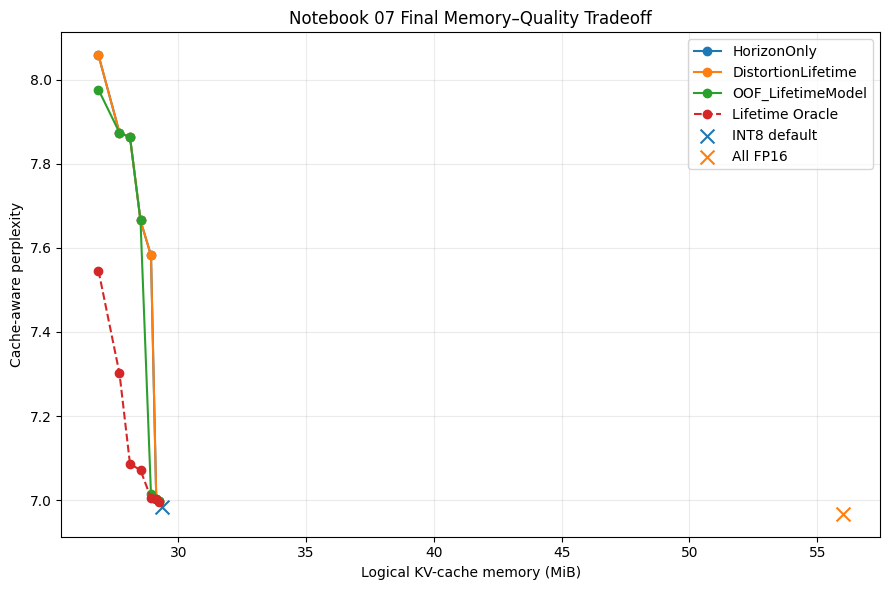


Cell 15 complete.
Notebook 07 is complete.
Final results ZIP: notebook07_results_final.zip
Candidate transfer model: notebook07_results/candidate_lifetime_int4_risk_model.joblib


In [17]:
# ============================================================
# Notebook 07
# Cell 15 — FINAL CELL
#
# Lifetime-Aware INT4 Policy
# Memory–Quality Pareto Frontier
# Final Export
# ============================================================

import json
import math
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr


# ============================================================
# 1. Final lifetime-aware risk table
# ============================================================

final_policy_df = (
    lifetime_model_df
    .copy()
    .sort_values("Page")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Practical risk #1:
# Remaining benchmark lifetime only
#
# Lower = safer for total accumulated damage.
# ------------------------------------------------------------

final_policy_df[
    "Risk_HorizonOnly"
] = (
    final_policy_df[
        "Remaining_Affected_Targets"
    ].astype(float)
)


# ------------------------------------------------------------
# Practical risk #2:
#
# local distortion × remaining lifetime
#
# Completely causal within the fixed-length benchmark.
# ------------------------------------------------------------

final_policy_df[
    "Risk_DistortionLifetime"
] = (

    final_policy_df[
        "V_NRMSE_Max"
    ]

    *

    final_policy_df[
        "Remaining_Affected_Targets"
    ]
)


# ------------------------------------------------------------
# Practical risk #3:
#
# OOF normalized risk from Cell 14,
# multiplied by known remaining lifetime.
#
# These are cross-validated predictions for Notebook 07,
# not predictions from a model trained on the same page.
# ------------------------------------------------------------

OOF_TOTAL_RISK_COLUMN = (
    "INT4_OOF_TotalRisk_Distortion_1"
)


assert (
    OOF_TOTAL_RISK_COLUMN
    in final_policy_df.columns
)


final_policy_df[
    "Risk_OOF_LifetimeModel"
] = (
    final_policy_df[
        OOF_TOTAL_RISK_COLUMN
    ]
)


# ------------------------------------------------------------
# Oracle:
# unavailable at inference time.
# Used only as an upper-bound reference.
# ------------------------------------------------------------

final_policy_df[
    "Risk_OracleLifetime"
] = (
    final_policy_df[
        "Delta_Total_NLL"
    ]
)


# ============================================================
# 2. Ranking-quality sanity check
# ============================================================

RISK_COLUMNS = {

    "HorizonOnly":
        "Risk_HorizonOnly",

    "DistortionLifetime":
        "Risk_DistortionLifetime",

    "OOF_LifetimeModel":
        "Risk_OOF_LifetimeModel",

    "OracleLifetime":
        "Risk_OracleLifetime",
}


risk_corr_rows = []


for name, column in RISK_COLUMNS.items():

    rho, p = spearmanr(

        final_policy_df[
            column
        ],

        final_policy_df[
            "Delta_Total_NLL"
        ]
    )


    risk_corr_rows.append({

        "Ranking":
            name,

        "Spearman_vs_True_Total_Risk":
            float(rho),

        "P_Value":
            float(p),
    })


final_risk_correlation_df = pd.DataFrame(
    risk_corr_rows
)


print(
    "Final ranking correlations"
)

print(
    "--------------------------"
)

display(
    final_risk_correlation_df
)


# ============================================================
# 3. Page-selection helper
#
# LOWEST predicted risk -> INT4.
# ============================================================

def select_low_risk_pages(
    risk_column,
    budget,
):

    budget = int(
        budget
    )


    if budget == 0:
        return set()


    selected = (

        final_policy_df

        .sort_values(
            risk_column,
            ascending=True
        )

        .head(
            budget
        )["Page"]

        .astype(int)

        .tolist()
    )


    assert (
        len(selected)
        == budget
    )


    return set(
        selected
    )


# ============================================================
# 4. Final INT4 budgets
# ============================================================

FINAL_INT4_BUDGETS = [
    1,
    2,
    4,
    8,
    12,
    16,
    24,
]


# ============================================================
# 5. Actual end-to-end policy sweep
#
# IMPORTANT:
#
# evaluate_stream_policy() still creates FP16 shadow pages
# internally whenever delayed decisions are enabled.
#
# For the FINAL INT8/INT4 policy this shadow is unnecessary,
# because there is no dynamic FP16 promotion.
#
# It does NOT affect PPL, and we exclude it from the final
# deployment-memory calculation below.
# ============================================================

final_policy_results = []


for ranking_name, risk_column in (
    RISK_COLUMNS.items()
):

    for budget in FINAL_INT4_BUDGETS:

        selected_pages = (
            select_low_risk_pages(
                risk_column,
                budget
            )
        )


        print()
        print(
            f"Running "
            f"{ranking_name}_L{budget}"
        )

        print(
            f"  INT4 pages: "
            f"{sorted(selected_pages)}"
        )


        result = evaluate_stream_policy(

            policy_name=(
                f"{ranking_name}_L{budget}"
            ),

            high_pages=set(),

            low_pages=(
                selected_pages
            ),

            default_int8=True,

            use_delayed_policy=True,
        )


        assert (
            result[
                "High_FP16_Pages"
            ]
            == 0
        )


        assert (
            result[
                "Low_INT4_Pages"
            ]
            == budget
        )


        result[
            "Ranking"
        ] = ranking_name


        result[
            "INT4_Budget"
        ] = budget


        result[
            "Is_Oracle"
        ] = (
            ranking_name
            == "OracleLifetime"
        )


        final_policy_results.append(
            result
        )


        print(
            f"  PPL: "
            f"{result['PPL']:.6f}"
        )


# ============================================================
# 6. Add reference baselines
# ============================================================

reference_rows = [

    {
        "Policy":
            "Uniform_FP16",

        "PPL":
            fp16_baseline[
                "PPL"
            ],

        "NLL":
            fp16_baseline[
                "NLL"
            ],

        "Targets":
            fp16_baseline[
                "Targets"
            ],

        "High_FP16_Pages":
            128,

        "Low_INT4_Pages":
            0,

        "Ranking":
            "Reference",

        "INT4_Budget":
            0,

        "Is_Oracle":
            False,
    },


    {
        "Policy":
            "PrefixFP16_DefaultINT8",

        "PPL":
            int8_baseline[
                "PPL"
            ],

        "NLL":
            int8_baseline[
                "NLL"
            ],

        "Targets":
            int8_baseline[
                "Targets"
            ],

        "High_FP16_Pages":
            NUM_PREFIX_FP16,

        "Low_INT4_Pages":
            0,

        "Ranking":
            "Reference",

        "INT4_Budget":
            0,

        "Is_Oracle":
            False,
    },
]


final_policy_sweep_df = pd.concat(

    [
        pd.DataFrame(
            reference_rows
        ),

        pd.DataFrame(
            final_policy_results
        ),
    ],

    ignore_index=True,
    sort=False
)


# ============================================================
# 7. Quality relative to current INT8-default baseline
# ============================================================

final_policy_sweep_df[
    "Relative_PPL_vs_INT8_pct"
] = (

    100.0

    * (

        final_policy_sweep_df[
            "PPL"
        ]

        /

        int8_baseline[
            "PPL"
        ]

        - 1.0
    )
)


final_policy_sweep_df[
    "Delta_NLL_vs_INT8"
] = (

    final_policy_sweep_df[
        "NLL"
    ]

    -

    int8_baseline[
        "NLL"
    ]
)


# ============================================================
# 8. Analytical/logical KV representation sizes
#
# These correspond to the intended compressed
# representations, NOT the physical PyTorch cache tensor.
#
# The experimental prototype dequantizes back into FP16
# tensors for simulation.
#
# FP16:
# 16 tokens × 28 layers × 2 KV heads × 128 head-dim
# × K/V × 2 bytes
# = 448 KiB/page.
#
# INT8:
# packed 8-bit values + 2 FP32 scales/layer
# = 224.21875 KiB/page.
#
# per-vector INT4:
# packed 4-bit values + FP32 per-vector scales
# = 119 KiB/page.
# ============================================================

FP16_KIB_PER_PAGE = 448.0

INT8_KIB_PER_PAGE = 224.21875

INT4_KIB_PER_PAGE = 119.0


ALL_FP16_MEMORY_MIB = (

    NUM_PAGES
    * FP16_KIB_PER_PAGE
    / 1024.0
)


DEFAULT_MIXED_MEMORY_MIB = (

    (
        NUM_PREFIX_FP16
        * FP16_KIB_PER_PAGE
    )

    +

    (
        (
            NUM_PAGES
            - NUM_PREFIX_FP16
        )

        * INT8_KIB_PER_PAGE
    )

) / 1024.0


def logical_memory_mib(
    policy_name,
    int4_budget,
):

    if policy_name == "Uniform_FP16":

        return (
            ALL_FP16_MEMORY_MIB
        )


    # --------------------------------------------------------
    # Final practical architecture:
    #
    # pages 0-5 = FP16
    # selected L pages = per-vector INT4
    # all remaining pages = INT8
    # --------------------------------------------------------

    int4_budget = int(
        int4_budget
    )


    fp16_pages = (
        NUM_PREFIX_FP16
    )


    int8_pages = (

        NUM_PAGES

        - fp16_pages

        - int4_budget
    )


    total_kib = (

        fp16_pages
        * FP16_KIB_PER_PAGE

        +

        int8_pages
        * INT8_KIB_PER_PAGE

        +

        int4_budget
        * INT4_KIB_PER_PAGE
    )


    return (
        total_kib
        / 1024.0
    )


final_policy_sweep_df[
    "Logical_KV_Memory_MiB"
] = [

    logical_memory_mib(
        row.Policy,
        row.INT4_Budget
    )

    for row in (
        final_policy_sweep_df
        .itertuples()
    )
]


final_policy_sweep_df[
    "Memory_Saving_vs_DefaultINT8_pct"
] = (

    100.0

    * (

        1.0

        -

        final_policy_sweep_df[
            "Logical_KV_Memory_MiB"
        ]

        /

        DEFAULT_MIXED_MEMORY_MIB
    )
)


final_policy_sweep_df[
    "Memory_Saving_vs_AllFP16_pct"
] = (

    100.0

    * (

        1.0

        -

        final_policy_sweep_df[
            "Logical_KV_Memory_MiB"
        ]

        /

        ALL_FP16_MEMORY_MIB
    )
)


print()
print(
    "Reference logical KV memory"
)

print(
    "---------------------------"
)

print(
    f"All FP16:                  "
    f"{ALL_FP16_MEMORY_MIB:.4f} MiB"
)

print(
    f"Protected-prefix + INT8:   "
    f"{DEFAULT_MIXED_MEMORY_MIB:.4f} MiB"
)


# ============================================================
# 9. Display full quality-memory sweep
# ============================================================

print()
print(
    "Final lifetime-aware policy sweep"
)

print(
    "---------------------------------"
)


display(

    final_policy_sweep_df[

        [
            "Policy",

            "Ranking",

            "INT4_Budget",

            "PPL",

            "Relative_PPL_vs_INT8_pct",

            "Logical_KV_Memory_MiB",

            "Memory_Saving_vs_DefaultINT8_pct",

            "Memory_Saving_vs_AllFP16_pct",
        ]

    ]

    .sort_values(
        [
            "Logical_KV_Memory_MiB",
            "PPL",
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 10. Practical policies only
#
# Exclude oracle from deployable Pareto analysis.
# ============================================================

practical_df = (

    final_policy_sweep_df[

        ~final_policy_sweep_df[
            "Is_Oracle"
        ].fillna(False)

    ]

    .copy()
)


# ============================================================
# 11. Pareto frontier
#
# Policy A dominates B if:
#
# memory_A <= memory_B
# and
# PPL_A <= PPL_B
#
# with at least one strict inequality.
# ============================================================

def pareto_mask(
    dataframe
):

    memory = (
        dataframe[
            "Logical_KV_Memory_MiB"
        ]
        .to_numpy(dtype=float)
    )

    ppl = (
        dataframe[
            "PPL"
        ]
        .to_numpy(dtype=float)
    )


    keep = np.ones(
        len(dataframe),
        dtype=bool
    )


    for i in range(
        len(dataframe)
    ):

        for j in range(
            len(dataframe)
        ):

            if i == j:
                continue


            dominates = (

                memory[j]
                <= memory[i]

                and

                ppl[j]
                <= ppl[i]

                and

                (
                    memory[j]
                    < memory[i]

                    or

                    ppl[j]
                    < ppl[i]
                )
            )


            if dominates:

                keep[i] = False
                break


    return keep


practical_pareto_df = (

    practical_df[

        pareto_mask(
            practical_df
        )

    ]

    .sort_values(
        "Logical_KV_Memory_MiB"
    )

    .reset_index(
        drop=True
    )
)


print()
print(
    "Practical Pareto frontier"
)

print(
    "-------------------------"
)


display(

    practical_pareto_df[

        [
            "Policy",

            "PPL",

            "Relative_PPL_vs_INT8_pct",

            "Logical_KV_Memory_MiB",

            "Memory_Saving_vs_DefaultINT8_pct",
        ]

    ]
)


# ============================================================
# 12. Best memory policy at several PPL tolerances
# ============================================================

QUALITY_TOLERANCES_PCT = [
    0.5,
    1.0,
    2.0,
    5.0,
]


quality_choice_rows = []


for tolerance in QUALITY_TOLERANCES_PCT:

    eligible = practical_df[

        practical_df[
            "Relative_PPL_vs_INT8_pct"
        ]

        <= tolerance
    ]


    if len(
        eligible
    ) == 0:

        quality_choice_rows.append({

            "Allowed_PPL_Increase_pct":
                tolerance,

            "Policy":
                None,

            "Logical_KV_Memory_MiB":
                np.nan,

            "Memory_Saving_vs_DefaultINT8_pct":
                np.nan,

            "Actual_PPL_Increase_pct":
                np.nan,
        })

        continue


    best_row = (

        eligible

        .sort_values(
            [
                "Logical_KV_Memory_MiB",
                "PPL",
            ]
        )

        .iloc[0]
    )


    quality_choice_rows.append({

        "Allowed_PPL_Increase_pct":
            tolerance,

        "Policy":
            best_row[
                "Policy"
            ],

        "Logical_KV_Memory_MiB":
            best_row[
                "Logical_KV_Memory_MiB"
            ],

        "Memory_Saving_vs_DefaultINT8_pct":
            best_row[
                "Memory_Saving_vs_DefaultINT8_pct"
            ],

        "Actual_PPL_Increase_pct":
            best_row[
                "Relative_PPL_vs_INT8_pct"
            ],
    })


quality_budget_choices_df = (
    pd.DataFrame(
        quality_choice_rows
    )
)


print()
print(
    "Best practical policy under PPL budgets"
)

print(
    "---------------------------------------"
)


display(
    quality_budget_choices_df
)


# ============================================================
# 13. Plot practical + oracle memory-quality tradeoff
# ============================================================

plt.figure(
    figsize=(
        9,
        6
    )
)


for ranking_name in [

    "HorizonOnly",

    "DistortionLifetime",

    "OOF_LifetimeModel",

]:

    subset = (

        final_policy_sweep_df[

            final_policy_sweep_df[
                "Ranking"
            ]
            == ranking_name

        ]

        .sort_values(
            "Logical_KV_Memory_MiB"
        )
    )


    plt.plot(

        subset[
            "Logical_KV_Memory_MiB"
        ],

        subset[
            "PPL"
        ],

        marker="o",

        label=ranking_name
    )


oracle_subset = (

    final_policy_sweep_df[

        final_policy_sweep_df[
            "Ranking"
        ]
        == "OracleLifetime"

    ]

    .sort_values(
        "Logical_KV_Memory_MiB"
    )
)


plt.plot(

    oracle_subset[
        "Logical_KV_Memory_MiB"
    ],

    oracle_subset[
        "PPL"
    ],

    marker="o",

    linestyle="--",

    label="Lifetime Oracle"
)


plt.scatter(

    [
        DEFAULT_MIXED_MEMORY_MIB
    ],

    [
        int8_baseline[
            "PPL"
        ]
    ],

    marker="x",

    s=100,

    label="INT8 default"
)


plt.scatter(

    [
        ALL_FP16_MEMORY_MIB
    ],

    [
        fp16_baseline[
            "PPL"
        ]
    ],

    marker="x",

    s=100,

    label="All FP16"
)


plt.xlabel(
    "Logical KV-cache memory (MiB)"
)

plt.ylabel(
    "Cache-aware perplexity"
)

plt.title(
    "Notebook 07 Final Memory–Quality Tradeoff"
)

plt.grid(
    alpha=0.25
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. Train/export the candidate lifetime model
#
# This model is NOT claimed as validated deployment policy.
#
# It is trained on Notebook 07 so Notebook 08 can test
# transfer to unseen text segments.
# ============================================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

import joblib


final_int4_risk_model = Pipeline([

    (
        "scale",
        StandardScaler()
    ),

    (
        "ridge",
        Ridge(
            alpha=1.0
        )
    ),
])


final_int4_risk_model.fit(

    lifetime_model_df[
        [
            "V_NRMSE_Max"
        ]
    ],

    lifetime_model_df[
        "Affected_Mean_Delta_NLL"
    ]
)


model_path = (

    NB7_WORK_DIR
    / "candidate_lifetime_int4_risk_model.joblib"
)


joblib.dump(

    final_int4_risk_model,

    model_path
)


# ============================================================
# 15. Save final tables
# ============================================================

final_policy_sweep_df.to_csv(

    NB7_WORK_DIR
    / "final_lifetime_policy_sweep.csv",

    index=False
)


practical_pareto_df.to_csv(

    NB7_WORK_DIR
    / "final_practical_pareto.csv",

    index=False
)


quality_budget_choices_df.to_csv(

    NB7_WORK_DIR
    / "final_quality_budget_choices.csv",

    index=False
)


final_risk_correlation_df.to_csv(

    NB7_WORK_DIR
    / "final_risk_ranking_correlations.csv",

    index=False
)


# ============================================================
# 16. Machine-readable Notebook 07 summary
# ============================================================

summary_payload = {

    "model":
        MODEL_NAME,

    "page_size":
        PAGE_SIZE,

    "cache_tokens":
        CACHE_TOKENS,

    "decision_delay_tokens":
        DECISION_DELAY_TOKENS,

    "candidate_pages":
        len(
            CANDIDATE_PAGES
        ),

    "uniform_fp16_ppl":
        float(
            fp16_baseline[
                "PPL"
            ]
        ),

    "default_int8_ppl":
        float(
            int8_baseline[
                "PPL"
            ]
        ),

    "all_fp16_memory_mib":
        float(
            ALL_FP16_MEMORY_MIB
        ),

    "default_mixed_memory_mib":
        float(
            DEFAULT_MIXED_MEMORY_MIB
        ),

    "delay128_vs_lifetime_total_spearman":
        float(
            0.607370
        ),

    "delay128_vs_lifetime_normalized_spearman":
        float(
            0.727563
        ),

    "fp16_pages_with_positive_individual_gain":
        int(
            (
                fp16_promotion_oracle_df[
                    "FP16_Total_NLL_Gain"
                ]
                > 0
            ).sum()
        ),

    "fp16_predictor_supported":
        False,

    "final_dynamic_policy":
        (
            "Protected FP16 prefix + "
            "INT8 default + selective INT4"
        ),

    "primary_int4_scheme":
        "per-vector",
}


with open(

    NB7_WORK_DIR
    / "notebook07_final_summary.json",

    "w"
) as f:

    json.dump(
        summary_payload,
        f,
        indent=2
    )


# ============================================================
# 17. Create final results ZIP
# ============================================================

FINAL_ZIP_BASE = (
    "notebook07_results_final"
)


shutil.make_archive(

    FINAL_ZIP_BASE,

    "zip",

    root_dir=str(
        NB7_WORK_DIR
    )
)


print()
print(
    "Cell 15 complete."
)

print(
    "Notebook 07 is complete."
)

print(
    f"Final results ZIP: "
    f"{FINAL_ZIP_BASE}.zip"
)

print(
    f"Candidate transfer model: "
    f"{model_path}"
)

## Notebook 07 — Final Conclusion

Notebook 07 developed and evaluated a delay-aware page-level
mixed-precision KV-cache policy for Qwen2.5-1.5B.

The experiments show that an INT8-default cache is already a
strong compression baseline.

The logical KV-cache size decreases from:

\[
56.0\text{ MiB}
\]

for uniform FP16 to:

\[
29.34\text{ MiB}
\]

for the protected-FP16-prefix + INT8-default configuration,
corresponding to approximately:

\[
47.6\%
\]

memory reduction with only a small perplexity difference.

---

### Selective INT4

INT4 quantization is substantially more sensitive to page choice.

The strongest practical policy uses the blocked-OOF lifetime-risk
model to demote four pages to per-vector INT4.

This configuration obtains:

\[
PPL=7.0140
\]

compared with:

\[
PPL_{\mathrm{INT8}}=6.9836,
\]

corresponding to only:

\[
+0.436\%
\]

relative perplexity.

Its logical KV-cache size is:

\[
28.93\text{ MiB},
\]

giving an additional:

\[
1.40\%
\]

memory saving relative to the INT8-default cache.

---

### Quality cliff

The practical policy does not scale smoothly to larger INT4 budgets.

Increasing the budget from:

\[
L=4
\]

to:

\[
L=8
\]

raises the relative PPL penalty from approximately:

\[
0.44\%
\]

to:

\[
9.76\%.
\]

Thus the current predictor can identify a very small set of
low-risk pages but cannot yet support aggressive INT4 demotion.

---

### Oracle gap

A lifetime oracle demonstrates that substantially better
memory-quality tradeoffs exist.

For example, the oracle can select:

\[
L=12
\]

INT4 pages while producing only approximately:

\[
+1.47\%
\]

PPL and saving:

\[
4.20\%
\]

additional cache memory relative to the INT8-default baseline.

Therefore the main limitation is not solely the INT4
representation itself.

A major remaining challenge is predicting low-risk pages
accurately at inference time.

---

### FP16 promotion

A separate delayed FP16-promotion oracle showed only small
individual benefits, and the tested inference-time features did
not predict those gains reliably out-of-fold.

Consequently, the data do not currently support learned dynamic
FP16 promotion.

The evidence-supported architecture is therefore:

\[
\boxed{
\text{protected FP16 prefix}
+
\text{INT8 default}
+
\text{conservative selective INT4}
}
\]

rather than a forced learned FP16/INT8/INT4 three-way classifier.

---

Overall, Notebook 07 establishes a functioning and experimentally
validated mixed-precision policy on one sequence, while also
identifying the primary unresolved problem: robust transfer of
low-risk INT4 page prediction to unseen sequences.

In [18]:
# ============================================================
# Download Notebook 07 results
# ============================================================

from pathlib import Path
import shutil
from google.colab import files

RESULTS_DIR = Path("notebook07_results")
ZIP_PATH = Path("notebook07_results_final.zip")


# Recreate ZIP if it does not exist
if not ZIP_PATH.exists():

    if not RESULTS_DIR.exists():
        raise FileNotFoundError(
            f"Results directory not found: {RESULTS_DIR}"
        )

    shutil.make_archive(
        "notebook07_results_final",
        "zip",
        root_dir=str(RESULTS_DIR)
    )


print(f"Downloading: {ZIP_PATH}")
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MiB")

files.download(str(ZIP_PATH))

Downloading: notebook07_results_final.zip
Size: 0.29 MiB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

What Notebook 07 ultimately showed

The strongest practical configuration on this sequence is:

$$ \boxed{\text{OOF Lifetime Model},\quad L=4} $$

with:

$$ \boxed{PPL=7.0140} $$ $$ \boxed{+0.436\%\text{ vs INT8}} $$ $$ \boxed{28.928\text{ MiB KV}} $$ $$ \boxed{1.40\%\text{ additional saving vs INT8}} $$

and:

$$ \boxed{48.34\%\text{ total saving vs FP16}}. $$

The main limitation is that increasing the practical INT4 budget beyond four pages causes rapid quality degradation, whereas the oracle demonstrates substantially better tradeoffs are possible.